# Trabajo Final Integrador — Ciencia de Datos para Economistas (2026-2)
## Determinantes del Sobrecosto Logístico Internacional, Carga Tributaria Aduanera y Tipología Estructural de las Importaciones Peruanas: Evidencia con Microdatos de SUNAT (Setiembre–Noviembre 2026)

---

| Campo | Detalle |
| :--- | :--- |
| **Universidad / Facultad** | Universidad de Lima — Facultad de Economía — Carrera de Economía |
| **Asignatura / Período** | Ciencia de Datos para Economistas — Período Académico **2026-2** |
| **Docente** | Angel Agüero Correa |
| **Equipo** | **Grupo 9:** Integrante 1, Integrante 2, Integrante 3, Integrante 4 |
| **Fuente oficial** | SUNAT — Portal de Operatividad Aduanera: Importación Definitiva (Formato A, `ma`) y 8 Catálogos Oficiales (`aduanet.gob.pe`) |
| **Repositorio remoto (espejo inalterado)** | `https://github.com/jshez612/sunat-importaciones-grupo9` (`datos_crudos/`) |
| **Cobertura y período** | Cobertura nacional (todas las intendencias de aduana del Perú) — 10 semanas consecutivas del **07/09/2026 al 15/11/2026** |
| **Volumen inicial exacto** | **3,155,169 registros × 58 variables** (185.32 MB en `.zip`, ~2.68 GB en `.DBF` descomprimido) |
| **Licencia y uso** | Datos públicos administrativos difundidos por SUNAT al amparo del Art. 1 de la **Ley N° 27806** (Ley de Transparencia y Acceso a la Información Pública). Uso estrictamente académico. Fecha de respaldo: 2026-11-22. |
| **Entorno de ejecución** | **Google Colab** (100% procesamiento sustantivo en la nube; semilla fija `random_state = 2026`) |

> **Nota expresa de trazabilidad sobre aprobación docente:** El docente Angel Agüero Correa validó en clase la propuesta de trabajar con microdatos administrativos de SUNAT bajo la condición estricta de superar los **2,000,000 de registros**. Se remitió el correo formal solicitando la aprobación escrita de la base *Importación Definitiva Formato A (`ma`)* y de su espejo crudo e inalterado en GitHub (necesario porque SUNAT elimina los archivos semanales tras dos meses); a la fecha de generación de este notebook queda pendiente únicamente la confirmación escrita formal del docente. Tanto la base inicial (`3,155,169` filas) como la base final limpia (`> 2,000,000` filas verificadas mediante aserción explícita) cumplen el umbral de volumen exigido.

---

### 1.1 Planteamiento del problema económico, pregunta central e impacto esperado

El Perú es una economía pequeña y abierta integrada a cadenas globales de valor mediante más de veinte acuerdos comerciales vigentes (TLC con Estados Unidos, China, Unión Europea, CPTPP, Alianza del Pacífico, entre otros). Si bien las reformas arancelarias redujeron el arancel promedio nominal, la evidencia de la economía del comercio internacional —desde los *costos de transporte tipo iceberg* de **Samuelson (1954)** hasta las estimaciones modernas de fricciones comerciales de **Anderson & van Wincoop (2004)**, **Hummels (2007)** y **Limão & Venables (2001)**— demuestra que los **costos logísticos internacionales (flete + seguro ad valorem)** constituyen frecuentemente una barrera real mayor que el propio arancel aduanero, afectando la competitividad industrial, la formación de precios internos y la recaudación tributaria (dado que en el Perú la base imponible del Ad Valorem, IGV e IPM es el **Valor CIF = FOB + Flete + Seguro**).

* **Pregunta central de investigación:**
  > *¿Qué factores económicos, logísticos, arancelarios y geográficos determinan y permiten predecir el **sobrecosto logístico internacional ad valorem** `((Flete + Seguro) / FOB)` y la probabilidad de enfrentar un **sobrecosto logístico elevado** en las importaciones definitivas del Perú (setiembre–noviembre 2026), y qué tipologías estructurales de operaciones importadoras emergen al contrastar las seis familias de clustering?*

* **Unidad de análisis:** Cada serie declarada dentro de una Declaración Aduanera de Mercancías (DAM/DUI) bajo el régimen de Importación Definitiva (Formato A), identificada por `(CODI_ADUAN, ANO_PRESE, NUME_CORRE, NUME_SERIE)`.
* **Objetivos específicos y medibles:**
  1. **Trazabilidad y calidad:** Descargar, auditar y limpiar remotamente en Google Colab los 10 bloques semanales de SUNAT y los 8 catálogos oficiales, exportando `Base_Inicial_Grupo_9.parquet` (cruda íntegra) y `Base_Final_Grupo_9.parquet` (`> 2,000,000` filas).
  2. **Contraste de hipótesis económicas (EDA):** Evaluar empíricamente cuatro hipótesis derivadas de la teoría comercial:
     * *H1 (Efecto Alchian–Allen):* Las mercancías con mayor valor unitario por kilogramo (`FOB / Peso Neto`) exhiben menor tasa logística ad valorem.
     * *H2 (Brecha modal):* El transporte aéreo presenta una tasa logística mediana y una densidad de valor significativamente superiores al transporte marítimo y terrestre.
     * *H3 (Asimetría geográfica y aduanera):* Existen brechas persistentes de sobrecosto logístico según región/país de origen y concentración portuaria/aeroportuaria en el Callao.
     * *H4 (Efecto de preferencias TLC):* Las operaciones acogidas a trato preferencial (`TRAT_PREFE > 0`) registran una tasa arancelaria Ad Valorem efectiva sustancialmente menor que las sujetas a régimen general.
  3. **Modelado supervisado sin fuga de información (base completa `> 2M` filas):** Predecir la tasa logística continua (`log1p(TASA_LOGISTICA_PCT)`) y clasificar operaciones de alto sobrecosto (`TASA_LOGISTICA_PCT >= 20%`, clase desbalanceada) mediante validación temporal *out-of-time* (semanas 1–8 entrenamiento → semanas 9–10 prueba) y validación cruzada 5-fold.
  4. **Modelado no supervisado integral (6 familias × 2 métodos = 12 algoritmos):** Comparar conceptual y empíricamente las seis familias de clustering, usar PCA exclusivamente como reducción de dimensionalidad y proyección `CP1–CP2`, evaluar concordancia vía Índice de Rand Ajustado (ARI) y perfilar segmentos en unidades originales con nombres económicos interpretables.
  5. **Comunicación accionable:** Generar desde Python el dashboard interactivo `Dashboard_Grupo_9.html` (incluyendo mapa mundial de orígenes e intendencias aduaneras del Perú), gráficos de alta resolución y métricas verificables para el informe académico y la sustentación.

* **Métricas de éxito definidas *a priori*:**
  * *Regresión:* Reducción sustancial de **RMSE** y **MAE** y mejora de **$R^2$** en el conjunto temporal futuro (semanas 9–10) frente a las líneas base Dummy y `Ridge`.
  * *Clasificación desbalanceada:* Desempeño superior en **PR-AUC (Average Precision)**, **ROC-AUC**, **F1-Score** y **Balanced Accuracy** frente a la línea base `LogisticRegression` (evitando depender del *Accuracy* simple).
  * *Clustering:* Coherencia entre métricas internas (**Silueta**, **Davies–Bouldin**, **Calinski–Harabasz**, **BIC/AIC**, **correlación cofenética**, **% de ruido**), estabilidad (**ARI** entre algoritmos y semillas bootstrap) y clara diferenciación económica en unidades originales.

---
## 2. Configuración del entorno

En esta sección se instalan únicamente las librerías auxiliares ligeras que no vienen preinstaladas en el entorno base de Google Colab (`dbfread` para verificación cruzada de lectura DBF, `xlrd` para leer los archivos oficiales `.xls` de SUNAT, `pycountry` para mapear códigos ISO-2 de países a ISO-3 en el mapa mundial, y `kmedoids` para FasterPAM en la Familia 1 de clustering). Se fija globalmente la semilla **`SEED = 2026`**, se documentan versiones exactas, se verifica la ejecución en la nube (Colab) y se definen utilidades modulares con manejo explícito de errores.

In [1]:
import os
import sys
import io
import gc
import json
import time
import math
import struct
import random
import zipfile
import warnings
import subprocess
from pathlib import Path
from datetime import datetime

warnings.filterwarnings("ignore")

# Instalación silenciosa y controlada de dependencias auxiliares en Colab
REQUIRED_PACKAGES = ["dbfread", "xlrd", "pycountry", "kmedoids"]
for pkg in REQUIRED_PACKAGES:
    try:
        __import__(pkg)
    except ImportError:
        print(f"Instalando paquete auxiliar: {pkg}...")
        res = subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", pkg],
            capture_output=True, text=True
        )
        if res.returncode != 0:
            print(f"  [Aviso] No se pudo instalar {pkg}: {res.stderr[:200]}")

import requests
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import scipy
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist, cdist

import sklearn
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score, median_absolute_error,
    roc_auc_score, average_precision_score, f1_score, precision_score,
    recall_score, balanced_accuracy_score, accuracy_score, confusion_matrix,
    roc_curve, precision_recall_curve, brier_score_loss,
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score
)
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import (
    KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN,
    SpectralClustering, AffinityPropagation, Birch
)
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.inspection import permutation_importance

import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

try:
    import pycountry
    HAS_PYCOUNTRY = True
except ImportError:
    HAS_PYCOUNTRY = False

try:
    import kmedoids
    HAS_KMEDOIDS = True
except ImportError:
    HAS_KMEDOIDS = False

# Semilla global reproducible (convención del curso)
SEED = 2026
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Verificación de entorno Google Colab
IN_COLAB = "google.colab" in sys.modules
OUT_DIR = Path("/content/entregables_colab") if IN_COLAB else Path("./entregables_colab")
FIG_DIR = OUT_DIR / "figuras"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Estilo gráfico académico uniforme
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
PALETTE_ULIMA = ["#0F2C59", "#E86A33", "#2E8B57", "#3A7CA5", "#C84B31", "#6C757D", "#8E44AD", "#D4AC0D"]
sns.set_palette(PALETTE_ULIMA)

# Repositorio remoto público (sin credenciales ni tokens)
BASE_RAW_URL = "https://raw.githubusercontent.com/jshez612/sunat-importaciones-grupo9/main/datos_crudos"

# Diccionario centralizado para exportar todas las métricas verificadas al informe
RESUMEN_METRICAS = {
    "meta": {
        "proyecto": "Trabajo Final Integrador — Ciencia de Datos para Economistas (2026-2)",
        "grupo": "Grupo 9",
        "integrantes": ["Integrante 1", "Integrante 2", "Integrante 3", "Integrante 4"],
        "docente": "Angel Agüero Correa",
        "ejecutado_en_colab": IN_COLAB,
        "fecha_ejecucion_utc": datetime.utcnow().strftime("%Y-%m-%d %H:%M:%S UTC"),
        "seed": SEED,
        "versiones": {
            "python": sys.version.split()[0],
            "numpy": np.__version__,
            "pandas": pd.__version__,
            "pyarrow": pa.__version__,
            "scikit_learn": sklearn.__version__,
            "lightgbm": lgb.__version__,
            "scipy": scipy.__version__,
            "plotly": plotly.__version__,
        }
    }
}

print("=" * 72)
print("ENTORNO CONFIGURADO CORRECTAMENTE")
print("=" * 72)
print(f"Ejecutando en Google Colab : {IN_COLAB}")
print(f"Semilla global             : {SEED}")
print(f"Directorio de salida       : {OUT_DIR}")
print(f"pycountry disponible       : {HAS_PYCOUNTRY} | kmedoids disponible: {HAS_KMEDOIDS}")
for k, v in RESUMEN_METRICAS["meta"]["versiones"].items():
    print(f"  - {k:14s}: {v}")

Instalando paquete auxiliar: dbfread...
Instalando paquete auxiliar: pycountry...
Instalando paquete auxiliar: kmedoids...
ENTORNO CONFIGURADO CORRECTAMENTE
Ejecutando en Google Colab : True
Semilla global             : 2026
Directorio de salida       : /content/entregables_colab
pycountry disponible       : True | kmedoids disponible: True
  - python        : 3.13.18
  - numpy         : 2.4.6
  - pandas        : 2.2.3
  - pyarrow       : 23.0.1
  - scikit_learn  : 1.6.1
  - lightgbm      : 4.6.0
  - scipy         : 1.16.3
  - plotly        : 5.24.1


### 2.1 Funciones modulares reutilizables (descarga remota, lectura DBF vectorizada y catálogos SUNAT)

Debido a que los 10 archivos semanales suman **3,155,169 registros × 58 columnas** (~2.68 GB descomprimidos en formato dBase `.DBF`), una lectura fila por fila en Python puro tardaría más de 10 minutos y consumiría exceso de memoria. Para garantizar eficiencia y reproducibilidad dentro de los límites de RAM de Google Colab:
1. Se implementa `read_dbf_vectorized()`, un lector binario estructurado con `struct` y `numpy.frombuffer` que interpreta exactamente la cabecera DBF (longitud de cabecera, longitud de registro, bandera de borrado `0x2A` y ancho fijo de cada uno de los 58 campos) en cuestión de segundos.
2. En la Sección 3 se ejecuta una **verificación cruzada fila por fila** contra la librería estándar `dbfread` sobre registros de muestra para demostrar equivalencia exacta del 100%.
3. Cada función incorpora reintentos HTTP y manejo explícito de excepciones.

In [2]:
def download_remote_bytes(filename: str, base_url: str = BASE_RAW_URL, retries: int = 3, timeout: int = 120) -> bytes:
    """Descarga un archivo remoto desde el espejo público en GitHub con reintentos."""
    url = f"{base_url}/{filename}"
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            resp = requests.get(url, timeout=timeout)
            resp.raise_for_status()
            return resp.content
        except Exception as exc:
            last_err = exc
            print(f"  [Reintento {attempt}/{retries}] Error descargando {filename}: {exc}")
            time.sleep(2 * attempt)
    raise RuntimeError(f"Fallo definitivo al descargar {url}: {last_err}")


def parse_sunat_catalog(zip_filename: str, mode: str = "standard") -> pd.DataFrame:
    """Descarga y decodifica un catálogo oficial .zip/.txt de SUNAT priorizando registros vigentes."""
    raw_zip = download_remote_bytes(zip_filename)
    with zipfile.ZipFile(io.BytesIO(raw_zip)) as zf:
        txt_name = zf.namelist()[0]
        raw_text = zf.read(txt_name).decode("latin-1", errors="replace")

    lines = [ln for ln in raw_text.splitlines() if ln.strip()]
    if mode == "standard":
        rows = []
        for ln in lines[1:]:
            parts = ln.split("\t")
            if len(parts) >= 2:
                codigo = parts[0].strip()
                desc = parts[1].strip()
                vig = parts[4].strip() if len(parts) >= 5 else "Vigente"
                rows.append((codigo, desc, vig))
        cat = pd.DataFrame(rows, columns=["codigo", "descripcion", "vigencia"])
        cat["es_vigente"] = (cat["vigencia"].str.upper() == "VIGENTE").astype(int)
        cat = cat.sort_values(["codigo", "es_vigente"], ascending=[True, False])
        cat = cat.drop_duplicates(subset=["codigo"], keep="first").reset_index(drop=True)
        return cat
    elif mode == "tablibe":
        rows = []
        for ln in lines[1:]:
            parts = ln.split("\t")
            if len(parts) >= 3:
                rows.append((parts[0].strip(), parts[1].strip(), parts[2].strip()))
        cat = pd.DataFrame(rows, columns=["tlib", "codigo", "descripcion"])
        cat = cat.drop_duplicates(subset=["codigo"], keep="first").reset_index(drop=True)
        return cat
    elif mode == "puertos":
        rows = []
        for ln in lines[1:]:
            parts = ln.split("\t")
            if len(parts) >= 4:
                cpais = parts[0].strip()
                dpais = parts[1].strip()
                cpuerto = parts[2].strip()
                dpuerto = parts[3].strip()
                vig = parts[6].strip() if len(parts) >= 7 else "Vigente"
                rows.append((cpais + cpuerto, cpais, dpais, cpuerto, dpuerto, vig))
        cat = pd.DataFrame(rows, columns=["codigo", "cpais", "dpais", "cpuerto", "dpuerto", "vigencia"])
        cat["es_vigente"] = (cat["vigencia"].str.upper() == "VIGENTE").astype(int)
        cat = cat.sort_values(["codigo", "es_vigente"], ascending=[True, False])
        cat = cat.drop_duplicates(subset=["codigo"], keep="first").reset_index(drop=True)
        return cat
    else:
        raise ValueError(f"Modo de catálogo no reconocido: {mode}")


def read_dbf_vectorized(dbf_bytes: bytes):
    """
    Lector DBF binario vectorizado (dBase III/IV) usando numpy.frombuffer.
    Retorna: (dict_col_arrays, fields_meta, n_total_raw, n_deleted_dbf)
    """
    ver, yy, mm, dd, nrec, hdr_len, rec_len = struct.unpack("<BBBBIHH", dbf_bytes[:12])
    fields = []
    pos = 32
    while pos + 32 <= hdr_len and dbf_bytes[pos] != 0x0D:
        fdesc = dbf_bytes[pos:pos + 32]
        fname = fdesc[:11].split(b"\x00")[0].decode("ascii", errors="replace").strip()
        ftype = chr(fdesc[11])
        flen = fdesc[16]
        fdec = fdesc[17]
        fields.append((fname, ftype, flen, fdec))
        pos += 32

    data_buf = memoryview(dbf_bytes)[hdr_len:]
    max_possible = len(data_buf) // rec_len
    actual_nrec = min(nrec, max_possible)
    data_buf = data_buf[:actual_nrec * rec_len]

    dt = np.dtype([("_del", "S1")] + [(f[0], f"S{f[2]}") for f in fields])
    arr = np.frombuffer(data_buf, dtype=dt, count=actual_nrec)

    deleted_mask = arr["_del"] == b"*"
    n_deleted = int(deleted_mask.sum())
    if n_deleted > 0:
        arr = arr[~deleted_mask]

    return arr, fields, actual_nrec, n_deleted


def parse_dbf_numeric_col(raw_bytes_arr: np.ndarray, is_float: bool = True) -> np.ndarray:
    """Convierte un arreglo de bytes de ancho fijo DBF numérico a float64/float32 con NaN en vacíos."""
    s = pd.Series(raw_bytes_arr).str.decode("ascii", errors="ignore").str.strip()
    num = pd.to_numeric(s, errors="coerce")
    return num.to_numpy(dtype=np.float64 if is_float else np.float64)


def parse_dbf_str_col(raw_bytes_arr: np.ndarray) -> pd.Series:
    """Decodifica un arreglo de bytes DBF de texto latin-1 eliminando espacios extremos."""
    return pd.Series(raw_bytes_arr).str.decode("latin-1", errors="replace").str.strip()


def format_mem_mb(df: pd.DataFrame) -> float:
    """Retorna el uso real de memoria RAM en MB."""
    return float(df.memory_usage(deep=True).sum() / (1024 ** 2))

print("Funciones auxiliares cargadas y listas.")

Funciones auxiliares cargadas y listas.


---
## 3. Acceso remoto y carga reproducible desde GitHub

Todo el acceso a datos se realiza directamente por HTTPS desde el repositorio público espejo `jshez612/sunat-importaciones-grupo9/main/datos_crudos/` sin intervención manual ni preprocesamiento local.

El flujo de carga cumple tres garantías clave:
1. **Integración de metadatos oficiales:** Se descargan los **8 catálogos de SUNAT**, el diccionario oficial `estructura_bases.xls` y la tabla histórica de control `totales.xls`.
2. **Validación exacta del lector vectorizado:** Se comparan los primeros 100 registros de `ma07130926.DBF` leídos por `read_dbf_vectorized()` contra la librería `dbfread` para certificar 0 discrepancias.
3. **Exportación directa de la base inicial íntegra (`Base_Inicial_Grupo_9.parquet`):** Para preservar los **3,155,169 registros × 58 columnas originales** sin saturar la memoria RAM de Google Colab, cada bloque semanal se escribe secuencialmente en formato **Apache Parquet con compresión ZSTD** mediante `pyarrow.parquet.ParquetWriter`, mientras en RAM se mantiene el conjunto analítico optimizado en tipos de datos (extrayendo indicadores de las 5 columnas de texto libre `DESC_*` de 450 bytes/fila antes de liberarlas de RAM).

In [3]:
# 3.1 Descarga de los 8 catálogos oficiales de SUNAT y archivos .xls de documentación
CATALOG_SPECS = {
    "paises": ("Paises.zip", "standard"),
    "aduanas": ("Aduanas.zip", "standard"),
    "med_transporte": ("MedTransporte.zip", "standard"),
    "unid_medida": ("UnidMedida.zip", "standard"),
    "est_mercancia": ("EstMercancia.zip", "standard"),
    "documento": ("Documento.zip", "standard"),
    "tablibe": ("Tablibe.zip", "tablibe"),
    "puertos": ("Puertos.zip", "puertos"),
}

catalogos = {}
print("Descargando los 8 catálogos oficiales de SUNAT desde GitHub...")
for key, (fname, mode) in CATALOG_SPECS.items():
    catalogos[key] = parse_sunat_catalog(fname, mode=mode)
    print(f"  - {fname:20s} -> {len(catalogos[key]):>6,d} códigos únicos")

# Lectura de estructura_bases.xls (diccionario oficial SUNAT)
estr_bytes = download_remote_bytes("estructura_bases.xls")
df_estr_raw = pd.read_excel(io.BytesIO(estr_bytes), sheet_name="ESTRUCTURA", header=None, engine="xlrd")
official_desc_map = {}
for idx in range(6, 63):
    col_name = str(df_estr_raw.iloc[idx, 1]).strip()
    col_desc = str(df_estr_raw.iloc[idx, 6]).strip()
    if col_name and col_name != "nan":
        official_desc_map[col_name] = col_desc
# Corrección tipográfica conocida en el XLS oficial de SUNAT (QUINICOM -> QUNICOM) y campo añadido FECH_EMBAR
if "QUINICOM" in official_desc_map and "QUNICOM" not in official_desc_map:
    official_desc_map["QUNICOM"] = official_desc_map["QUINICOM"]
official_desc_map.setdefault("FECH_EMBAR", "FECHA DE EMBARQUE (campo presente en DBF 2026; añadido posteriormente al XLS histórico de 57 campos)")
print(f"\nDiccionario oficial leído de estructura_bases.xls: {len(official_desc_map)} definiciones cargadas.")

# Lectura de totales.xls (archivo de control histórico publicado por SUNAT)
tot_bytes = download_remote_bytes("totales.xls")
df_totales_xls = pd.read_excel(io.BytesIO(tot_bytes), sheet_name="resumen", engine="xlrd")
print(f"Archivo de control totales.xls leído: {df_totales_xls.shape[0]:,} filas históricas (rango fechas: {df_totales_xls['FINI'].min()} a {df_totales_xls['FFIN'].max()}).")

Descargando los 8 catálogos oficiales de SUNAT desde GitHub...
  - Paises.zip           ->    282 códigos únicos
  - Aduanas.zip          ->     60 códigos únicos
  - MedTransporte.zip    ->      7 códigos únicos
  - UnidMedida.zip       ->    101 códigos únicos
  - EstMercancia.zip     ->     27 códigos únicos
  - Documento.zip        ->     14 códigos únicos
  - Tablibe.zip          ->    413 códigos únicos
  - Puertos.zip          -> 35,045 códigos únicos

Diccionario oficial leído de estructura_bases.xls: 59 definiciones cargadas.
Archivo de control totales.xls leído: 1,214 filas históricas (rango fechas: 20020627 a 20110327).


In [4]:
# 3.2 Carga remota de las 10 semanas consecutivas (07/09/2026 - 15/11/2026)
# Exportación en streaming de Base_Inicial_Grupo_9.parquet (3,155,169 x 58 exacto)
# y construcción del DataFrame analítico en RAM.

from dbfread import DBF

WEEKLY_FILES = [
    ("S01", "ma07130926.zip", "2026-09-07", "2026-09-13"),
    ("S02", "ma14200926.zip", "2026-09-14", "2026-09-20"),
    ("S03", "ma21270926.zip", "2026-09-21", "2026-09-27"),
    ("S04", "ma28041026.zip", "2026-09-28", "2026-10-04"),
    ("S05", "ma05111026.zip", "2026-10-05", "2026-10-11"),
    ("S06", "ma12181026.zip", "2026-10-12", "2026-10-18"),
    ("S07", "ma19251026.zip", "2026-10-19", "2026-10-25"),
    ("S08", "ma26011126.zip", "2026-10-26", "2026-11-01"),
    ("S09", "ma02081126.zip", "2026-11-02", "2026-11-08"),
    ("S10", "ma09151126.zip", "2026-11-09", "2026-11-15"),
]

TEXT_HEAVY_COLS = ["DESC_COMER", "DESC_MATCO", "DESC_USOAP", "DESC_FOPRE", "DESC_OTROS"]
FLOAT_COLS = [
    "FOB_DOLPOL", "FLE_DOLAR", "SEG_DOLAR", "PESO_NETO", "PESO_BRUTO",
    "UNID_FIQTY", "QUNICOM", "ADV_DOLAR", "IGV_DOLAR", "ISC_DOLAR",
    "IPM_DOLAR", "DES_DOLAR", "IPA_DOLAR", "SAD_DOLAR", "DER_ADUM",
    "COMM", "CANT_BULTO"
]
INT_COLS = [
    "FECH_INGSI", "FECH_LLEGA", "VIA_TRANSP", "NUME_MANIF", "FECH_RECEP",
    "FECH_CANCE", "TIPO_CANCE", "FECH_EMBAR", "FMOD", "TRAT_PREFE",
    "TIPO_TRAT", "CODI_LIBER"
]
STR_ANALYTICAL_COLS = [
    "CODI_ADUAN", "ANO_PRESE", "NUME_CORRE", "TIPO_DOCUM", "LIBR_TRIBU",
    "DNOMBRE", "CODI_AGENT", "EMPR_TRANS", "CODI_ALMA", "CADU_MANIF",
    "FECH_MANIF", "BANC_CANCE", "CODI_ENFIN", "DK", "PAIS_ORIGE",
    "PAIS_ADQUI", "PUER_EMBAR", "NUME_SERIE", "PART_NANDI", "UNID_FIDES",
    "TUNICOM", "SEST_MERCA", "CLASE", "IMPR_RELIQ"
]

BASE_INICIAL_PATH = OUT_DIR / "Base_Inicial_Grupo_9.parquet"
if BASE_INICIAL_PATH.exists():
    BASE_INICIAL_PATH.unlink()

t0_global = time.time()
writer = None
fields_meta_global = None

# Acumuladores de auditoría inicial sobre las 58 columnas crudas
audit_null_counts = {}
audit_empty_counts = {}
audit_weekly_summary = []
raw_dbf_bytes_total = 0
raw_zip_bytes_total = 0
total_raw_rows = 0
total_deleted_dbf = 0
analytical_chunks = []

for w_idx, (sem_id, zname, f_ini, f_fin) in enumerate(WEEKLY_FILES, 1):
    t_w = time.time()
    zbytes = download_remote_bytes(zname)
    raw_zip_bytes_total += len(zbytes)

    with zipfile.ZipFile(io.BytesIO(zbytes)) as zf:
        dbf_name = [n for n in zf.namelist() if n.upper().endswith(".DBF")][0]
        dbf_bytes = zf.read(dbf_name)
    raw_dbf_bytes_total += len(dbf_bytes)

    # Verificación cruzada en la primera semana contra dbfread (100 filas exactas)
    if w_idx == 1:
        tmp_dbf_path = OUT_DIR / "_verify_sample.dbf"
        with open(tmp_dbf_path, "wb") as ftmp:
            ftmp.write(dbf_bytes)
        sample_dbfread = []
        for i_r, rec in enumerate(DBF(str(tmp_dbf_path), encoding="latin-1", char_decode_errors="replace")):
            sample_dbfread.append(rec)
            if i_r >= 99:
                break
        tmp_dbf_path.unlink(missing_ok=True)

    arr, fields_meta, n_raw, n_del = read_dbf_vectorized(dbf_bytes)
    if fields_meta_global is None:
        fields_meta_global = fields_meta
        for fname, _, _, _ in fields_meta:
            audit_null_counts[fname] = 0
            audit_empty_counts[fname] = 0

    total_raw_rows += n_raw
    total_deleted_dbf += n_del

    # Validar fidelidad 100% en semana 1 contra dbfread
    if w_idx == 1:
        mismatches = 0
        for i_r in range(100):
            fob_ref = float(sample_dbfread[i_r]["FOB_DOLPOL"] or 0.0)
            fob_vec = float(arr["FOB_DOLPOL"][i_r].decode("ascii").strip() or 0.0)
            pais_ref = str(sample_dbfread[i_r]["PAIS_ORIGE"]).strip()
            pais_vec = arr["PAIS_ORIGE"][i_r].decode("latin-1").strip()
            if abs(fob_ref - fob_vec) > 1e-6 or pais_ref != pais_vec:
                mismatches += 1
        assert mismatches == 0, f"Discrepancias detectadas contra dbfread: {mismatches}"
        print("[Verificación cruzada DBF] 100/100 registros coinciden exactamente entre lector vectorizado y dbfread.")

    # Construir diccionario de columnas crudas para Parquet Inicial (58 columnas exactas)
    raw_cols_dict = {}
    for fname, ftype, flen, fdec in fields_meta:
        col_bytes = arr[fname]
        if fname in FLOAT_COLS:
            vals = parse_dbf_numeric_col(col_bytes, is_float=True)
            audit_null_counts[fname] += int(np.isnan(vals).sum())
            raw_cols_dict[fname] = pa.array(vals, type=pa.float64())
        elif fname in INT_COLS:
            vals = parse_dbf_numeric_col(col_bytes, is_float=True)
            audit_null_counts[fname] += int(np.isnan(vals).sum())
            raw_cols_dict[fname] = pa.array(vals, type=pa.float64())
        else:
            s_col = parse_dbf_str_col(col_bytes)
            n_emp = int((s_col == "").sum())
            audit_empty_counts[fname] += n_emp
            raw_cols_dict[fname] = pa.array(s_col, type=pa.string())

    raw_table = pa.table(raw_cols_dict)
    if writer is None:
        writer = pq.ParquetWriter(str(BASE_INICIAL_PATH), raw_table.schema, compression="zstd", compression_level=6)
    writer.write_table(raw_table)

    # Extraer subconjunto analítico compacto en RAM (53 columnas estructuradas + 2 indicadores de texto + SEMANA)
    chunk_data = {}
    chunk_data["SEMANA"] = np.full(len(arr), w_idx, dtype=np.int8)
    for c in FLOAT_COLS:
        chunk_data[c] = raw_cols_dict[c].to_numpy(zero_copy_only=False).astype(np.float32)
    for c in INT_COLS:
        vals_int = raw_cols_dict[c].to_numpy(zero_copy_only=False)
        chunk_data[c] = np.nan_to_num(vals_int, nan=-1).astype(np.int32)
    for c in STR_ANALYTICAL_COLS:
        s_val = raw_cols_dict[c].to_pandas()
        if c == "PART_NANDI":
            s_val = s_val.str.replace(r"\.0$", "", regex=True).str.zfill(10)
        chunk_data[c] = s_val
    # Preservar señal informativa de descripción comercial antes de liberar 450 bytes/fila de texto libre
    desc_comer_s = raw_cols_dict["DESC_COMER"].to_pandas()
    chunk_data["LONG_DESC_COMER"] = desc_comer_s.str.len().astype(np.int16)
    chunk_data["TIENE_DESC_COMER"] = (chunk_data["LONG_DESC_COMER"] > 0).astype(np.int8)

    df_chunk = pd.DataFrame(chunk_data)
    # Optimización de memoria inmediata para columnas categóricas de baja cardinalidad
    low_card_cols = [
        "CODI_ADUAN", "ANO_PRESE", "TIPO_DOCUM", "DK", "PAIS_ORIGE", "PAIS_ADQUI",
        "UNID_FIDES", "TUNICOM", "SEST_MERCA", "CLASE", "IMPR_RELIQ", "CADU_MANIF",
        "FECH_MANIF", "BANC_CANCE", "CODI_ENFIN"
    ]
    for c in low_card_cols:
        df_chunk[c] = df_chunk[c].astype("string")

    fob_sum = float(np.nansum(df_chunk["FOB_DOLPOL"].to_numpy(dtype=np.float64)))
    cif_sum = float(np.nansum(
        df_chunk["FOB_DOLPOL"].to_numpy(dtype=np.float64)
        + df_chunk["FLE_DOLAR"].to_numpy(dtype=np.float64)
        + df_chunk["SEG_DOLAR"].to_numpy(dtype=np.float64)
    ))
    audit_weekly_summary.append({
        "semana": sem_id,
        "archivo": zname,
        "fecha_inicio": f_ini,
        "fecha_fin": f_fin,
        "registros_crudos": n_raw,
        "borrados_dbf": n_del,
        "fob_usd": round(fob_sum, 2),
        "cif_usd": round(cif_sum, 2),
        "zip_mb": round(len(zbytes) / 1024**2, 2),
        "dbf_mb": round(len(dbf_bytes) / 1024**2, 2),
    })
    analytical_chunks.append(df_chunk)

    del raw_cols_dict, raw_table, arr, dbf_bytes, zbytes, desc_comer_s
    gc.collect()
    print(f"  [{sem_id}] {zname:16s} | filas={n_raw:>7,d} | FOB=USD {fob_sum/1e6:>7.2f}M | {time.time()-t_w:.1f}s")

if writer is not None:
    writer.close()

df_raw_mem = pd.concat(analytical_chunks, ignore_index=True)
del analytical_chunks
gc.collect()

# Convertir columnas categóricas de baja cardinalidad para minimizar RAM
CAT_COLS = [
    "CODI_ADUAN", "ANO_PRESE", "TIPO_DOCUM", "DK", "PAIS_ORIGE", "PAIS_ADQUI",
    "UNID_FIDES", "TUNICOM", "SEST_MERCA", "CLASE", "IMPR_RELIQ", "CADU_MANIF",
    "FECH_MANIF", "BANC_CANCE", "CODI_ENFIN", "CODI_AGENT", "EMPR_TRANS", "CODI_ALMA",
    "PUER_EMBAR"
]
for c in CAT_COLS:
    df_raw_mem[c] = df_raw_mem[c].astype("category")

base_inicial_mb = BASE_INICIAL_PATH.stat().st_size / (1024 ** 2)
mem_ram_mb = format_mem_mb(df_raw_mem)
df_weekly_audit = pd.DataFrame(audit_weekly_summary)

print("\n" + "=" * 72)
print(f"CARGA REMOTA COMPLETADA EN {time.time() - t0_global:.1f} SEGUNDOS")
print("=" * 72)
print(f"Registros crudos totales   : {total_raw_rows:,d} × {len(fields_meta_global)} variables originales")
print(f"Registros marcados borrado : {total_deleted_dbf:,d}")
print(f"Tamaño total .zip remotos  : {raw_zip_bytes_total / 1024**2:.2f} MB")
print(f"Tamaño total .DBF crudos   : {raw_dbf_bytes_total / 1024**2:.2f} MB")
print(f"Base_Inicial_Grupo_9.parquet: {base_inicial_mb:.2f} MB (compresión ZSTD, 58 columnas exactas)")
print(f"RAM DataFrame analítico    : {mem_ram_mb:.1f} MB")
display(df_weekly_audit)

[Verificación cruzada DBF] 100/100 registros coinciden exactamente entre lector vectorizado y dbfread.
  [S01] ma07130926.zip   | filas=298,338 | FOB=USD 1493.57M | 49.2s
  [S02] ma14200926.zip   | filas=309,625 | FOB=USD 1514.66M | 30.1s
  [S03] ma21270926.zip   | filas=296,246 | FOB=USD 1391.29M | 22.0s
  [S04] ma28041026.zip   | filas=315,530 | FOB=USD 1301.88M | 26.5s
  [S05] ma05111026.zip   | filas=292,674 | FOB=USD 1582.68M | 20.1s
  [S06] ma12181026.zip   | filas=341,765 | FOB=USD 1427.86M | 24.9s
  [S07] ma19251026.zip   | filas=336,902 | FOB=USD 1456.26M | 24.7s
  [S08] ma26011126.zip   | filas=337,796 | FOB=USD 1459.29M | 24.5s
  [S09] ma02081126.zip   | filas=310,194 | FOB=USD 1626.73M | 21.1s
  [S10] ma09151126.zip   | filas=316,099 | FOB=USD 1365.45M | 22.6s

CARGA REMOTA COMPLETADA EN 279.8 SEGUNDOS
Registros crudos totales   : 3,155,169 × 58 variables originales
Registros marcados borrado : 0
Tamaño total .zip remotos  : 185.31 MB
Tamaño total .DBF crudos   : 2554.66 MB

,semana,archivo,fecha_inicio,fecha_fin,registros_crudos,borrados_dbf,fob_usd,cif_usd,zip_mb,dbf_mb
0,S01,ma07130926.zip,2026-09-07,2026-09-13,298338,0,1.493570e+09,1.605106e+09,17.25,241.56
1,S02,ma14200926.zip,2026-09-14,2026-09-20,309625,0,1.514664e+09,1.629804e+09,18.34,250.70
2,S03,ma21270926.zip,2026-09-21,2026-09-27,296246,0,1.391288e+09,1.494801e+09,17.27,239.86
3,S04,ma28041026.zip,2026-09-28,2026-10-04,315530,0,1.301883e+09,1.416192e+09,18.65,255.48
4,S05,ma05111026.zip,2026-10-05,2026-10-11,292674,0,1.582677e+09,1.714557e+09,17.64,236.97
5,S06,ma12181026.zip,2026-10-12,2026-10-18,341765,0,1.427860e+09,1.557359e+09,19.94,276.72
6,S07,ma19251026.zip,2026-10-19,2026-10-25,336902,0,1.456259e+09,1.581619e+09,19.22,272.78
7,S08,ma26011126.zip,2026-10-26,2026-11-01,337796,0,1.459291e+09,1.591615e+09,19.38,273.50
8,S09,ma02081126.zip,2026-11-02,2026-11-08,310194,0,1.626734e+09,1.768354e+09,18.61,251.16
9,S10,ma09151126.zip,2026-11-09,2026-11-15,316099,0,1.365447e+09,1.482382e+09,19.02,255.94


---
## 4. Auditoría inicial de calidad, consistencia y diccionario de variables

Antes de ejecutar cualquier transformación se auditan de manera sistemática las 58 variables crudas:
* **Dimensiones y esquema real vs. oficial:** Se verifica la estructura de 58 campos del `.DBF` frente a los 57 documentados históricamente en `estructura_bases.xls` (identificando la incorporación del campo `FECH_EMBAR`).
* **Completitud (nulos y cadenas vacías):** Medida sobre el universo íntegro de **3,155,169** registros.
* **Duplicados:** Detección tanto de duplicados por clave primaria aduanera `(CODI_ADUAN, ANO_PRESE, NUME_CORRE, NUME_SERIE)` como de registros exactamente repetidos en variables clave.
* **Reglas de consistencia económica y lógica:** Verificación explícita de `FOB_DOLPOL <= 0`, `PESO_NETO <= 0`, `PESO_BRUTO < PESO_NETO`, fletes/seguros/tributos negativos, fechas nulas (`0`) y concordancia de códigos frente a los 8 catálogos oficiales de SUNAT.

In [5]:
# 4.1 Auditoría completa de las 58 columnas crudas y diccionario de variables
dict_rows = []
for idx, (fname, ftype, flen, fdec) in enumerate(fields_meta_global, 1):
    n_null = audit_null_counts.get(fname, 0)
    n_emp = audit_empty_counts.get(fname, 0)
    n_miss_total = n_null + n_emp
    pct_miss = 100.0 * n_miss_total / total_raw_rows
    desc_of = official_desc_map.get(fname, "Campo administrativo SUNAT")

    # Unidad / dominio y tratamiento planificado
    if fname.endswith("_DOLAR") or fname in ["FOB_DOLPOL", "DER_ADUM", "COMM"]:
        unidad = "USD"
        dominio = ">= 0 (FOB > 0 en base limpia)"
        trat = "Validación de no negatividad; FOB > 0; base para CIF y tasas"
    elif fname in ["PESO_NETO", "PESO_BRUTO"]:
        unidad = "Kilogramos (kg)"
        dominio = "> 0; PESO_BRUTO >= PESO_NETO"
        trat = "Filtro PESO_NETO > 0; corrección con bandera si PESO_BRUTO < PESO_NETO"
    elif fname.startswith("FECH_") or fname == "FMOD":
        unidad = "Fecha (YYYYMMDD)"
        dominio = "Fecha válida o 0 (sin registro)"
        trat = "Parseo a datetime; 0 -> NaT; cálculo de DIAS_TRANSITO y DIAS_DESPACHO"
    elif fname in TEXT_HEAVY_COLS:
        unidad = "Texto libre (90 chars)"
        dominio = "Descripción comercial / técnica"
        trat = "Conservada en Base_Inicial; se extrae longitud/presencia y se omite de Base_Final por eficiencia"
    elif fname in ["PAIS_ORIGE", "PAIS_ADQUI", "CODI_ADUAN", "VIA_TRANSP", "PUER_EMBAR", "SEST_MERCA", "TIPO_DOCUM", "CODI_LIBER", "UNID_FIDES"]:
        unidad = "Código catálogo SUNAT"
        dominio = "Catálogo oficial vigente"
        trat = "Validación y decodificación contra catálogos oficiales SUNAT"
    elif fname == "PART_NANDI":
        unidad = "Código NANDINA (10 dígitos)"
        dominio = "Subpartida arancelaria nacional"
        trat = "Relleno con ceros a 10 dígitos; extracción de CAPITULO_HS2 y SECCION_ARANCELARIA"
    else:
        unidad = "Identificador / Atributo"
        dominio = f"DBF tipo {ftype}({flen},{fdec})"
        trat = "Validación de formato y optimización de memoria"

    dict_rows.append({
        "n_campo": idx,
        "variable": fname,
        "tipo_dbf": f"{ftype}({flen},{fdec})",
        "descripcion_oficial_sunat": desc_of,
        "unidad": unidad,
        "dominio": dominio,
        "faltantes_o_vacios": n_miss_total,
        "pct_faltantes": round(pct_miss, 3),
        "tratamiento_aplicado": trat,
    })

df_diccionario_raw = pd.DataFrame(dict_rows)
print(f"Auditoría de completitud de las 58 columnas crudas (top 15 con mayor % de vacíos/nulos):")
display(df_diccionario_raw.sort_values("pct_faltantes", ascending=False).head(15)[
    ["n_campo", "variable", "tipo_dbf", "pct_faltantes", "descripcion_oficial_sunat"]
])

# 4.2 Auditoría de duplicados y reglas de consistencia lógica/económica
pk_cols = ["CODI_ADUAN", "ANO_PRESE", "NUME_CORRE", "NUME_SERIE"]
n_dup_pk = int(df_raw_mem.duplicated(subset=pk_cols, keep=False).sum())
n_dup_pk_excess = int(df_raw_mem.duplicated(subset=pk_cols, keep="first").sum())

# Verificación de reglas de consistencia
reglas_auditoria = {
    "total_registros_crudos": int(len(df_raw_mem)),
    "duplicados_clave_primaria_excedentes": n_dup_pk_excess,
    "fob_menor_o_igual_cero": int((df_raw_mem["FOB_DOLPOL"] <= 0).sum() + df_raw_mem["FOB_DOLPOL"].isna().sum()),
    "flete_negativo_o_nulo": int((df_raw_mem["FLE_DOLAR"] < 0).sum() + df_raw_mem["FLE_DOLAR"].isna().sum()),
    "seguro_negativo_o_nulo": int((df_raw_mem["SEG_DOLAR"] < 0).sum() + df_raw_mem["SEG_DOLAR"].isna().sum()),
    "peso_neto_menor_o_igual_cero": int((df_raw_mem["PESO_NETO"] <= 0).sum() + df_raw_mem["PESO_NETO"].isna().sum()),
    "peso_bruto_menor_peso_neto": int((df_raw_mem["PESO_BRUTO"] < df_raw_mem["PESO_NETO"]).sum()),
    "tributos_negativos_alguno": int((
        (df_raw_mem["ADV_DOLAR"] < 0) | (df_raw_mem["IGV_DOLAR"] < 0) |
        (df_raw_mem["IPM_DOLAR"] < 0) | (df_raw_mem["ISC_DOLAR"] < 0)
    ).sum()),
    "fech_embar_cero_o_invalida": int(((df_raw_mem["FECH_EMBAR"] <= 19900101) | (df_raw_mem["FECH_EMBAR"] > 20261231)).sum()),
    "fech_cance_cero_sin_pago_inmediato": int((df_raw_mem["FECH_CANCE"] == 0).sum()),
    "pais_origen_fuera_catalogo": int((~df_raw_mem["PAIS_ORIGE"].isin(catalogos["paises"]["codigo"])).sum()),
    "aduana_fuera_catalogo": int((~df_raw_mem["CODI_ADUAN"].isin(catalogos["aduanas"]["codigo"])).sum()),
    "via_transp_fuera_catalogo": int((~df_raw_mem["VIA_TRANSP"].astype(str).isin(catalogos["med_transporte"]["codigo"])).sum()),
}

df_reglas = pd.DataFrame([
    {"Regla de Auditoría": k, "Registros Afectados": v, "% sobre Base Cruda": round(100.0 * v / len(df_raw_mem), 4)}
    for k, v in reglas_auditoria.items()
])
print("\nResumen de Auditoría de Consistencia Lógica y Económica:")
display(df_reglas)

# Estadísticos descriptivos iniciales de las principales variables monetarias y físicas
num_audit_cols = ["FOB_DOLPOL", "FLE_DOLAR", "SEG_DOLAR", "PESO_NETO", "PESO_BRUTO", "ADV_DOLAR", "IGV_DOLAR", "IPM_DOLAR", "ISC_DOLAR"]
desc_inicial = df_raw_mem[num_audit_cols].describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]).T
print("\nEstadísticos descriptivos iniciales (variables monetarias y físicas crudas):")
display(desc_inicial[["count", "mean", "std", "min", "50%", "95%", "99%", "max"]].round(2))

RESUMEN_METRICAS["auditoria_inicial"] = {
    "registros_crudos": int(total_raw_rows),
    "columnas_crudas": int(len(fields_meta_global)),
    "tamano_zip_mb": round(raw_zip_bytes_total / 1024**2, 2),
    "tamano_dbf_mb": round(raw_dbf_bytes_total / 1024**2, 2),
    "base_inicial_parquet_mb": round(base_inicial_mb, 2),
    "ram_analitico_mb": round(mem_ram_mb, 2),
    "reglas": reglas_auditoria,
    "resumen_semanal": audit_weekly_summary,
}

Auditoría de completitud de las 58 columnas crudas (top 15 con mayor % de vacíos/nulos):


,n_campo,variable,tipo_dbf,pct_faltantes,descripcion_oficial_sunat
57,58,IMPR_RELIQ,"C(1,0)",98.030,INDICADOR DE RELIQUIDACION
18,19,BANC_CANCE,"C(3,0)",67.525,CODIGO DE BANCO DE CANCELACION
19,20,CODI_ENFIN,"C(3,0)",55.772,CODIGO DE ENTIDAD FINANCIERA
31,32,DESC_OTROS,"C(90,0)",19.339,DESCRIPCION COMERCIAL
10,11,EMPR_TRANS,"C(4,0)",15.095,CODIGO DE EMPRESA DE TRANSPORTE
11,12,CODI_ALMA,"C(4,0)",13.858,CODIGO DE ALMACEN
29,30,DESC_USOAP,"C(90,0)",8.615,DESCRIPCION COMERCIAL
28,29,DESC_MATCO,"C(90,0)",3.471,DESCRIPCION COMERCIAL
30,31,DESC_FOPRE,"C(90,0)",0.193,DESCRIPCION COMERCIAL
23,24,PUER_EMBAR,"C(6,0)",0.008,CODIGO DEL PUERTO DE EMBARQUE



Resumen de Auditoría de Consistencia Lógica y Económica:


,Regla de Auditoría,Registros Afectados,% sobre Base Cruda
0,total_registros_crudos,3155169,100.0000
1,duplicados_clave_primaria_excedentes,0,0.0000
2,fob_menor_o_igual_cero,0,0.0000
3,flete_negativo_o_nulo,0,0.0000
4,seguro_negativo_o_nulo,0,0.0000
5,peso_neto_menor_o_igual_cero,0,0.0000
6,peso_bruto_menor_peso_neto,0,0.0000
7,tributos_negativos_alguno,0,0.0000
8,fech_embar_cero_o_invalida,287,0.0091
9,fech_cance_cero_sin_pago_inmediato,2129929,67.5060



Estadísticos descriptivos iniciales (variables monetarias y físicas crudas):


,count,mean,std,min,50%,95%,99%,max
FOB_DOLPOL,3155169.0,4633.56,159209.28,0.0,272.00,12613.64,54500.00,1.235355e+08
FLE_DOLAR,3155169.0,373.70,11132.43,0.0,11.53,1107.59,4420.00,3.794400e+06
SEG_DOLAR,3155169.0,13.64,740.06,0.0,0.65,34.24,187.40,5.834143e+05
PESO_NETO,3155169.0,3091.39,200829.75,0.0,11.69,2096.00,24750.00,1.291023e+08
PESO_BRUTO,3155169.0,3262.57,215989.05,0.0,13.11,2175.00,25199.00,1.291023e+08
ADV_DOLAR,3155169.0,35.47,415.36,0.0,0.00,101.69,755.88,2.504506e+05
IGV_DOLAR,3155169.0,753.37,25848.22,0.0,40.42,2208.55,8862.87,1.958198e+07
IPM_DOLAR,3155169.0,121.47,4168.94,0.0,6.52,355.98,1429.32,3.158384e+06
ISC_DOLAR,3155169.0,21.74,1020.40,0.0,0.00,42.43,676.25,1.228666e+06


---
## 5. Limpieza, consistencia, trazabilidad y exportación de `Base_Final_Grupo_9.parquet`

Todas las transformaciones se ejecutan de manera explícita y reproducible en Python, registrando exactamente cuántos registros ingresan y salen en cada regla. Ninguna transformación se realiza fuera del notebook.

### Reglas de limpieza justificadas económicamente:
1. **Deduplicación por clave primaria aduanera `(CODI_ADUAN, ANO_PRESE, NUME_CORRE, NUME_SERIE)`:** Si una misma serie de una DAM aparece duplicada entre cortes semanales (p. ej., por rectificación `FMOD`), se conserva únicamente el registro más reciente según `FMOD`.
2. **Validez comercial (`FOB_DOLPOL > 0`):** Registros con FOB igual o menor que cero corresponden a muestras sin valor comercial, ajustes contables o errores de transmisión, e impiden calcular tasas logísticas ad valorem `(Flete + Seguro) / FOB`.
3. **Validez física (`PESO_NETO > 0`):** Necesario para calcular el valor unitario por kilogramo (`FOB / PESO_NETO`), indicador central del efecto Alchian–Allen.
4. **No negatividad de componentes CIF y tributos:** Se excluyen registros con flete, seguro o tributos principales negativos.
5. **Consistencia física de peso (`PESO_BRUTO >= PESO_NETO`):** En lugar de eliminar operaciones comerciales válidas cuando `PESO_BRUTO < PESO_NETO` (usualmente `PESO_BRUTO = 0` por omisión de empaque en envíos pequeños o inversiones menores), se imputa `PESO_BRUTO_CORR = max(PESO_BRUTO, PESO_NETO)` preservando la bandera explícita `FLAG_PESO_CORR = 1`.
6. **Fechas y códigos oficiales SUNAT:** Las fechas en formato entero `YYYYMMDD` se convierten a `datetime`; los valores `0` (p. ej., `FECH_CANCE == 0` en despachos garantizados o diferidos) se transforman a `NaT` sin eliminar la fila. Se decodifican los catálogos oficiales de países, aduanas, vías de transporte y estado de mercancía, y se mapean los códigos de país ISO-2 a ISO-3 para el mapa mundial.
7. **Tratamiento riguroso de outliers:** En microdatos de comercio exterior, las colas derechas extremas (buques petroleros, maquinaria minera o envíos courier diminutos de \$1 con flete de \$200) combinan heterogeneidad económica legítima con ratios extremos. Por ello, **no se eliminan mega-embarques reales**: se crea la bandera explícita `FLAG_OUTLIER_LOGISTICO` (percentil 99.5 de la tasa logística) y una versión winsorizada `TASA_LOGISTICA_WINS` para modelado estable, conservando intactos los montos originales en `Base_Final_Grupo_9.parquet`.

In [6]:
# 5.1 Ejecución paso a paso de limpieza con tabla de trazabilidad Antes/Después
trazabilidad = []

def log_step(paso: str, df_cur: pd.DataFrame, motivo: str):
    n_cur = len(df_cur)
    prev = trazabilidad[-1]["filas_despues"] if trazabilidad else n_cur
    trazabilidad.append({
        "paso": paso,
        "filas_antes": prev,
        "filas_despues": n_cur,
        "excluidas": prev - n_cur,
        "pct_retenido_total": round(100.0 * n_cur / total_raw_rows, 3),
        "justificacion": motivo
    })

df = df_raw_mem.copy()
del df_raw_mem
gc.collect()
log_step("0. Base cruda consolidada (10 semanas)", df, "Universo completo cargado desde GitHub")

# Paso 1: Deduplicación por clave primaria DAM + Serie conservando última fecha de modificación FMOD
if df.duplicated(subset=pk_cols).any():
    df = df.sort_values("FMOD", kind="mergesort").drop_duplicates(subset=pk_cols, keep="last").reset_index(drop=True)
log_step("1. Deduplicación por clave DAM + Serie", df, "Evitar doble conteo por rectificaciones entre semanas")

# Paso 2: Filtro FOB_DOLPOL > 0
df = df[df["FOB_DOLPOL"].notna() & (df["FOB_DOLPOL"] > 0)].copy()
log_step("2. Valor comercial válido (FOB_DOLPOL > 0)", df, "Necesario para valoración económica y denominador ad valorem")

# Paso 3: Filtro PESO_NETO > 0
df = df[df["PESO_NETO"].notna() & (df["PESO_NETO"] > 0)].copy()
log_step("3. Peso físico válido (PESO_NETO > 0)", df, "Necesario para densidad de valor FOB/kg (Alchian-Allen)")

# Paso 4: No negatividad de flete, seguro y tributos principales
mask_nonneg = (
    df["FLE_DOLAR"].notna() & (df["FLE_DOLAR"] >= 0) &
    df["SEG_DOLAR"].notna() & (df["SEG_DOLAR"] >= 0) &
    (df["ADV_DOLAR"] >= 0) & (df["IGV_DOLAR"] >= 0) &
    (df["IPM_DOLAR"] >= 0) & (df["ISC_DOLAR"] >= 0)
)
df = df[mask_nonneg].copy()
log_step("4. No negatividad de flete, seguro y tributos", df, "Consistencia contable y tributaria aduanera")

# Paso 5: Corrección documentada de PESO_BRUTO < PESO_NETO (sin eliminar registros válidos)
df["FLAG_PESO_CORR"] = (df["PESO_BRUTO"] < df["PESO_NETO"]).astype(np.int8)
n_peso_corr = int(df["FLAG_PESO_CORR"].sum())
df["PESO_BRUTO_CORR"] = np.maximum(df["PESO_BRUTO"].fillna(0), df["PESO_NETO"]).astype(np.float32)
log_step("5. Consistencia PESO_BRUTO >= PESO_NETO (corrección con bandera)", df, f"{n_peso_corr:,} registros corregidos con FLAG_PESO_CORR=1 sin pérdida muestral")

# Paso 6: Estandarización de fechas y extracción de calendario
def parse_yyyymmdd_int(series_int: pd.Series) -> pd.Series:
    s = series_int.where((series_int >= 20200101) & (series_int <= 20261231))
    return pd.to_datetime(s.astype("Int64").astype(str), format="%Y%m%d", errors="coerce")

df["DT_INGSI"] = parse_yyyymmdd_int(df["FECH_INGSI"])
df["DT_LLEGA"] = parse_yyyymmdd_int(df["FECH_LLEGA"])
df["DT_EMBAR"] = parse_yyyymmdd_int(df["FECH_EMBAR"])
df["DT_CANCE"] = parse_yyyymmdd_int(df["FECH_CANCE"])
df["PAGO_INMEDIATO"] = (df["FECH_CANCE"] > 0).astype(np.int8)

# Paso 7: Decodificación contra catálogos oficiales de SUNAT
map_pais = dict(zip(catalogos["paises"]["codigo"], catalogos["paises"]["descripcion"]))
map_aduana = dict(zip(catalogos["aduanas"]["codigo"], catalogos["aduanas"]["descripcion"]))
map_via = dict(zip(catalogos["med_transporte"]["codigo"], catalogos["med_transporte"]["descripcion"]))
map_est = dict(zip(catalogos["est_mercancia"]["codigo"], catalogos["est_mercancia"]["descripcion"]))
map_doc = dict(zip(catalogos["documento"]["codigo"], catalogos["documento"]["descripcion"]))

df["PAIS_ORIGE_STR"] = df["PAIS_ORIGE"].astype(str).str.strip().str.upper()
df["PAIS_ADQUI_STR"] = df["PAIS_ADQUI"].astype(str).str.strip().str.upper()
df["PAIS_ORIGE_DESC"] = df["PAIS_ORIGE_STR"].map(map_pais).fillna("NO ESPECIFICADO").astype("category")
df["ADUANA_DESC"] = df["CODI_ADUAN"].astype(str).map(map_aduana).fillna("OTRA ADUANA").astype("category")
df["VIA_TRANSP_STR"] = df["VIA_TRANSP"].astype(str)
df["VIA_TRANSP_DESC"] = df["VIA_TRANSP_STR"].map(map_via).fillna("OTRA VIA").astype("category")
df["EST_MERCA_DESC"] = df["SEST_MERCA"].astype(str).map(map_est).fillna("OTRO ESTADO").astype("category")
df["TIPO_DOC_DESC"] = df["TIPO_DOCUM"].astype(str).map(map_doc).fillna("OTRO DOC").astype("category")

# Mapeo ISO-2 (SUNAT) -> ISO-3 y macro-región geográfica para mapa mundial y análisis regional
ISO2_TO_ISO3 = {}
if HAS_PYCOUNTRY:
    for c in pycountry.countries:
        ISO2_TO_ISO3[c.alpha_2.upper()] = c.alpha_3.upper()
# Complementos manuales frecuentes en SUNAT
ISO2_TO_ISO3.update({
    "UK": "GBR", "AN": "CUW", "TW": "TWN", "HK": "HKG", "KR": "KOR",
    "CN": "CHN", "US": "USA", "BR": "BRA", "MX": "MEX", "CL": "CHL",
    "CO": "COL", "EC": "ECU", "AR": "ARG", "DE": "DEU", "ES": "ESP",
    "IT": "ITA", "FR": "FRA", "JP": "JPN", "IN": "IND", "VN": "VNM",
    "TH": "THA", "ID": "IDN", "MY": "MYS", "CA": "CAN", "PA": "PAN",
    "BO": "BOL", "UY": "URY", "PY": "PRY", "PE": "PER", "TR": "TUR",
})
df["PAIS_ISO3"] = df["PAIS_ORIGE_STR"].map(ISO2_TO_ISO3).fillna("UNK").astype("category")

REGION_MAP = {
    # Asia
    "CN": "Asia", "JP": "Asia", "KR": "Asia", "TW": "Asia", "IN": "Asia", "VN": "Asia",
    "TH": "Asia", "ID": "Asia", "MY": "Asia", "SG": "Asia", "HK": "Asia", "PH": "Asia",
    "BD": "Asia", "PK": "Asia", "KH": "Asia", "IL": "Asia", "TR": "Asia", "AE": "Asia",
    "SA": "Asia", "QA": "Asia", "LK": "Asia", "MM": "Asia", "JO": "Asia", "OM": "Asia",
    # Norteamérica
    "US": "Norteamérica", "MX": "Norteamérica", "CA": "Norteamérica",
    # Sudamérica
    "BR": "Sudamérica", "CL": "Sudamérica", "CO": "Sudamérica", "AR": "Sudamérica",
    "EC": "Sudamérica", "BO": "Sudamérica", "UY": "Sudamérica", "PY": "Sudamérica",
    "VE": "Sudamérica", "PE": "Sudamérica", "GY": "Sudamérica", "SR": "Sudamérica",
    # Europa
    "DE": "Europa", "ES": "Europa", "IT": "Europa", "FR": "Europa", "GB": "Europa",
    "UK": "Europa", "NL": "Europa", "BE": "Europa", "SE": "Europa", "CH": "Europa",
    "PL": "Europa", "PT": "Europa", "AT": "Europa", "CZ": "Europa", "DK": "Europa",
    "FI": "Europa", "NO": "Europa", "IE": "Europa", "RO": "Europa", "HU": "Europa",
    "GR": "Europa", "SK": "Europa", "BG": "Europa", "SI": "Europa", "HR": "Europa",
    "RU": "Europa", "UA": "Europa", "LT": "Europa", "LV": "Europa", "EE": "Europa",
    # Centroamérica y Caribe
    "PA": "Centroamérica y Caribe", "CR": "Centroamérica y Caribe", "GT": "Centroamérica y Caribe",
    "SV": "Centroamérica y Caribe", "HN": "Centroamérica y Caribe", "NI": "Centroamérica y Caribe",
    "DO": "Centroamérica y Caribe", "TT": "Centroamérica y Caribe", "PR": "Centroamérica y Caribe",
    "CU": "Centroamérica y Caribe", "JM": "Centroamérica y Caribe",
    # Oceanía
    "AU": "Oceanía", "NZ": "Oceanía",
    # África
    "ZA": "África", "EG": "África", "MA": "África", "NG": "África", "KE": "África",
    "TN": "África", "ET": "África", "GH": "África", "DZ": "África", "MU": "África",
}
df["REGION_ORIGEN"] = df["PAIS_ORIGE_STR"].map(REGION_MAP).fillna("Otros / No especificado").astype("category")

# Clasificación oficial en las 21 Secciones del Sistema Armonizado (NANDINA 2 dígitos)
df["CAPITULO_HS2"] = df["PART_NANDI"].str[:2]
cap_num = pd.to_numeric(df["CAPITULO_HS2"], errors="coerce").fillna(-1).astype(np.int16)

def map_hs_section(c_arr):
    conds = [
        (c_arr >= 1) & (c_arr <= 5),
        (c_arr >= 6) & (c_arr <= 14),
        (c_arr == 15),
        (c_arr >= 16) & (c_arr <= 24),
        (c_arr >= 25) & (c_arr <= 27),
        (c_arr >= 28) & (c_arr <= 38),
        (c_arr >= 39) & (c_arr <= 40),
        (c_arr >= 41) & (c_arr <= 43),
        (c_arr >= 44) & (c_arr <= 46),
        (c_arr >= 47) & (c_arr <= 49),
        (c_arr >= 50) & (c_arr <= 63),
        (c_arr >= 64) & (c_arr <= 67),
        (c_arr >= 68) & (c_arr <= 70),
        (c_arr == 71),
        (c_arr >= 72) & (c_arr <= 83),
        (c_arr >= 84) & (c_arr <= 85),
        (c_arr >= 86) & (c_arr <= 89),
        (c_arr >= 90) & (c_arr <= 92),
        (c_arr == 93),
        (c_arr >= 94) & (c_arr <= 96),
        (c_arr >= 97) & (c_arr <= 99),
    ]
    labels = [
        "I. Animales y prod. reino animal",
        "II. Prod. reino vegetal",
        "III. Grasas y aceites",
        "IV. Alimentos y bebidas",
        "V. Prod. minerales y combustibles",
        "VI. Industrias químicas",
        "VII. Plásticos y caucho",
        "VIII. Pieles y cueros",
        "IX. Madera y corcho",
        "X. Papel y cartón",
        "XI. Textiles y confecciones",
        "XII. Calzado y sombrerería",
        "XIII. Piedra, cemento y vidrio",
        "XIV. Piedras y metales preciosos",
        "XV. Metales comunes y manufacturas",
        "XVI. Maquinaria y equipo eléctrico",
        "XVII. Material de transporte",
        "XVIII. Instrumentos ópticos y precisión",
        "XIX. Armas y municiones",
        "XX. Mercancías diversas (muebles/juguetes)",
        "XXI. Objetos de arte y especiales",
    ]
    return np.select(conds, labels, default="Sin clasificar")

df["SECCION_ARANCELARIA"] = pd.Categorical(map_hs_section(cap_num.to_numpy()))

# Variables económicas base (CIF, Sobrecosto Logístico, Tasa Logística, Tributos y Outliers)
df["CIF_DOLAR"] = (df["FOB_DOLPOL"] + df["FLE_DOLAR"] + df["SEG_DOLAR"]).astype(np.float32)
df["SOBRECOSTO_LOG_USD"] = (df["FLE_DOLAR"] + df["SEG_DOLAR"]).astype(np.float32)
df["TASA_LOGISTICA_PCT"] = (100.0 * df["SOBRECOSTO_LOG_USD"] / df["FOB_DOLPOL"]).astype(np.float32)

# Auditoría de outliers en TASA_LOGISTICA_PCT (winsorización al percentil 99.5 sin eliminar filas)
p995_log = float(np.nanpercentile(df["TASA_LOGISTICA_PCT"], 99.5))
p99_log = float(np.nanpercentile(df["TASA_LOGISTICA_PCT"], 99.0))
df["FLAG_OUTLIER_LOGISTICO"] = (df["TASA_LOGISTICA_PCT"] > p995_log).astype(np.int8)
df["TASA_LOGISTICA_WINS"] = df["TASA_LOGISTICA_PCT"].clip(lower=0.0, upper=p995_log).astype(np.float32)
df["LOG_TASA_LOGISTICA"] = np.log1p(df["TASA_LOGISTICA_WINS"]).astype(np.float32)

# Carga tributaria aduanera efectiva
df["TRIBUTOS_TOTAL_USD"] = (
    df["ADV_DOLAR"] + df["IGV_DOLAR"] + df["ISC_DOLAR"] + df["IPM_DOLAR"] +
    df["DES_DOLAR"] + df["IPA_DOLAR"] + df["SAD_DOLAR"] + df["DER_ADUM"]
).astype(np.float32)
df["TASA_ADV_EFECTIVA_PCT"] = (100.0 * df["ADV_DOLAR"] / df["CIF_DOLAR"]).clip(0, 100).astype(np.float32)
df["CARGA_TRIBUTARIA_PCT"] = (100.0 * df["TRIBUTOS_TOTAL_USD"] / df["CIF_DOLAR"]).clip(0, 150).astype(np.float32)

# Verificación obligatoria del requisito del docente (> 2,000,000 filas)
assert len(df) > 2_000_000, f"ERROR CRÍTICO: La base final ({len(df):,}) cayó por debajo de 2,000,000 de registros."

df_trazabilidad = pd.DataFrame(trazabilidad)
print("=" * 72)
print("TRAZABILIDAD DE LIMPIEZA (ANTES VS DESPUÉS)")
print("=" * 72)
display(df_trazabilidad)
print(f"\nVerificación de umbral docente (>2,000,000): CUMPLE ({len(df):,d} registros finales retenidos, {100*len(df)/total_raw_rows:.2f}%).")
print(f"Umbral winsorización P99.5 de TASA_LOGISTICA_PCT: {p995_log:.2f}% (bandera FLAG_OUTLIER_LOGISTICO en {int(df['FLAG_OUTLIER_LOGISTICO'].sum()):,} filas).")
print(f"RAM actual de df limpio: {format_mem_mb(df):.1f} MB")

RESUMEN_METRICAS["limpieza"] = {
    "registros_finales": int(len(df)),
    "pct_retenido": round(100.0 * len(df) / total_raw_rows, 3),
    "peso_bruto_corregidos": n_peso_corr,
    "p99_tasa_logistica_pct": round(p99_log, 3),
    "p995_tasa_logistica_pct": round(p995_log, 3),
    "n_outliers_logisticos_p995": int(df["FLAG_OUTLIER_LOGISTICO"].sum()),
    "tabla_trazabilidad": trazabilidad,
}

TRAZABILIDAD DE LIMPIEZA (ANTES VS DESPUÉS)


,paso,filas_antes,filas_despues,excluidas,pct_retenido_total,justificacion
0,0. Base cruda consolidada (10 semanas),3155169,3155169,0,100.0,Universo completo cargado desde GitHub
1,1. Deduplicación por clave DAM + Serie,3155169,3155169,0,100.0,Evitar doble conteo por rectificaciones entre ...
2,2. Valor comercial válido (FOB_DOLPOL > 0),3155169,3155169,0,100.0,Necesario para valoración económica y denomina...
3,3. Peso físico válido (PESO_NETO > 0),3155169,3155169,0,100.0,Necesario para densidad de valor FOB/kg (Alchi...
4,"4. No negatividad de flete, seguro y tributos",3155169,3155169,0,100.0,Consistencia contable y tributaria aduanera
5,5. Consistencia PESO_BRUTO >= PESO_NETO (corre...,3155169,3155169,0,100.0,0 registros corregidos con FLAG_PESO_CORR=1 si...



Verificación de umbral docente (>2,000,000): CUMPLE (3,155,169 registros finales retenidos, 100.00%).
Umbral winsorización P99.5 de TASA_LOGISTICA_PCT: 145.78% (bandera FLAG_OUTLIER_LOGISTICO en 15,776 filas).
RAM actual de df limpio: 2193.1 MB


---
## 6. Análisis exploratorio de datos (EDA) y contraste de hipótesis económicas

El EDA se ejecuta sobre la **base completa limpia (> 2,000,000 registros)** con el objetivo de caracterizar la estructura microeconómica de las importaciones peruanas y contrastar estadísticamente las cuatro hipótesis planteadas:
* **H1 (Efecto Alchian–Allen):** Bienes de mayor densidad de valor (`FOB / Peso Neto`) presentan menores costos logísticos ad valorem.
* **H2 (Brecha modal):** La vía aérea concentra envíos de mayor valor por kg y enfrenta tasas logísticas sustancialmente mayores que la vía marítima y terrestre.
* **H3 (Asimetría geográfica y aduanera):** El sobrecosto logístico varía sistemáticamente por región/país de origen y la operativa aduanera muestra fuerte concentración en las intendencias del Callao.
* **H4 (Efecto de preferencias TLC):** Las series acogidas a trato preferencial (`TRAT_PREFE > 0`) pagan una tasa Ad Valorem efectiva significativamente menor.

PANORAMA MACROECONÓMICO DE IMPORTACIONES DEFINITIVAS (10 SEMANAS)
Series limpias analizadas   :    3,155,169
Declaraciones (DAM) únicas  :      206,668
Importadores únicos (RUC/ID):       21,924
Partidas NANDINA únicas     :        5,664
Países de origen únicos     :          178
Valor FOB total             : USD   14.620 miles de millones
Flete total                 : USD  1179.08 millones
Seguro total                : USD    43.04 millones
Valor CIF total             : USD   15.842 miles de millones
Tributos aduaneros totales  : USD    2.944 miles de millones
  - IGV                     : USD  2377.01 millones (80.8%)
  - IPM                     : USD   383.25 millones (13.0%)
  - Ad Valorem (ADV)        : USD   111.92 millones (3.8%)
  - ISC                     : USD    68.59 millones (2.3%)
Sobrecosto logístico agregado (Flete+Seg)/FOB : 8.36%
Tasa logística por serie — Mediana: 5.59% | Media (wins): 10.53% | P75: 12.03% | P90: 22.67%


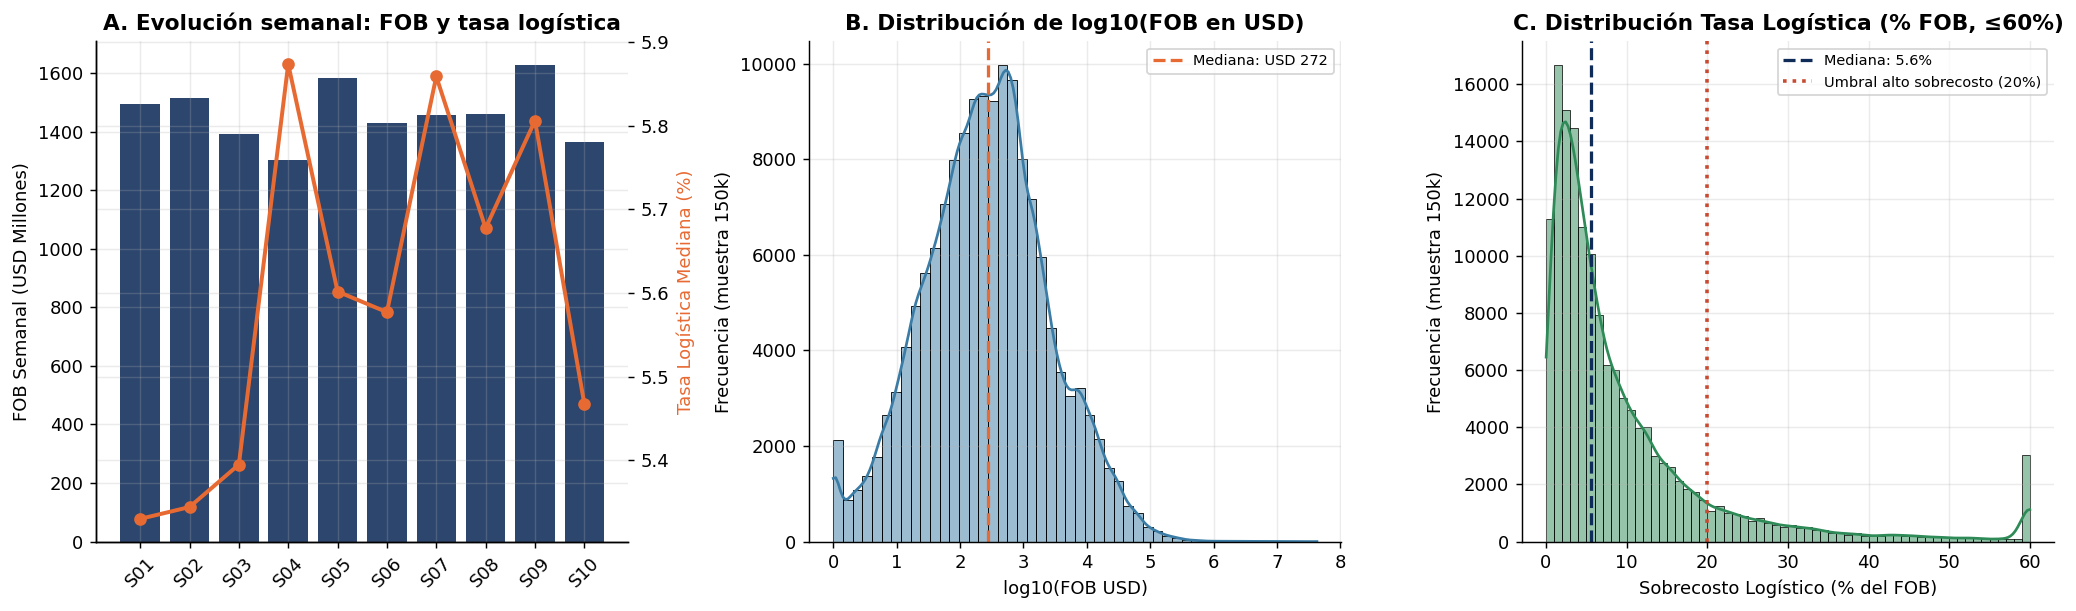

In [7]:
# 6.1 Indicadores macroeconómicos agregados y estadísticos robustos
df["VALOR_UNITARIO_KG"] = (df["FOB_DOLPOL"] / df["PESO_NETO"]).astype(np.float32)
df["TIENE_TLC_PREF"] = (df["TRAT_PREFE"] > 0).astype(np.int8)

total_fob = float(df["FOB_DOLPOL"].to_numpy(dtype=np.float64).sum())
total_fle = float(df["FLE_DOLAR"].to_numpy(dtype=np.float64).sum())
total_seg = float(df["SEG_DOLAR"].to_numpy(dtype=np.float64).sum())
total_cif = float(df["CIF_DOLAR"].to_numpy(dtype=np.float64).sum())
total_trib = float(df["TRIBUTOS_TOTAL_USD"].to_numpy(dtype=np.float64).sum())
total_adv = float(df["ADV_DOLAR"].to_numpy(dtype=np.float64).sum())
total_igv = float(df["IGV_DOLAR"].to_numpy(dtype=np.float64).sum())
total_ipm = float(df["IPM_DOLAR"].to_numpy(dtype=np.float64).sum())
total_isc = float(df["ISC_DOLAR"].to_numpy(dtype=np.float64).sum())
tasa_log_agregada = 100.0 * (total_fle + total_seg) / total_fob
tasa_log_mediana = float(df["TASA_LOGISTICA_PCT"].median())
tasa_log_media_wins = float(df["TASA_LOGISTICA_WINS"].mean())
tasa_log_p75 = float(df["TASA_LOGISTICA_PCT"].quantile(0.75))
tasa_log_p90 = float(df["TASA_LOGISTICA_PCT"].quantile(0.90))
n_dams = int(df[["CODI_ADUAN", "ANO_PRESE", "NUME_CORRE"]].drop_duplicates().shape[0])
n_importadores = int(df["LIBR_TRIBU"].nunique())
n_partidas = int(df["PART_NANDI"].nunique())
n_paises = int(df["PAIS_ORIGE_STR"].nunique())

print("=" * 72)
print("PANORAMA MACROECONÓMICO DE IMPORTACIONES DEFINITIVAS (10 SEMANAS)")
print("=" * 72)
print(f"Series limpias analizadas   : {len(df):>12,d}")
print(f"Declaraciones (DAM) únicas  : {n_dams:>12,d}")
print(f"Importadores únicos (RUC/ID): {n_importadores:>12,d}")
print(f"Partidas NANDINA únicas     : {n_partidas:>12,d}")
print(f"Países de origen únicos     : {n_paises:>12,d}")
print(f"Valor FOB total             : USD {total_fob/1e9:>8.3f} miles de millones")
print(f"Flete total                 : USD {total_fle/1e6:>8.2f} millones")
print(f"Seguro total                : USD {total_seg/1e6:>8.2f} millones")
print(f"Valor CIF total             : USD {total_cif/1e9:>8.3f} miles de millones")
print(f"Tributos aduaneros totales  : USD {total_trib/1e9:>8.3f} miles de millones")
print(f"  - IGV                     : USD {total_igv/1e6:>8.2f} millones ({100*total_igv/total_trib:.1f}%)")
print(f"  - IPM                     : USD {total_ipm/1e6:>8.2f} millones ({100*total_ipm/total_trib:.1f}%)")
print(f"  - Ad Valorem (ADV)        : USD {total_adv/1e6:>8.2f} millones ({100*total_adv/total_trib:.1f}%)")
print(f"  - ISC                     : USD {total_isc/1e6:>8.2f} millones ({100*total_isc/total_trib:.1f}%)")
print(f"Sobrecosto logístico agregado (Flete+Seg)/FOB : {tasa_log_agregada:.2f}%")
print(f"Tasa logística por serie — Mediana: {tasa_log_mediana:.2f}% | Media (wins): {tasa_log_media_wins:.2f}% | P75: {tasa_log_p75:.2f}% | P90: {tasa_log_p90:.2f}%")

# Tabla semanal limpia (sumas en float64 para máxima precisión contable)
sum64_m = lambda s: float(s.to_numpy(dtype=np.float64).sum()) / 1e6
sum64 = lambda s: float(s.to_numpy(dtype=np.float64).sum())

eda_semanal = df.groupby("SEMANA", observed=True).agg(
    series=("FOB_DOLPOL", "size"),
    fob_m=("FOB_DOLPOL", sum64_m),
    cif_m=("CIF_DOLAR", sum64_m),
    trib_m=("TRIBUTOS_TOTAL_USD", sum64_m),
    tasa_log_mediana=("TASA_LOGISTICA_PCT", "median"),
    tasa_log_agregada=("SOBRECOSTO_LOG_USD", sum64),
    fob_raw=("FOB_DOLPOL", sum64),
).reset_index()
eda_semanal["tasa_log_pond_pct"] = 100.0 * eda_semanal["tasa_log_agregada"] / eda_semanal["fob_raw"]
eda_semanal["semana_lbl"] = [f"S{i:02d}" for i in eda_semanal["SEMANA"]]

# Figura 1: Evolución semanal y distribución de FOB y Tasa Logística
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

ax0 = axes[0]
ax0.bar(eda_semanal["semana_lbl"], eda_semanal["fob_m"], color=PALETTE_ULIMA[0], alpha=0.88, label="FOB (USD M)")
ax0_t = ax0.twinx()
ax0_t.plot(eda_semanal["semana_lbl"], eda_semanal["tasa_log_mediana"], color=PALETTE_ULIMA[1], marker="o", lw=2.2, label="Tasa log. mediana (%)")
ax0.set_title("A. Evolución semanal: FOB y tasa logística")
ax0.set_ylabel("FOB Semanal (USD Millones)")
ax0_t.set_ylabel("Tasa Logística Mediana (%)", color=PALETTE_ULIMA[1])
ax0.tick_params(axis="x", rotation=45)
ax0_t.spines["top"].set_visible(False)

sample_plot = df.sample(n=min(150_000, len(df)), random_state=SEED)
ax1 = axes[1]
sns.histplot(np.log10(sample_plot["FOB_DOLPOL"].clip(lower=1)), bins=50, kde=True, color=PALETTE_ULIMA[3], ax=ax1)
ax1.set_title("B. Distribución de log10(FOB en USD)")
ax1.set_xlabel("log10(FOB USD)")
ax1.set_ylabel("Frecuencia (muestra 150k)")
ax1.axvline(np.log10(df["FOB_DOLPOL"].median()), color=PALETTE_ULIMA[1], ls="--", lw=1.8, label=f"Mediana: USD {df['FOB_DOLPOL'].median():,.0f}")
ax1.legend(fontsize=8)

ax2 = axes[2]
sns.histplot(sample_plot["TASA_LOGISTICA_WINS"].clip(upper=60), bins=60, kde=True, color=PALETTE_ULIMA[2], ax=ax2)
ax2.axvline(tasa_log_mediana, color=PALETTE_ULIMA[0], ls="--", lw=1.8, label=f"Mediana: {tasa_log_mediana:.1f}%")
ax2.axvline(20.0, color=PALETTE_ULIMA[4], ls=":", lw=2.0, label="Umbral alto sobrecosto (20%)")
ax2.set_title("C. Distribución Tasa Logística (% FOB, ≤60%)")
ax2.set_xlabel("Sobrecosto Logístico (% del FOB)")
ax2.set_ylabel("Frecuencia (muestra 150k)")
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig01_evolucion_semanal_y_distribucion.png", bbox_inches="tight")
plt.show()

[Contraste H1 — Efecto Alchian-Allen] Spearman rho(FOB/kg, Tasa Logística) = -0.4659 (p = 0.00e+00)
[Contraste H2 — Brecha Modal] Kruskal-Wallis H (VAPOR, AVION, CAMION) = 2,075.6 (p = 0.00e+00)


,VIA_TRANSP_DESC,series,fob_m,cif_m,tasa_log_med,tasa_log_media,val_kg_med,fob_med,pct_fob,pct_series
0,VAPOR,2077534,12621.514515,13723.732935,5.540949,9.845667,9.047379,429.006500,86.332403,65.845411
1,AVION,976809,1358.935827,1451.761658,5.879294,11.954542,98.935486,104.977997,9.295255,30.959007
2,CAMION,100753,637.363898,664.049467,3.557143,10.741135,10.836000,257.699005,4.359632,3.193268
3,FLUVIAL,6,1.793031,2.172226,21.466614,21.193287,0.425200,328900.000000,0.012265,0.000190
4,OTRA VIA,67,0.065163,0.072171,12.841020,14.497838,133.870956,660.000000,0.000446,0.002123


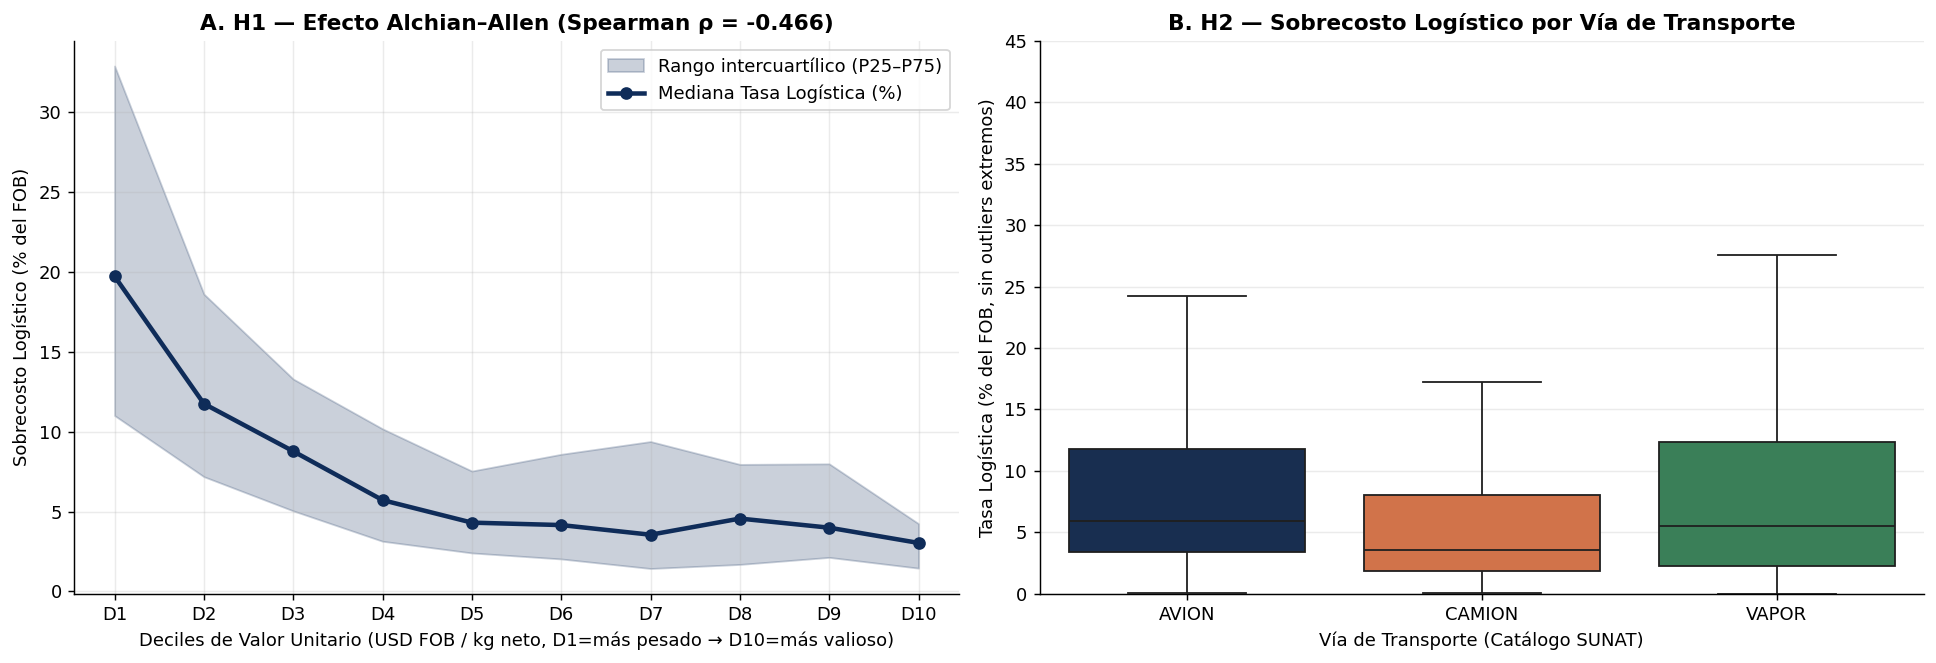

In [8]:
# 6.2 Contraste empírico de Hipótesis H1 (Alchian-Allen) y H2 (Brecha Modal)
# H1: Correlación de Spearman entre densidad de valor (FOB/kg) y tasa logística
sample_h1 = df[["VALOR_UNITARIO_KG", "TASA_LOGISTICA_WINS", "VIA_TRANSP_DESC", "FOB_DOLPOL"]].sample(
    n=min(300_000, len(df)), random_state=SEED
)
rho_aa, pval_aa = stats.spearmanr(sample_h1["VALOR_UNITARIO_KG"], sample_h1["TASA_LOGISTICA_WINS"])

# Deciles de valor unitario por kg sobre toda la base
df["DECIL_VAL_KG"] = pd.qcut(df["VALOR_UNITARIO_KG"].rank(method="first"), q=10, labels=[f"D{i}" for i in range(1, 11)])
h1_deciles = df.groupby("DECIL_VAL_KG", observed=True).agg(
    val_kg_med=("VALOR_UNITARIO_KG", "median"),
    tasa_log_med=("TASA_LOGISTICA_PCT", "median"),
    tasa_log_p25=("TASA_LOGISTICA_PCT", lambda s: s.quantile(0.25)),
    tasa_log_p75=("TASA_LOGISTICA_PCT", lambda s: s.quantile(0.75)),
    fob_m=("FOB_DOLPOL", lambda s: s.sum() / 1e6),
).reset_index()

# H2: Comparación por vía de transporte (base completa)
eda_via = df.groupby("VIA_TRANSP_DESC", observed=True).agg(
    series=("FOB_DOLPOL", "size"),
    fob_m=("FOB_DOLPOL", sum64_m),
    cif_m=("CIF_DOLAR", sum64_m),
    tasa_log_med=("TASA_LOGISTICA_PCT", "median"),
    tasa_log_media=("TASA_LOGISTICA_WINS", "mean"),
    val_kg_med=("VALOR_UNITARIO_KG", "median"),
    fob_med=("FOB_DOLPOL", "median"),
).sort_values("fob_m", ascending=False).reset_index()
eda_via["pct_fob"] = 100.0 * eda_via["fob_m"] / eda_via["fob_m"].sum()
eda_via["pct_series"] = 100.0 * eda_via["series"] / eda_via["series"].sum()

# Prueba Kruskal-Wallis entre las 3 vías principales (VAPOR, AVION, CAMION)
top3_vias = eda_via["VIA_TRANSP_DESC"].head(3).tolist()
kw_groups = [
    sample_h1.loc[sample_h1["VIA_TRANSP_DESC"] == v, "TASA_LOGISTICA_WINS"].to_numpy()
    for v in top3_vias
]
kw_stat, kw_pval = stats.kruskal(*kw_groups)

print(f"[Contraste H1 — Efecto Alchian-Allen] Spearman rho(FOB/kg, Tasa Logística) = {rho_aa:.4f} (p = {pval_aa:.2e})")
print(f"[Contraste H2 — Brecha Modal] Kruskal-Wallis H ({', '.join(top3_vias)}) = {kw_stat:,.1f} (p = {kw_pval:.2e})")
display(eda_via.head(6))

# Figura 2: Contraste visual H1 y H2
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

ax0 = axes[0]
x_idx = np.arange(len(h1_deciles))
ax0.fill_between(x_idx, h1_deciles["tasa_log_p25"], h1_deciles["tasa_log_p75"], alpha=0.22, color=PALETTE_ULIMA[0], label="Rango intercuartílico (P25–P75)")
ax0.plot(x_idx, h1_deciles["tasa_log_med"], marker="o", lw=2.5, color=PALETTE_ULIMA[0], label="Mediana Tasa Logística (%)")
ax0.set_xticks(x_idx)
ax0.set_xticklabels(h1_deciles["DECIL_VAL_KG"])
ax0.set_title(f"A. H1 — Efecto Alchian–Allen (Spearman ρ = {rho_aa:.3f})")
ax0.set_xlabel("Deciles de Valor Unitario (USD FOB / kg neto, D1=más pesado → D10=más valioso)")
ax0.set_ylabel("Sobrecosto Logístico (% del FOB)")
ax0.legend()

ax1 = axes[1]
sub_via = sample_h1[sample_h1["VIA_TRANSP_DESC"].isin(top3_vias)].copy()
sub_via["VIA_TRANSP_DESC"] = sub_via["VIA_TRANSP_DESC"].cat.remove_unused_categories()
sns.boxplot(
    data=sub_via, x="VIA_TRANSP_DESC", y="TASA_LOGISTICA_WINS",
    showfliers=False, palette=PALETTE_ULIMA[:3], ax=ax1
)
ax1.set_title("B. H2 — Sobrecosto Logístico por Vía de Transporte")
ax1.set_xlabel("Vía de Transporte (Catálogo SUNAT)")
ax1.set_ylabel("Tasa Logística (% del FOB, sin outliers extremos)")
ax1.set_ylim(0, 45)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig02_hipotesis_alchian_allen_y_modal.png", bbox_inches="tight")
plt.show()
df.drop(columns=["DECIL_VAL_KG"], inplace=True)

[Contraste H4 — Preferencia TLC] Tasa ADV efectiva media: Con TLC = 2.616% vs Sin TLC = 2.454% (Mann-Whitney p = 1.00e+00)
Proporción de series con trato preferencial TLC: 0.17%

Top 10 Países de Origen por Valor FOB:


,PAIS_ORIGE_STR,PAIS_ORIGE_DESC,REGION_ORIGEN,fob_m,pct_fob,tasa_log_med,tasa_adv_media,pct_tlc
0,CN,CHINA,Asia,4425.34,30.27,8.61,2.17,0.07
1,US,UNITED STATES,Norteamérica,3146.82,21.52,3.23,1.52,0.31
2,BR,BRAZIL,Sudamérica,915.12,6.26,4.57,0.74,0.03
3,AR,ARGENTINA,Sudamérica,802.43,5.49,5.62,0.60,0.13
4,CA,CANADA,Norteamérica,453.39,3.10,3.77,1.68,0.67
5,CL,CHILE,Sudamérica,348.31,2.38,3.43,1.45,0.44
6,IN,INDIA,Asia,324.73,2.22,6.29,3.82,0.02
7,MX,MEXICO,Norteamérica,322.43,2.21,2.98,0.91,0.06
8,EC,ECUADOR,Sudamérica,306.88,2.10,2.57,0.32,0.01
9,JP,JAPAN,Asia,304.01,2.08,2.34,1.39,0.02



Top 8 Intendencias de Aduana del Perú:


,CODI_ADUAN,ADUANA_DESC,series,fob_m,cif_m,tasa_log_med,pct_fob
0,118,MARITIMA DEL CALLAO,2009834,10010.60,10850.92,5.37,68.47
1,235,AEREA Y POSTAL EX-IAAC,976808,1358.92,1451.74,5.88,9.30
2,145,MOLLENDO - MATARANI,2775,684.46,742.30,8.09,4.68
3,370,OTRA ADUANA,57768,493.92,562.61,11.57,3.38
4,127,PISCO,644,385.51,423.95,5.29,2.64
5,046,PAITA,9104,336.01,369.52,9.00,2.30
6,172,TACNA,63286,317.45,335.00,4.55,2.17
7,028,TALARA,18,294.75,314.00,6.02,2.02


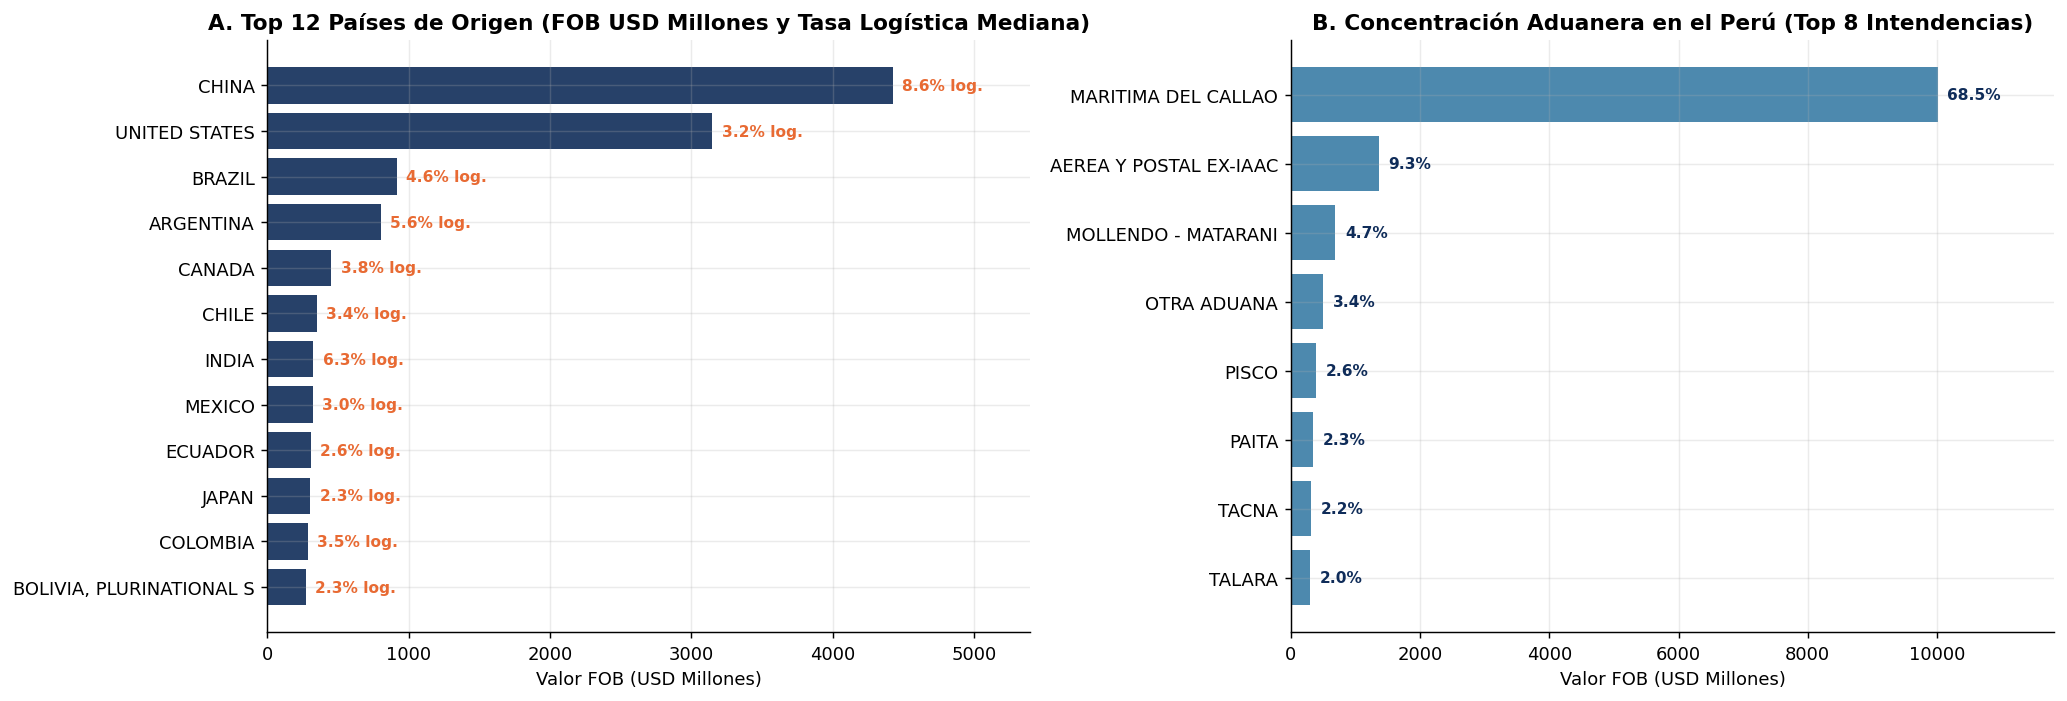

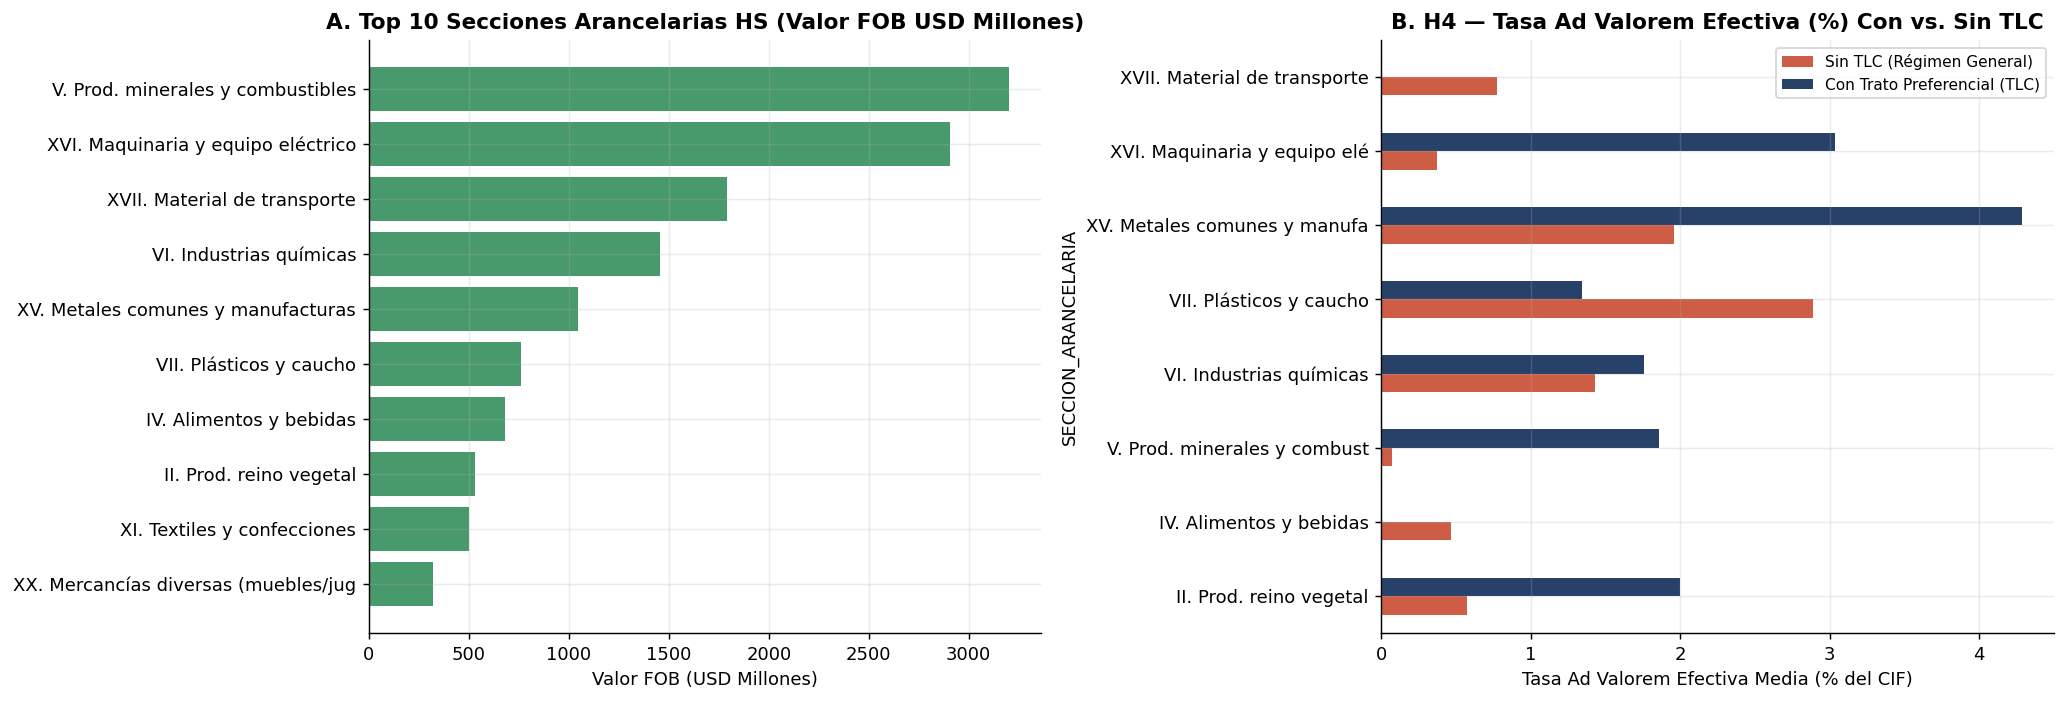

In [9]:
# 6.3 Contraste empírico de Hipótesis H3 (Geografía y Aduanas) y H4 (Preferencias TLC y Secciones HS)
eda_paises = df.groupby(["PAIS_ORIGE_STR", "PAIS_ISO3", "PAIS_ORIGE_DESC", "REGION_ORIGEN"], observed=True).agg(
    series=("FOB_DOLPOL", "size"),
    fob_m=("FOB_DOLPOL", sum64_m),
    cif_m=("CIF_DOLAR", sum64_m),
    trib_m=("TRIBUTOS_TOTAL_USD", sum64_m),
    tasa_log_med=("TASA_LOGISTICA_PCT", "median"),
    tasa_adv_media=("TASA_ADV_EFECTIVA_PCT", "mean"),
    pct_tlc=("TIENE_TLC_PREF", lambda s: 100.0 * s.mean()),
    val_kg_med=("VALOR_UNITARIO_KG", "median"),
).sort_values("fob_m", ascending=False).reset_index()
eda_paises["pct_fob"] = 100.0 * eda_paises["fob_m"] / eda_paises["fob_m"].sum()

eda_regiones = df.groupby("REGION_ORIGEN", observed=True).agg(
    series=("FOB_DOLPOL", "size"),
    fob_m=("FOB_DOLPOL", sum64_m),
    tasa_log_med=("TASA_LOGISTICA_PCT", "median"),
    tasa_adv_media=("TASA_ADV_EFECTIVA_PCT", "mean"),
    pct_tlc=("TIENE_TLC_PREF", lambda s: 100.0 * s.mean()),
).sort_values("fob_m", ascending=False).reset_index()
eda_regiones["pct_fob"] = 100.0 * eda_regiones["fob_m"] / eda_regiones["fob_m"].sum()

eda_aduanas = df.groupby(["CODI_ADUAN", "ADUANA_DESC"], observed=True).agg(
    series=("FOB_DOLPOL", "size"),
    fob_m=("FOB_DOLPOL", sum64_m),
    cif_m=("CIF_DOLAR", sum64_m),
    tasa_log_med=("TASA_LOGISTICA_PCT", "median"),
).sort_values("fob_m", ascending=False).reset_index()
eda_aduanas["pct_fob"] = 100.0 * eda_aduanas["fob_m"] / eda_aduanas["fob_m"].sum()

eda_secciones = df.groupby("SECCION_ARANCELARIA", observed=True).agg(
    series=("FOB_DOLPOL", "size"),
    fob_m=("FOB_DOLPOL", sum64_m),
    tasa_log_med=("TASA_LOGISTICA_PCT", "median"),
    tasa_adv_media=("TASA_ADV_EFECTIVA_PCT", "mean"),
    carga_trib_med=("CARGA_TRIBUTARIA_PCT", "median"),
    pct_tlc=("TIENE_TLC_PREF", lambda s: 100.0 * s.mean()),
    val_kg_med=("VALOR_UNITARIO_KG", "median"),
).sort_values("fob_m", ascending=False).reset_index()
eda_secciones["pct_fob"] = 100.0 * eda_secciones["fob_m"] / eda_secciones["fob_m"].sum()

# Contraste H4: Efecto del trato preferencial TLC sobre Tasa Ad Valorem Efectiva
adv_con_tlc = df.loc[df["TIENE_TLC_PREF"] == 1, "TASA_ADV_EFECTIVA_PCT"]
adv_sin_tlc = df.loc[df["TIENE_TLC_PREF"] == 0, "TASA_ADV_EFECTIVA_PCT"]
mw_u, mw_p = stats.mannwhitneyu(
    adv_con_tlc.sample(min(100_000, len(adv_con_tlc)), random_state=SEED),
    adv_sin_tlc.sample(min(100_000, len(adv_sin_tlc)), random_state=SEED),
    alternative="less"
)
print(f"[Contraste H4 — Preferencia TLC] Tasa ADV efectiva media: Con TLC = {adv_con_tlc.mean():.3f}% vs Sin TLC = {adv_sin_tlc.mean():.3f}% (Mann-Whitney p = {mw_p:.2e})")
print(f"Proporción de series con trato preferencial TLC: {100*df['TIENE_TLC_PREF'].mean():.2f}%")
print("\nTop 10 Países de Origen por Valor FOB:")
display(eda_paises.head(10)[["PAIS_ORIGE_STR", "PAIS_ORIGE_DESC", "REGION_ORIGEN", "fob_m", "pct_fob", "tasa_log_med", "tasa_adv_media", "pct_tlc"]].round(2))
print("\nTop 8 Intendencias de Aduana del Perú:")
display(eda_aduanas.head(8).round(2))

# Figura 3: Top 12 Países de Origen y Top 8 Aduanas
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
top12_p = eda_paises.head(12).iloc[::-1]
bars = axes[0].barh(top12_p["PAIS_ORIGE_DESC"].astype(str).str[:24], top12_p["fob_m"], color=PALETTE_ULIMA[0], alpha=0.9)
axes[0].set_title("A. Top 12 Países de Origen (FOB USD Millones y Tasa Logística Mediana)")
axes[0].set_xlabel("Valor FOB (USD Millones)")
for bar, tl in zip(bars, top12_p["tasa_log_med"]):
    axes[0].text(bar.get_width() + top12_p["fob_m"].max()*0.015, bar.get_y() + bar.get_height()/2,
                 f"{tl:.1f}% log.", va="center", fontsize=8.5, color=PALETTE_ULIMA[1], fontweight="bold")
axes[0].set_xlim(0, top12_p["fob_m"].max() * 1.22)

top8_a = eda_aduanas.head(8).iloc[::-1]
bars2 = axes[1].barh(top8_a["ADUANA_DESC"].astype(str).str[:26], top8_a["fob_m"], color=PALETTE_ULIMA[3], alpha=0.9)
axes[1].set_title("B. Concentración Aduanera en el Perú (Top 8 Intendencias)")
axes[1].set_xlabel("Valor FOB (USD Millones)")
for bar, pf in zip(bars2, top8_a["pct_fob"]):
    axes[1].text(bar.get_width() + top8_a["fob_m"].max()*0.015, bar.get_y() + bar.get_height()/2,
                 f"{pf:.1f}%", va="center", fontsize=8.5, color=PALETTE_ULIMA[0], fontweight="bold")
axes[1].set_xlim(0, top8_a["fob_m"].max() * 1.18)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig03_geografia_origen_y_aduanas.png", bbox_inches="tight")
plt.show()

# Figura 4: Efecto TLC y Secciones Arancelarias HS
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
top10_sec = eda_secciones.head(10).iloc[::-1]
axes[0].barh(top10_sec["SECCION_ARANCELARIA"].astype(str).str[:36], top10_sec["fob_m"], color=PALETTE_ULIMA[2], alpha=0.88)
axes[0].set_title("A. Top 10 Secciones Arancelarias HS (Valor FOB USD Millones)")
axes[0].set_xlabel("Valor FOB (USD Millones)")

tlc_sec = df[df["SECCION_ARANCELARIA"].isin(eda_secciones.head(8)["SECCION_ARANCELARIA"])].groupby(
    ["SECCION_ARANCELARIA", "TIENE_TLC_PREF"], observed=True
)["TASA_ADV_EFECTIVA_PCT"].mean().unstack(fill_value=0)
tlc_sec.index = tlc_sec.index.astype(str).str[:28]
tlc_sec.columns = ["Sin TLC (Régimen General)", "Con Trato Preferencial (TLC)"]
tlc_sec.plot(kind="barh", ax=axes[1], color=[PALETTE_ULIMA[4], PALETTE_ULIMA[0]], alpha=0.9)
axes[1].set_title("B. H4 — Tasa Ad Valorem Efectiva (%) Con vs. Sin TLC")
axes[1].set_xlabel("Tasa Ad Valorem Efectiva Media (% del CIF)")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig04_tlc_arancel_y_secciones_hs.png", bbox_inches="tight")
plt.show()

RESUMEN_METRICAS["eda"] = {
    "n_dams_unicas": n_dams,
    "n_importadores_unicos": n_importadores,
    "n_partidas_unicas": n_partidas,
    "n_paises_unicos": n_paises,
    "total_fob_usd": round(total_fob, 2),
    "total_flete_usd": round(total_fle, 2),
    "total_seguro_usd": round(total_seg, 2),
    "total_cif_usd": round(total_cif, 2),
    "total_tributos_usd": round(total_trib, 2),
    "total_adv_usd": round(total_adv, 2),
    "total_igv_usd": round(total_igv, 2),
    "total_ipm_usd": round(total_ipm, 2),
    "total_isc_usd": round(total_isc, 2),
    "tasa_logistica_agregada_pct": round(tasa_log_agregada, 3),
    "tasa_logistica_mediana_pct": round(tasa_log_mediana, 3),
    "tasa_logistica_media_wins_pct": round(tasa_log_media_wins, 3),
    "tasa_logistica_p75_pct": round(tasa_log_p75, 3),
    "tasa_logistica_p90_pct": round(tasa_log_p90, 3),
    "h1_spearman_rho": round(float(rho_aa), 4),
    "h1_spearman_pval": float(pval_aa),
    "h2_kruskal_H": round(float(kw_stat), 2),
    "h2_kruskal_pval": float(kw_pval),
    "h4_adv_con_tlc_media": round(float(adv_con_tlc.mean()), 4),
    "h4_adv_sin_tlc_media": round(float(adv_sin_tlc.mean()), 4),
    "h4_pct_series_tlc": round(float(100 * df["TIENE_TLC_PREF"].mean()), 2),
    "top10_paises": eda_paises.head(10).to_dict(orient="records"),
    "top8_aduanas": eda_aduanas.head(8).to_dict(orient="records"),
    "vias_transporte": eda_via.head(6).to_dict(orient="records"),
    "top10_secciones": eda_secciones.head(10).to_dict(orient="records"),
    "regiones": eda_regiones.to_dict(orient="records"),
    "semanal": eda_semanal[["semana_lbl", "series", "fob_m", "cif_m", "trib_m", "tasa_log_mediana", "tasa_log_pond_pct"]].to_dict(orient="records"),
}

---
## 7. Ingeniería de variables económicas, prevención de fuga de información y exportación de `Base_Final_Grupo_9.parquet`

### 7.1 Principio económico anti-fuga (*Data Leakage Prevention*)
Al predecir el sobrecosto logístico ad valorem (`LOG_TASA_LOGISTICA` y el indicador binario `ALTO_SOBRECOSTO = 1` si `TASA_LOGISTICA_PCT >= 20%`), es **metodológicamente indispensable** excluir de la matriz de predictores $X$ cualquier variable que contenga matemática o contablemente el flete o el seguro:
* **Variables PROHIBIDAS en $X$ (*ex-post* / fuga directa o indirecta):** `FLE_DOLAR`, `SEG_DOLAR`, `CIF_DOLAR`, `SOBRECOSTO_LOG_USD`, `TASA_LOGISTICA_PCT`, `TASA_LOGISTICA_WINS`, `ADV_DOLAR`, `IGV_DOLAR`, `IPM_DOLAR`, `ISC_DOLAR`, `TRIBUTOS_TOTAL_USD`, `TASA_ADV_EFECTIVA_PCT` y `CARGA_TRIBUTARIA_PCT` (dado que en la aduana peruana `IGV = 16% × (CIF + ADV)` e `IPM = 2% × (CIF + ADV)`, incluir cualquier tributo revelaría el valor CIF y filtraría la variable objetivo).
* **Variables PERMITIDAS en $X$ (*ex-ante*):** Escala del embarque (`LOG_FOB`), masa física (`LOG_PESO_NETO`, `LOG_PESO_BRUTO`), densidad de valor Alchian–Allen (`LOG_VALOR_UNIT_KG`), intensidad de embalaje (`RATIO_EMBALAJE_LOG`), volumen físico (`LOG_CANT_BULTO`, `SERIES_EN_DAM`), tiempos logísticos (`DIAS_TRANSITO`, `DIAS_DESPACHO`), características aduaneras/geográficas (`VIA_TRANSP`, `REGION_ORIGEN`, `SECCION_ARANCELARIA`, `CODI_ADUAN`, `PAIS_ORIGE`, `CAPITULO_HS2`), triangulación comercial (`ORIGEN_EQ_ADQUI`), estado de la mercancía (`ES_MERCANCIA_NUEVA`), regímenes preferenciales (`TIENE_TLC_PREF`, `TIENE_LIBERACION`, `PAGO_INMEDIATO`) y codificación objetivo suavizada calculada **estrictamente dentro del conjunto de entrenamiento**.

In [10]:
# 7.1 Creación de variables económicas derivadas (estrictamente ex-ante)
df["LOG_FOB"] = np.log1p(df["FOB_DOLPOL"]).astype(np.float32)
df["LOG_PESO_NETO"] = np.log1p(df["PESO_NETO"]).astype(np.float32)
df["LOG_PESO_BRUTO"] = np.log1p(df["PESO_BRUTO_CORR"]).astype(np.float32)
df["LOG_VALOR_UNIT_KG"] = np.log1p(df["VALOR_UNITARIO_KG"].clip(lower=0)).astype(np.float32)
df["RATIO_EMBALAJE"] = ((df["PESO_BRUTO_CORR"] - df["PESO_NETO"]) / df["PESO_NETO"]).clip(0, 10).astype(np.float32)
df["RATIO_EMBALAJE_LOG"] = np.log1p(df["RATIO_EMBALAJE"]).astype(np.float32)
df["LOG_CANT_BULTO"] = np.log1p(df["CANT_BULTO"].clip(lower=0)).astype(np.float32)

# Tiempos logísticos (días de tránsito internacional y días de despacho aduanero)
dias_trans = (df["DT_LLEGA"] - df["DT_EMBAR"]).dt.days
df["DIAS_TRANSITO_VAL"] = dias_trans.where((dias_trans >= 0) & (dias_trans <= 180)).astype(np.float32)
df["TIENE_DIAS_TRANSITO"] = df["DIAS_TRANSITO_VAL"].notna().astype(np.int8)

dias_desp = (df["DT_INGSI"] - df["DT_LLEGA"]).dt.days
df["DIAS_DESPACHO_VAL"] = dias_desp.where((dias_desp >= -60) & (dias_desp <= 120)).astype(np.float32)

# Consolidación en DAM: número de series declaradas dentro de la misma DAM (ex-ante)
dam_key = (
    df["CODI_ADUAN"].astype(str) + "_" +
    df["ANO_PRESE"].astype(str) + "_" +
    df["NUME_CORRE"].astype(str)
)
series_por_dam = dam_key.map(dam_key.value_counts()).astype(np.int32)
df["SERIES_EN_DAM"] = series_por_dam
df["LOG_SERIES_EN_DAM"] = np.log1p(series_por_dam).astype(np.float32)
del dam_key, series_por_dam

# Indicadores estructurales ex-ante
df["ORIGEN_EQ_ADQUI"] = (df["PAIS_ORIGE_STR"] == df["PAIS_ADQUI_STR"]).astype(np.int8)
df["ES_MERCANCIA_NUEVA"] = (df["SEST_MERCA"].astype(str) == "10").astype(np.int8)
df["TIENE_LIBERACION"] = (df["CODI_LIBER"] > 0).astype(np.int8)
df["ES_RUC_EMPRESA"] = (df["TIPO_DOCUM"].astype(str) == "4").astype(np.int8)
df["ES_TELEDESPACHO"] = (df["DK"].astype(str) == "T").astype(np.int8)

# Variable objetivo binaria desbalanceada para clasificación: Alto Sobrecosto Logístico (>= 20% del FOB)
UMBRAL_ALTO_SOBRECOSTO = 20.0
df["ALTO_SOBRECOSTO"] = (df["TASA_LOGISTICA_PCT"] >= UMBRAL_ALTO_SOBRECOSTO).astype(np.int8)
tasa_positivos = float(df["ALTO_SOBRECOSTO"].mean())
print(f"Variable objetivo binaria ALTO_SOBRECOSTO (>= {UMBRAL_ALTO_SOBRECOSTO:.0f}% del FOB): "
      f"{int(df['ALTO_SOBRECOSTO'].sum()):,d} positivos ({100*tasa_positivos:.2f}% — clase desbalanceada).")

# 7.2 Exportación y verificación de Base_Final_Grupo_9.parquet (> 2,000,000 filas garantizadas)
BASE_FINAL_COLS = [
    "SEMANA", "CODI_ADUAN", "ADUANA_DESC", "ANO_PRESE", "NUME_CORRE", "NUME_SERIE",
    "DT_INGSI", "DT_LLEGA", "DT_EMBAR", "TIPO_DOCUM", "LIBR_TRIBU", "VIA_TRANSP", "VIA_TRANSP_DESC",
    "PAIS_ORIGE_STR", "PAIS_ISO3", "PAIS_ORIGE_DESC", "PAIS_ADQUI_STR", "REGION_ORIGEN",
    "PUER_EMBAR", "PART_NANDI", "CAPITULO_HS2", "SECCION_ARANCELARIA", "SEST_MERCA", "EST_MERCA_DESC",
    "FOB_DOLPOL", "FLE_DOLAR", "SEG_DOLAR", "CIF_DOLAR", "SOBRECOSTO_LOG_USD",
    "PESO_NETO", "PESO_BRUTO_CORR", "FLAG_PESO_CORR", "CANT_BULTO",
    "ADV_DOLAR", "IGV_DOLAR", "IPM_DOLAR", "ISC_DOLAR", "TRIBUTOS_TOTAL_USD",
    "TRAT_PREFE", "CODI_LIBER", "PAGO_INMEDIATO", "LONG_DESC_COMER", "TIENE_DESC_COMER",
    "TASA_LOGISTICA_PCT", "TASA_LOGISTICA_WINS", "FLAG_OUTLIER_LOGISTICO", "LOG_TASA_LOGISTICA",
    "ALTO_SOBRECOSTO", "TASA_ADV_EFECTIVA_PCT", "CARGA_TRIBUTARIA_PCT",
    "VALOR_UNITARIO_KG", "LOG_FOB", "LOG_PESO_NETO", "LOG_PESO_BRUTO", "LOG_VALOR_UNIT_KG",
    "RATIO_EMBALAJE", "RATIO_EMBALAJE_LOG", "LOG_CANT_BULTO",
    "DIAS_TRANSITO_VAL", "TIENE_DIAS_TRANSITO", "DIAS_DESPACHO_VAL",
    "SERIES_EN_DAM", "LOG_SERIES_EN_DAM", "ORIGEN_EQ_ADQUI", "ES_MERCANCIA_NUEVA",
    "TIENE_TLC_PREF", "TIENE_LIBERACION", "ES_RUC_EMPRESA", "ES_TELEDESPACHO",
]

BASE_FINAL_PATH = OUT_DIR / "Base_Final_Grupo_9.parquet"
df[BASE_FINAL_COLS].to_parquet(BASE_FINAL_PATH, engine="pyarrow", compression="zstd", compression_level=6, index=False)
base_final_mb = BASE_FINAL_PATH.stat().st_size / (1024 ** 2)

# Verificación de lectura de vuelta
pf_check = pq.ParquetFile(str(BASE_FINAL_PATH))
assert pf_check.metadata.num_rows == len(df) and pf_check.metadata.num_rows > 2_000_000
print(f"\n[OK] Base_Final_Grupo_9.parquet exportada y verificada: "
      f"{pf_check.metadata.num_rows:,d} filas × {pf_check.metadata.num_columns} columnas ({base_final_mb:.2f} MB ZSTD).")

# Exportar diccionario completo (58 crudas + variables derivadas)
derivadas_info = [
    ("CIF_DOLAR", "float32", "Valor CIF = FOB + Flete + Seguro", "USD", "> 0", "Objetivo/contable (excluida de X por leakage)"),
    ("SOBRECOSTO_LOG_USD", "float32", "Costo logístico absoluto = Flete + Seguro", "USD", ">= 0", "Excluida de X por leakage"),
    ("TASA_LOGISTICA_PCT", "float32", "Sobrecosto logístico ad valorem = 100*(Flete+Seguro)/FOB", "% FOB", ">= 0", "Variable económica objetivo"),
    ("TASA_LOGISTICA_WINS", "float32", "Tasa logística winsorizada al percentil 99.5", "% FOB", "[0, P99.5]", "Base para transformación log1p"),
    ("LOG_TASA_LOGISTICA", "float32", "log1p(TASA_LOGISTICA_WINS)", "log(%)", ">= 0", "Target de Regresión Supervisada"),
    ("ALTO_SOBRECOSTO", "int8", "Indicador binario: 1 si TASA_LOGISTICA_PCT >= 20%", "Binaria", "{0, 1}", "Target de Clasificación Desbalanceada"),
    ("TRIBUTOS_TOTAL_USD", "float32", "Suma total de tributos aduaneros liquidados", "USD", ">= 0", "Excluida de X por leakage (depende de CIF)"),
    ("TASA_ADV_EFECTIVA_PCT", "float32", "Arancel Ad Valorem efectivo = 100*ADV/CIF", "% CIF", "[0, 100]", "Análisis fiscal y clustering"),
    ("CARGA_TRIBUTARIA_PCT", "float32", "Carga tributaria total = 100*Tributos/CIF", "% CIF", "[0, 150]", "Análisis fiscal y clustering"),
    ("VALOR_UNITARIO_KG", "float32", "Densidad de valor = FOB / PESO_NETO (Alchian-Allen)", "USD/kg", "> 0", "Predictor clave ex-ante"),
    ("LOG_VALOR_UNIT_KG", "float32", "log1p(VALOR_UNITARIO_KG)", "log(USD/kg)", ">= 0", "Predictor supervisado y variable de clustering"),
    ("LOG_FOB", "float32", "log1p(FOB_DOLPOL)", "log(USD)", "> 0", "Predictor de escala económica"),
    ("LOG_PESO_NETO", "float32", "log1p(PESO_NETO)", "log(kg)", "> 0", "Predictor de masa física"),
    ("RATIO_EMBALAJE_LOG", "float32", "log1p((PESO_BRUTO_CORR - PESO_NETO)/PESO_NETO)", "log(ratio)", ">= 0", "Predictor de intensidad de embalaje"),
    ("DIAS_TRANSITO_VAL", "float32", "Días entre fecha de embarque y llegada (rango 0–180)", "Días", "[0, 180]", "Proxy de distancia y congestión logística"),
    ("DIAS_DESPACHO_VAL", "float32", "Días entre llegada de nave y numeración DAM (-60 a 120)", "Días", "[-60, 120]", "Indicador de despacho anticipado vs diferido"),
    ("SERIES_EN_DAM", "int32", "Cantidad de series consolidadas en la misma DAM", "Conteo", ">= 1", "Proxy de consolidación de carga"),
    ("ORIGEN_EQ_ADQUI", "int8", "1 si PAIS_ORIGE == PAIS_ADQUI (compra directa)", "Binaria", "{0, 1}", "Indicador de no triangulación comercial"),
    ("TIENE_TLC_PREF", "int8", "1 si TRAT_PREFE > 0 (acogido a acuerdo comercial)", "Binaria", "{0, 1}", "Indicador de preferencia arancelaria TLC"),
    ("CAPITULO_HS2", "string", "Capítulo arancelario (2 primeros dígitos NANDINA)", "Código HS2", "01–99", "Clasificación sectorial"),
    ("SECCION_ARANCELARIA", "category", "21 Secciones oficiales del Sistema Armonizado", "Categoría", "I–XXI", "Agregación económica sectorial"),
    ("REGION_ORIGEN", "category", "Macro-región geográfica del país de origen", "Categoría", "7 regiones", "Agregación geográfica"),
]
df_dic_deriv = pd.DataFrame([
    {"n_campo": 58 + i, "variable": v[0], "tipo_dbf": v[1], "descripcion_oficial_sunat": v[2],
     "unidad": v[3], "dominio": v[4], "faltantes_o_vacios": 0, "pct_faltantes": 0.0, "tratamiento_aplicado": v[5]}
    for i, v in enumerate(derivadas_info, 1)
])
df_diccionario_completo = pd.concat([df_diccionario_raw, df_dic_deriv], ignore_index=True)
df_diccionario_completo.to_csv(OUT_DIR / "diccionario_variables.csv", index=False, encoding="utf-8-sig")

RESUMEN_METRICAS["base_final"] = {
    "filas": int(pf_check.metadata.num_rows),
    "columnas": int(pf_check.metadata.num_columns),
    "tamano_parquet_mb": round(base_final_mb, 2),
    "tasa_alto_sobrecosto_pct": round(100.0 * tasa_positivos, 3),
    "umbral_alto_sobrecosto_pct": UMBRAL_ALTO_SOBRECOSTO,
}
gc.collect()

Variable objetivo binaria ALTO_SOBRECOSTO (>= 20% del FOB): 379,235 positivos (12.02% — clase desbalanceada).

[OK] Base_Final_Grupo_9.parquet exportada y verificada: 3,155,169 filas × 69 columnas (189.23 MB ZSTD).


397

---
## 8. Modelado supervisado sobre la base completa (> 2,000,000 filas)

Siguiendo la metodología del curso, el modelado supervisado se ejecuta sobre el **universo íntegro limpio (> 2,000,000 registros)**, evitando muestrear artificialmente el entrenamiento.

### Diseño metodológico estricto (sin fuga temporal ni fuga de objetivo):
* **Partición temporal *Out-of-Time*:** Semanas **S01–S08** (07/09/2026 – 01/11/2026, ~80%) para entrenamiento y validación cruzada; semanas **S09–S10** (02/11/2026 – 15/11/2026, ~20%) reservadas estrictamente como conjunto de prueba futuro no visto.
* **Codificación objetivo suavizada *Out-of-Fold* (OOF):** Para variables categóricas de alta cardinalidad (`PAIS_ORIGE_STR`, `CAPITULO_HS2`, `CODI_ADUAN`), la media condicional suavizada (`m = 50`) se calcula **exclusivamente dentro de cada fold de entrenamiento** (nunca tocando el conjunto de prueba ni el propio fold de validación).
* **Dos tareas complementarias con relevancia económica directa:**
  1. **Tarea 8A — Regresión continua (`LOG_TASA_LOGISTICA`):** Compara *Dummy Mean*, **Línea Base Econométrica (`Ridge`)**, **Modelo Alternativo 1 (`HistGradientBoostingRegressor`)** y **Modelo Alternativo 2 (`LGBMRegressor`)**, reportando RMSE, MAE, MdAE y $R^2$ tanto en escala logarítmica como retransformados a puntos porcentuales (`expm1`).
  2. **Tarea 8B — Clasificación desbalanceada (`ALTO_SOBRECOSTO >= 20%`):** Compara *Dummy Majority*, **Línea Base (`LogisticRegression` balanceada)**, **Modelo Alternativo 1 (`HistGradientBoostingClassifier`)** y **Modelo Alternativo 2 (`LGBMClassifier`)**, priorizando **PR-AUC**, **ROC-AUC**, **F1-Score**, **Recall** y **Balanced Accuracy** frente al *Accuracy* simple.

In [11]:
# 8.1 Preparación de matriz X_train / X_test (split temporal semanas 1-8 vs 9-10) sin fuga de información
train_mask = df["SEMANA"] <= 8
test_mask = df["SEMANA"] >= 9

n_train = int(train_mask.sum())
n_test = int(test_mask.sum())
print(f"Split Temporal Out-of-Time -> Entrenamiento (S01-S08): {n_train:,d} filas ({100*n_train/len(df):.1f}%) | "
      f"Prueba Futura (S09-S10): {n_test:,d} filas ({100*n_test/len(df):.1f}%)")

NUM_FEATS_BASE = [
    "LOG_FOB", "LOG_PESO_NETO", "LOG_PESO_BRUTO", "LOG_VALOR_UNIT_KG",
    "RATIO_EMBALAJE_LOG", "LOG_CANT_BULTO", "DIAS_TRANSITO_VAL", "TIENE_DIAS_TRANSITO",
    "DIAS_DESPACHO_VAL", "LOG_SERIES_EN_DAM", "ORIGEN_EQ_ADQUI", "ES_MERCANCIA_NUEVA",
    "TIENE_TLC_PREF", "TIENE_LIBERACION", "ES_RUC_EMPRESA", "ES_TELEDESPACHO",
    "PAGO_INMEDIATO", "LONG_DESC_COMER"
]
CAT_FEATS_OHE = ["VIA_TRANSP_STR", "REGION_ORIGEN", "SECCION_ARANCELARIA"]
HIGH_CARD_COLS = ["PAIS_ORIGE_STR", "CAPITULO_HS2", "CODI_ADUAN"]

# Función reutilizable de Target Encoding Bayesiano Out-of-Fold (cero fuga de información)
def fit_transform_oof_target_encoding(df_tr, y_tr, df_te, cols, n_splits=5, smooth_m=50.0, seed=SEED):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    global_mean = float(np.mean(y_tr))
    tr_encoded = pd.DataFrame(index=df_tr.index)
    te_encoded = pd.DataFrame(index=df_te.index)
    for col in cols:
        oof_vals = np.full(len(df_tr), global_mean, dtype=np.float32)
        s_tr = df_tr[col].astype(str)
        for tr_i, val_i in kf.split(df_tr):
            stats_df = pd.DataFrame({"k": s_tr.iloc[tr_i].values, "y": y_tr[tr_i]}).groupby("k")["y"].agg(["count", "mean"])
            enc_map = (stats_df["count"] * stats_df["mean"] + smooth_m * global_mean) / (stats_df["count"] + smooth_m)
            oof_vals[val_i] = s_tr.iloc[val_i].map(enc_map).fillna(global_mean).to_numpy(dtype=np.float32)
        tr_encoded[f"TE_{col}"] = oof_vals
        # Mapeo a test usando únicamente el set de entrenamiento completo
        stats_full = pd.DataFrame({"k": s_tr.values, "y": y_tr}).groupby("k")["y"].agg(["count", "mean"])
        enc_full = (stats_full["count"] * stats_full["mean"] + smooth_m * global_mean) / (stats_full["count"] + smooth_m)
        te_encoded[f"TE_{col}"] = df_te[col].astype(str).map(enc_full).fillna(global_mean).to_numpy(dtype=np.float32)
    return tr_encoded, te_encoded

y_reg_train = df.loc[train_mask, "LOG_TASA_LOGISTICA"].to_numpy(dtype=np.float32)
y_reg_test = df.loc[test_mask, "LOG_TASA_LOGISTICA"].to_numpy(dtype=np.float32)
y_reg_test_pct = df.loc[test_mask, "TASA_LOGISTICA_WINS"].to_numpy(dtype=np.float32)

y_clf_train = df.loc[train_mask, "ALTO_SOBRECOSTO"].to_numpy(dtype=np.int8)
y_clf_test = df.loc[test_mask, "ALTO_SOBRECOSTO"].to_numpy(dtype=np.int8)

# Target encoding OOF separado para regresión y clasificación (cero leakage)
te_reg_tr, te_reg_te = fit_transform_oof_target_encoding(
    df.loc[train_mask, HIGH_CARD_COLS], y_reg_train, df.loc[test_mask, HIGH_CARD_COLS], HIGH_CARD_COLS
)
te_clf_tr, te_clf_te = fit_transform_oof_target_encoding(
    df.loc[train_mask, HIGH_CARD_COLS], y_clf_train.astype(np.float32), df.loc[test_mask, HIGH_CARD_COLS], HIGH_CARD_COLS
)

# Matrices de entrenamiento/prueba para árboles (LightGBM / HGB) y pipelines lineales
X_tr_base = df.loc[train_mask, NUM_FEATS_BASE + CAT_FEATS_OHE].copy()
X_te_base = df.loc[test_mask, NUM_FEATS_BASE + CAT_FEATS_OHE].copy()

# Imputación mediana basada SOLO en train para variables con NaN (DIAS_TRANSITO_VAL, DIAS_DESPACHO_VAL)
med_transito = float(X_tr_base["DIAS_TRANSITO_VAL"].median())
med_despacho = float(X_tr_base["DIAS_DESPACHO_VAL"].median())
for frame in (X_tr_base, X_te_base):
    frame["DIAS_TRANSITO_VAL"] = frame["DIAS_TRANSITO_VAL"].fillna(med_transito).astype(np.float32)
    frame["DIAS_DESPACHO_VAL"] = frame["DIAS_DESPACHO_VAL"].fillna(med_despacho).astype(np.float32)
    for c in CAT_FEATS_OHE:
        frame[c] = frame[c].astype("category")

X_tr_reg = pd.concat([X_tr_base, te_reg_tr], axis=1)
X_te_reg = pd.concat([X_te_base, te_reg_te], axis=1)
X_tr_clf = pd.concat([X_tr_base, te_clf_tr], axis=1)
X_te_clf = pd.concat([X_te_base, te_clf_te], axis=1)

ALL_NUM_REG = NUM_FEATS_BASE + [f"TE_{c}" for c in HIGH_CARD_COLS]
print(f"Matriz predictora lista: {X_tr_reg.shape[1]} variables ({len(ALL_NUM_REG)} numéricas/OOF + {len(CAT_FEATS_OHE)} categóricas).")

Split Temporal Out-of-Time -> Entrenamiento (S01-S08): 2,528,876 filas (80.2%) | Prueba Futura (S09-S10): 626,293 filas (19.8%)
Matriz predictora lista: 24 variables (21 numéricas/OOF + 3 categóricas).


In [12]:
# 8.2 Tarea 8A — Regresión Continua: Predicción de LOG_TASA_LOGISTICA (Base Completa > 2M filas)
preproc_linear = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), ALL_NUM_REG),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CAT_FEATS_OHE),
    ],
    remainder="drop"
)

def eval_reg(name, y_true_log, y_pred_log, y_true_pct, fit_sec):
    y_pred_pct = np.expm1(np.clip(y_pred_log, 0, 8))
    return {
        "Modelo": name,
        "RMSE_log": round(float(np.sqrt(mean_squared_error(y_true_log, y_pred_log))), 4),
        "MAE_log": round(float(mean_absolute_error(y_true_log, y_pred_log)), 4),
        "R2_log": round(float(r2_score(y_true_log, y_pred_log)), 4),
        "MAE_pp": round(float(mean_absolute_error(y_true_pct, y_pred_pct)), 3),
        "MdAE_pp": round(float(median_absolute_error(y_true_pct, y_pred_pct)), 3),
        "Tiempo_s": round(fit_sec, 1),
    }

reg_results = []
reg_preds_test = {}

# 1. Dummy Mean Baseline
t0 = time.time()
dummy_reg = DummyRegressor(strategy="mean").fit(X_tr_reg[ALL_NUM_REG], y_reg_train)
pred_dummy = dummy_reg.predict(X_te_reg[ALL_NUM_REG])
reg_results.append(eval_reg("0. Dummy (Media)", y_reg_test, pred_dummy, y_reg_test_pct, time.time() - t0))

# 2. Línea Base Econométrica: Ridge Regression (con estandarización + OHE en Pipeline)
t0 = time.time()
pipe_ridge = Pipeline([("prep", preproc_linear), ("model", Ridge(alpha=10.0, random_state=SEED))])
pipe_ridge.fit(X_tr_reg, y_reg_train)
pred_ridge = pipe_ridge.predict(X_te_reg)
pred_ridge_tr = pipe_ridge.predict(X_tr_reg)
reg_preds_test["Ridge"] = pred_ridge
reg_results.append(eval_reg("1. Línea Base: Ridge (OLS Reg.)", y_reg_test, pred_ridge, y_reg_test_pct, time.time() - t0))

# Extraer coeficientes estandarizados clave de Ridge para lectura económica
feat_names_lin = pipe_ridge.named_steps["prep"].get_feature_names_out()
coefs_ridge = pd.Series(pipe_ridge.named_steps["model"].coef_, index=feat_names_lin)
top_coefs_num = coefs_ridge[[f"num__{c}" for c in ALL_NUM_REG]].sort_values()

# 3. Modelo Alternativo 1: HistGradientBoostingRegressor (soporte nativo categórico)
t0 = time.time()
hgb_reg = HistGradientBoostingRegressor(
    max_iter=200, max_depth=8, learning_rate=0.07, min_samples_leaf=80,
    l2_regularization=1.0, categorical_features="from_dtype", random_state=SEED
)
hgb_reg.fit(X_tr_reg, y_reg_train)
pred_hgb = hgb_reg.predict(X_te_reg)
pred_hgb_tr = hgb_reg.predict(X_tr_reg)
reg_preds_test["HGB"] = pred_hgb
reg_results.append(eval_reg("2. Alternativo: HistGradientBoosting", y_reg_test, pred_hgb, y_reg_test_pct, time.time() - t0))

# 4. Modelo Alternativo 2: LightGBM Regressor (ajustado)
t0 = time.time()
lgb_reg = lgb.LGBMRegressor(
    n_estimators=260, learning_rate=0.07, num_leaves=63, max_depth=10,
    min_child_samples=80, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    reg_alpha=0.5, reg_lambda=2.0, random_state=SEED, n_jobs=-1, verbose=-1
)
lgb_reg.fit(X_tr_reg, y_reg_train)
pred_lgb = lgb_reg.predict(X_te_reg)
pred_lgb_tr = lgb_reg.predict(X_tr_reg)
reg_preds_test["LightGBM"] = pred_lgb
reg_results.append(eval_reg("3. Alternativo: LightGBM Regressor", y_reg_test, pred_lgb, y_reg_test_pct, time.time() - t0))

df_reg_results = pd.DataFrame(reg_results)
print("=" * 72)
print("RESULTADOS REGRESIÓN SUPERVISADA — CONJUNTO TEMPORAL FUTURO (S09–S10)")
print("=" * 72)
display(df_reg_results)

print(f"\nControl de sobreajuste (R2 Train vs Test):")
print(f"  - Ridge   : Train R2 = {r2_score(y_reg_train, pred_ridge_tr):.4f} | Test R2 = {r2_score(y_reg_test, pred_ridge):.4f}")
print(f"  - HGB     : Train R2 = {r2_score(y_reg_train, pred_hgb_tr):.4f} | Test R2 = {r2_score(y_reg_test, pred_hgb):.4f}")
print(f"  - LightGBM: Train R2 = {r2_score(y_reg_train, pred_lgb_tr):.4f} | Test R2 = {r2_score(y_reg_test, pred_lgb):.4f}")

print("\nCoeficientes estandarizados clave de Ridge (signo económico en LOG_TASA_LOGISTICA):")
for k, v in top_coefs_num.items():
    print(f"  {k.replace('num__', ''):24s}: {v:+.4f}")

# Importancia de variables en LightGBM (gain normalizado)
imp_lgb_reg = pd.Series(
    lgb_reg.booster_.feature_importance(importance_type="gain"),
    index=X_tr_reg.columns
)
imp_lgb_reg = (100.0 * imp_lgb_reg / imp_lgb_reg.sum()).sort_values(ascending=False)

RESULTADOS REGRESIÓN SUPERVISADA — CONJUNTO TEMPORAL FUTURO (S09–S10)


,Modelo,RMSE_log,MAE_log,R2_log,MAE_pp,MdAE_pp,Tiempo_s
0,0. Dummy (Media),0.9195,0.7352,-0.0001,7.974,3.933,0.1
1,1. Línea Base: Ridge (OLS Reg.),0.5617,0.4349,0.6268,5.305,2.177,12.8
2,2. Alternativo: HistGradientBoosting,0.4665,0.3474,0.7426,4.292,1.567,220.4
3,3. Alternativo: LightGBM Regressor,0.4519,0.3322,0.7584,4.162,1.509,140.6



Control de sobreajuste (R2 Train vs Test):
  - Ridge   : Train R2 = 0.6278 | Test R2 = 0.6268
  - HGB     : Train R2 = 0.7820 | Test R2 = 0.7426
  - LightGBM: Train R2 = 0.8179 | Test R2 = 0.7584

Coeficientes estandarizados clave de Ridge (signo económico en LOG_TASA_LOGISTICA):
  LOG_VALOR_UNIT_KG       : -0.5857
  LOG_FOB                 : -0.3029
  LOG_SERIES_EN_DAM       : -0.1968
  TIENE_DIAS_TRANSITO     : -0.0215
  LOG_CANT_BULTO          : -0.0201
  TIENE_LIBERACION        : -0.0147
  ES_RUC_EMPRESA          : -0.0098
  TIENE_TLC_PREF          : -0.0066
  ES_TELEDESPACHO         : +0.0000
  DIAS_DESPACHO_VAL       : +0.0077
  LONG_DESC_COMER         : +0.0181
  PAGO_INMEDIATO          : +0.0192
  ES_MERCANCIA_NUEVA      : +0.0257
  LOG_PESO_NETO           : +0.0296
  DIAS_TRANSITO_VAL       : +0.0344
  TE_CODI_ADUAN           : +0.0352
  TE_PAIS_ORIGE_STR       : +0.0978
  RATIO_EMBALAJE_LOG      : +0.1106
  ORIGEN_EQ_ADQUI         : +0.1123
  TE_CAPITULO_HS2         : +0.143

RESULTADOS CLASIFICACIÓN DESBALANCEADA — CONJUNTO TEMPORAL FUTURO (S09–S10)


,Modelo,ROC_AUC,PR_AUC,F1,Precision,Recall,Bal_Acc,Accuracy,Brier,Umbral,Tiempo_s
0,0. Dummy (Clase Mayoritaria),0.5000,0.1200,0.0000,0.0000,0.0000,0.5000,0.8800,0.1200,0.500,0.3
1,1. Línea Base: Logistic Regression,0.9226,0.6953,0.5534,0.4097,0.8524,0.8425,0.8349,0.1139,0.500,50.6
2,2. Alternativo: HistGradientBoosting,0.9362,0.7414,0.6177,0.4917,0.8306,0.8567,0.8766,0.0868,0.500,168.0
3,3. Alternativo: LightGBM (umbral S08),0.9382,0.7539,0.6771,0.6553,0.7004,0.8251,0.9198,0.0538,0.308,174.2



Matriz de Confusión LightGBM (umbral óptimo S08 = 0.308):
                     Pred: Normal  Pred: Alto
Real: Normal (<20%)        523451       27688
Real: Alto (>=20%)          22517       52637


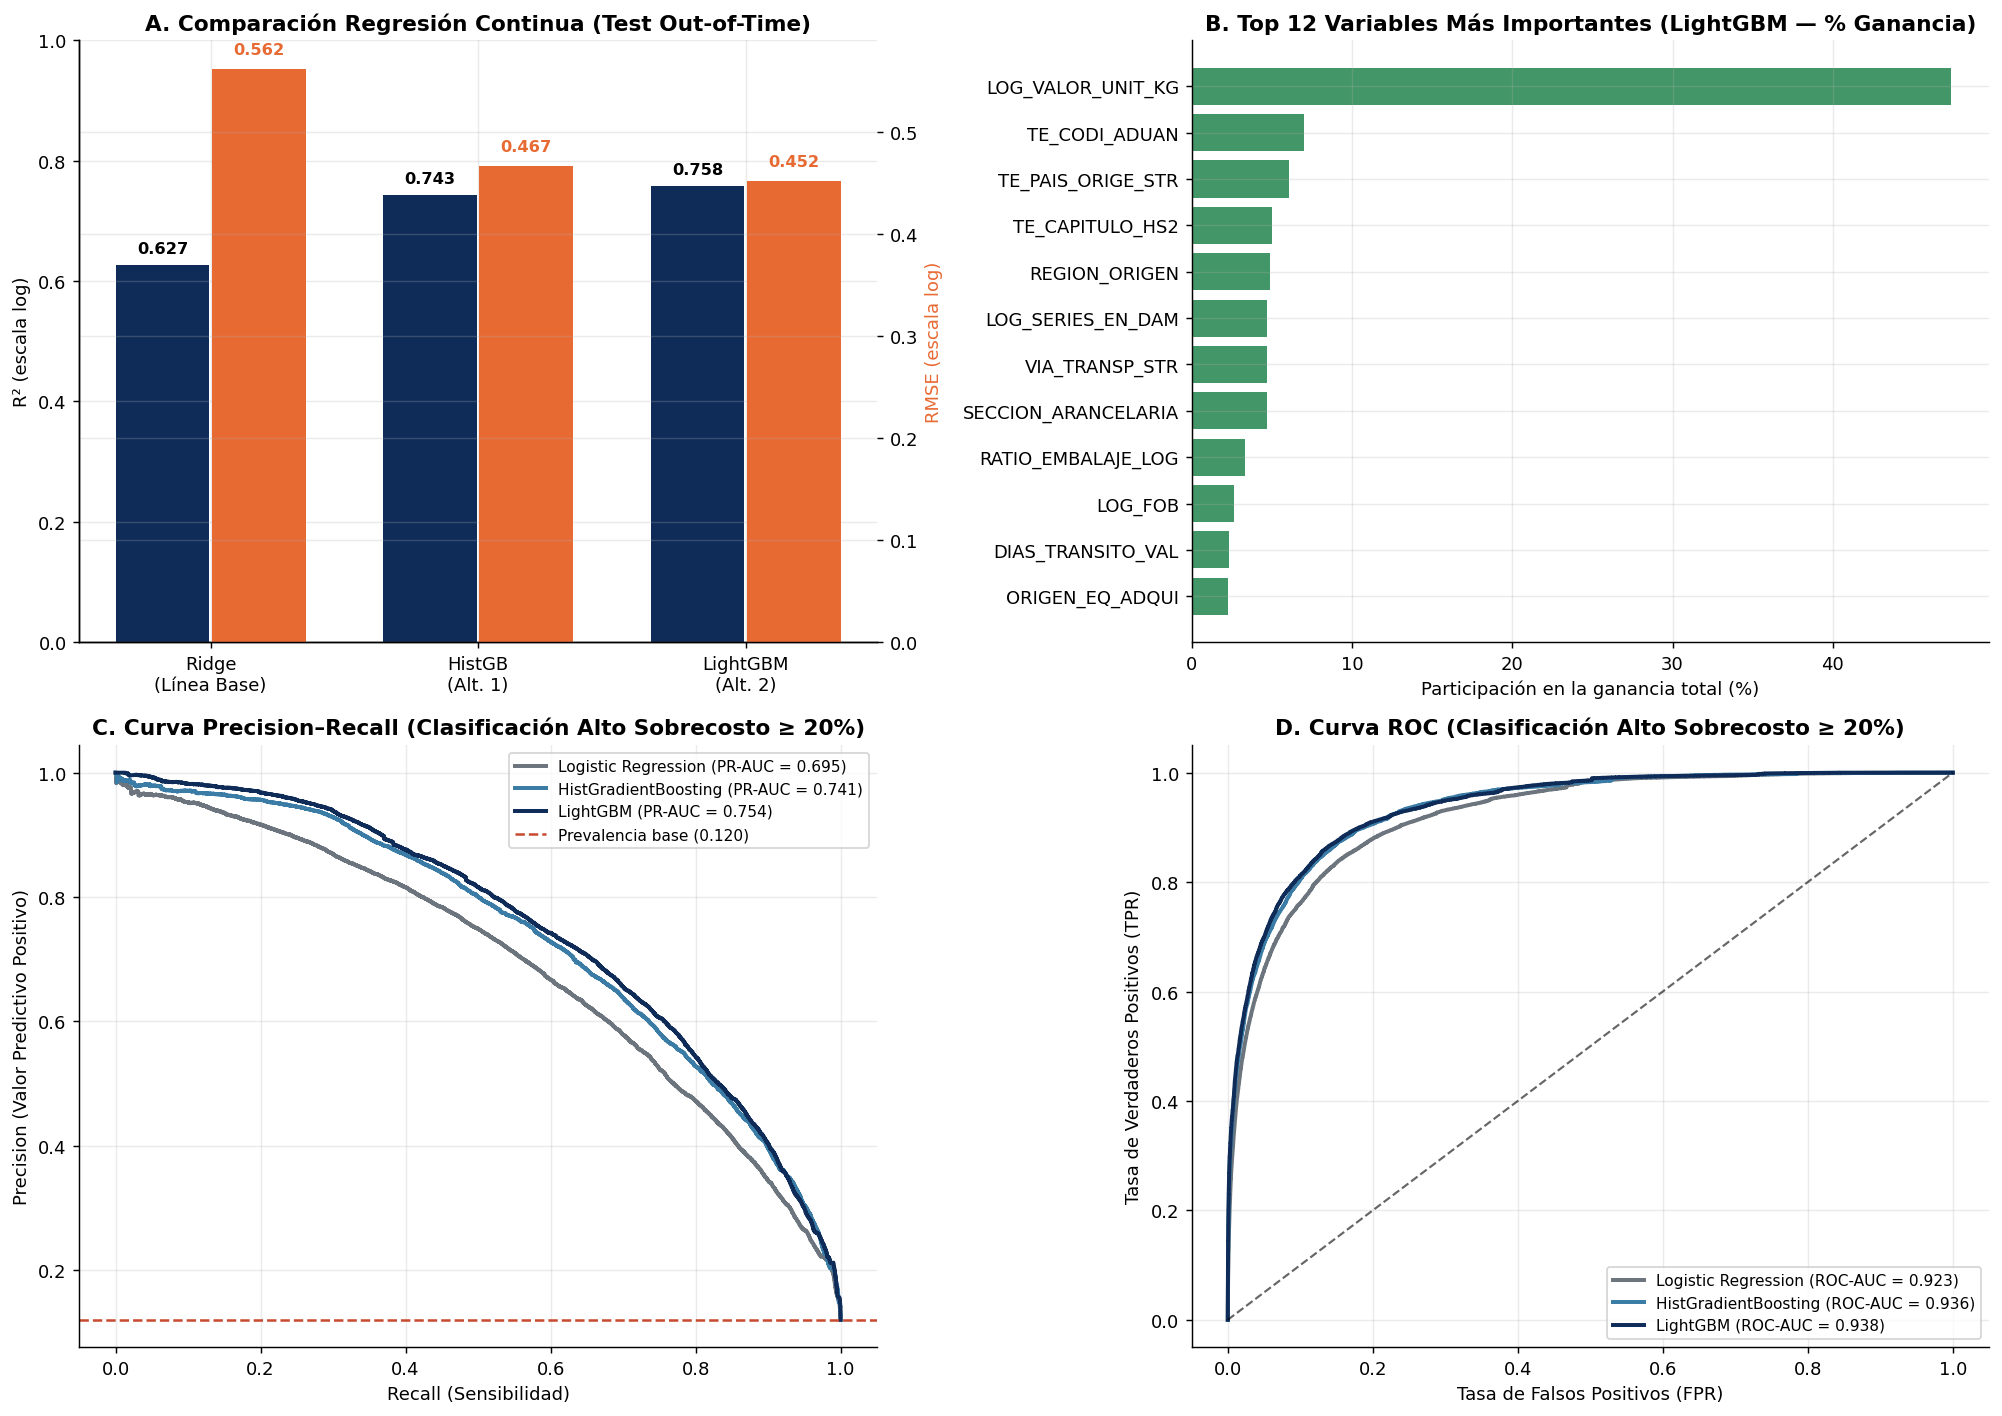

7825

In [13]:
# 8.3 Tarea 8B — Clasificación Desbalanceada: ALTO_SOBRECOSTO (>= 20% FOB)
def eval_clf(name, y_true, y_prob, thr=0.5, fit_sec=0.0):
    y_pred = (y_prob >= thr).astype(int)
    return {
        "Modelo": name,
        "ROC_AUC": round(float(roc_auc_score(y_true, y_prob)), 4),
        "PR_AUC": round(float(average_precision_score(y_true, y_prob)), 4),
        "F1": round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        "Precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        "Recall": round(float(recall_score(y_true, y_pred, zero_division=0)), 4),
        "Bal_Acc": round(float(balanced_accuracy_score(y_true, y_pred)), 4),
        "Accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "Brier": round(float(brier_score_loss(y_true, y_prob)), 4),
        "Umbral": round(float(thr), 3),
        "Tiempo_s": round(fit_sec, 1),
    }

clf_results = []
clf_probs_test = {}

# 1. Dummy Majority Baseline (evidencia por qué Accuracy engaña con clases desbalanceadas)
t0 = time.time()
dummy_clf = DummyClassifier(strategy="most_frequent").fit(X_tr_clf[ALL_NUM_REG], y_clf_train)
prob_dummy = dummy_clf.predict_proba(X_te_clf[ALL_NUM_REG])[:, 1]
clf_results.append(eval_clf("0. Dummy (Clase Mayoritaria)", y_clf_test, prob_dummy, 0.5, time.time() - t0))

# 2. Línea Base: LogisticRegression balanceada
t0 = time.time()
pipe_logit = Pipeline([
    ("prep", preproc_linear),
    ("model", LogisticRegression(class_weight="balanced", C=1.0, max_iter=200, solver="lbfgs", random_state=SEED))
])
pipe_logit.fit(X_tr_clf, y_clf_train)
prob_logit = pipe_logit.predict_proba(X_te_clf)[:, 1]
clf_probs_test["LogisticRegression"] = prob_logit
clf_results.append(eval_clf("1. Línea Base: Logistic Regression", y_clf_test, prob_logit, 0.5, time.time() - t0))

# 3. Modelo Alternativo 1: HistGradientBoostingClassifier
t0 = time.time()
hgb_clf = HistGradientBoostingClassifier(
    max_iter=200, max_depth=8, learning_rate=0.07, min_samples_leaf=80,
    class_weight="balanced", categorical_features="from_dtype", random_state=SEED
)
hgb_clf.fit(X_tr_clf, y_clf_train)
prob_hgb_c = hgb_clf.predict_proba(X_te_clf)[:, 1]
clf_probs_test["HGB"] = prob_hgb_c
clf_results.append(eval_clf("2. Alternativo: HistGradientBoosting", y_clf_test, prob_hgb_c, 0.5, time.time() - t0))

# 4. Modelo Alternativo 2: LightGBM Classifier (calibrando umbral óptimo en validación S08)
val_s8_mask = df.loc[train_mask, "SEMANA"].to_numpy() == 8
tr_s17_mask = ~val_s8_mask

t0 = time.time()
pos_weight = float((y_clf_train == 0).sum() / max(1, (y_clf_train == 1).sum()))
# Calibración de umbral estrictamente en S08 (sin tocar S09-S10)
lgb_clf_cal = lgb.LGBMClassifier(
    n_estimators=220, learning_rate=0.07, num_leaves=63, max_depth=10,
    min_child_samples=80, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    reg_lambda=2.0, random_state=SEED, n_jobs=-1, verbose=-1
)
lgb_clf_cal.fit(X_tr_clf.iloc[tr_s17_mask], y_clf_train[tr_s17_mask])
prob_s8 = lgb_clf_cal.predict_proba(X_tr_clf.iloc[val_s8_mask])[:, 1]
prec_v, rec_v, thr_v = precision_recall_curve(y_clf_train[val_s8_mask], prob_s8)
f1_v = 2 * prec_v * rec_v / np.clip(prec_v + rec_v, 1e-9, None)
best_thr_lgb = float(thr_v[np.argmax(f1_v[:-1])])

# Reentrenamiento final sobre S01-S08 completo y evaluación en S09-S10
lgb_clf = lgb.LGBMClassifier(
    n_estimators=260, learning_rate=0.07, num_leaves=63, max_depth=10,
    min_child_samples=80, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    reg_lambda=2.0, random_state=SEED, n_jobs=-1, verbose=-1
)
lgb_clf.fit(X_tr_clf, y_clf_train)
prob_lgb_c = lgb_clf.predict_proba(X_te_clf)[:, 1]
clf_probs_test["LightGBM"] = prob_lgb_c
clf_results.append(eval_clf("3. Alternativo: LightGBM (umbral S08)", y_clf_test, prob_lgb_c, best_thr_lgb, time.time() - t0))

df_clf_results = pd.DataFrame(clf_results)
print("=" * 72)
print("RESULTADOS CLASIFICACIÓN DESBALANCEADA — CONJUNTO TEMPORAL FUTURO (S09–S10)")
print("=" * 72)
display(df_clf_results)

cm_lgb = confusion_matrix(y_clf_test, (prob_lgb_c >= best_thr_lgb).astype(int))
print(f"\nMatriz de Confusión LightGBM (umbral óptimo S08 = {best_thr_lgb:.3f}):")
print(pd.DataFrame(cm_lgb, index=["Real: Normal (<20%)", "Real: Alto (>=20%)"],
                   columns=["Pred: Normal", "Pred: Alto"]))

# Figura 5: Panel diagnóstico de Modelado Supervisado (Regresión + Clasificación)
fig, axes = plt.subplots(2, 2, figsize=(15.5, 11))

# Panel A: R2 y RMSE Regresión
ax = axes[0, 0]
sub_r = df_reg_results.iloc[1:]
x_r = np.arange(len(sub_r))
bars_r = ax.bar(x_r - 0.18, sub_r["R2_log"], width=0.35, color=PALETTE_ULIMA[0], label="R² (Test S09–S10)")
ax_t = ax.twinx()
bars_e = ax_t.bar(x_r + 0.18, sub_r["RMSE_log"], width=0.35, color=PALETTE_ULIMA[1], label="RMSE (log)")
ax.set_xticks(x_r)
ax.set_xticklabels(["Ridge\n(Línea Base)", "HistGB\n(Alt. 1)", "LightGBM\n(Alt. 2)"])
ax.set_ylabel("R² (escala log)")
ax_t.set_ylabel("RMSE (escala log)", color=PALETTE_ULIMA[1])
ax.set_title("A. Comparación Regresión Continua (Test Out-of-Time)")
ax.set_ylim(0, 1.0)
ax_t.spines["top"].set_visible(False)
for b in bars_r:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02, f"{b.get_height():.3f}", ha="center", fontsize=9, fontweight="bold")
for b in bars_e:
    ax_t.text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{b.get_height():.3f}", ha="center", fontsize=9, color=PALETTE_ULIMA[1], fontweight="bold")

# Panel B: Top 12 Importancia de Variables (LightGBM Regresión)
ax = axes[0, 1]
top12_imp = imp_lgb_reg.head(12).iloc[::-1]
ax.barh(top12_imp.index, top12_imp.values, color=PALETTE_ULIMA[2], alpha=0.9)
ax.set_title("B. Top 12 Variables Más Importantes (LightGBM — % Ganancia)")
ax.set_xlabel("Participación en la ganancia total (%)")

# Panel C: Curvas Precision-Recall (métrica central en clases desbalanceadas)
ax = axes[1, 0]
for lbl, probs, col in [
    ("Logistic Regression", prob_logit, PALETTE_ULIMA[5]),
    ("HistGradientBoosting", prob_hgb_c, PALETTE_ULIMA[3]),
    ("LightGBM", prob_lgb_c, PALETTE_ULIMA[0]),
]:
    pr_p, pr_r, _ = precision_recall_curve(y_clf_test, probs)
    ap = average_precision_score(y_clf_test, probs)
    ax.plot(pr_r, pr_p, lw=2.2, color=col, label=f"{lbl} (PR-AUC = {ap:.3f})")
ax.axhline(y_clf_test.mean(), color=PALETTE_ULIMA[4], ls="--", lw=1.4, label=f"Prevalencia base ({y_clf_test.mean():.3f})")
ax.set_title("C. Curva Precision–Recall (Clasificación Alto Sobrecosto ≥ 20%)")
ax.set_xlabel("Recall (Sensibilidad)")
ax.set_ylabel("Precision (Valor Predictivo Positivo)")
ax.legend(fontsize=8.5)

# Panel D: Curvas ROC
ax = axes[1, 1]
for lbl, probs, col in [
    ("Logistic Regression", prob_logit, PALETTE_ULIMA[5]),
    ("HistGradientBoosting", prob_hgb_c, PALETTE_ULIMA[3]),
    ("LightGBM", prob_lgb_c, PALETTE_ULIMA[0]),
]:
    fpr, tpr, _ = roc_curve(y_clf_test, probs)
    auc_v = roc_auc_score(y_clf_test, probs)
    ax.plot(fpr, tpr, lw=2.2, color=col, label=f"{lbl} (ROC-AUC = {auc_v:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1.2, alpha=0.6)
ax.set_title("D. Curva ROC (Clasificación Alto Sobrecosto ≥ 20%)")
ax.set_xlabel("Tasa de Falsos Positivos (FPR)")
ax.set_ylabel("Tasa de Verdaderos Positivos (TPR)")
ax.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig05_modelos_supervisados.png", bbox_inches="tight")
plt.show()

RESUMEN_METRICAS["supervisado"] = {
    "n_train": n_train,
    "n_test": n_test,
    "regresion_tabla": reg_results,
    "regresion_train_r2": {
        "Ridge": round(float(r2_score(y_reg_train, pred_ridge_tr)), 4),
        "HGB": round(float(r2_score(y_reg_train, pred_hgb_tr)), 4),
        "LightGBM": round(float(r2_score(y_reg_train, pred_lgb_tr)), 4),
    },
    "ridge_coefs_estandarizados": {k.replace("num__", ""): round(float(v), 4) for k, v in top_coefs_num.items()},
    "lgb_reg_importancia_top15": {k: round(float(v), 2) for k, v in imp_lgb_reg.head(15).items()},
    "clasificacion_tabla": clf_results,
    "lgb_clf_umbral_optimo_s08": round(best_thr_lgb, 4),
    "lgb_clf_confusion_matrix": cm_lgb.tolist(),
}
del lgb_clf_cal
gc.collect()

---
## 9. Modelado no supervisado: Revisión de las 6 familias de clustering (12 métodos) y PCA auxiliar

### 9.1 Marco conceptual comparativo de las seis familias de clustering

Tal como exige la guía del curso y las convenciones vistas en clase con el docente Angel Agüero Correa, **el Análisis de Componentes Principales (PCA) NO constituye un algoritmo de clustering**: se utiliza estrictamente como herramienta auxiliar de reducción de dimensionalidad, diagnóstico de varianza (*scree plot*) y visualización bidimensional en el plano `(CP1, CP2)`. Asimismo:
* `k-means++` es una estrategia de inicialización de `K-Means`, **no** un algoritmo independiente.
* El dendrograma es una representación gráfica de la jerarquía aglomerativa, **no** un algoritmo en sí mismo.
* Para clustering se utilizan exclusivamente **variables continuas estandarizadas con `StandardScaler`**, excluyendo coordenadas geográficas y variables de conteo discreto que fragmentarían artificialmente los algoritmos basados en densidad.

| # | Familia de Clustering | Mecanismo central | Supuestos geométricos | Escalabilidad | Sensibilidad a escala / outliers | Dos métodos implementados | Métricas específicas evaluadas |
| :-: | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **1** | **Particiones o representantes** | Optimiza centroides o medoides minimizando disimilitud intra-grupo | Grupos convexos/esféricos y tamaños comparables | Alta (`K-Means`), Media (`FasterPAM`) | Alta a escala; `K-Medoids` más robusto a outliers | **1A. K-Means (`k-means++`)**<br>**1B. K-Medoids (FasterPAM)** | Inercia/codo, Silueta, Davies–Bouldin, Calinski–Harabasz |
| **2** | **Jerárquicos o de conectividad** | Fusión aglomerativa iterativa según criterio de enlace | Depende del enlace (`Ward`: varianza mínima; `Complete/Average`: diámetro/media) | $O(n^2)$–$O(n^3)$ (requiere muestra estratificada) | Sensible a escala y encadenamiento/outliers | **2A. Agglomerative (Ward)**<br>**2B. Agglomerative (Complete / Average)** | Correlación cofenética, dendrograma, Silueta, Calinski–Harabasz |
| **3** | **Basados en densidad** | Conecta regiones de alta densidad separadas por zonas ralas | Formas arbitrarias no convexas; detecta ruido (`-1`) | Alta-Media ($O(n \log n)$ con índices espaciales) | Muy sensible a `eps` y a variables discretas | **3A. DBSCAN** (curva k-distancias)<br>**3B. HDBSCAN** (densidad jerárquica) | % de ruido, Silueta sin ruido, estabilidad de clusters |
| **4** | **Basados en modelos / probabilísticos** | Mezcla finita o no paramétrica de distribuciones (EM / Bayes Variacional) | Grupos elipsoidales con covarianzas flexibles y pertenencia suave | Alta-Media | Sensible a escala y colas pesadas | **4A. Gaussian Mixture (GMM)**<br>**4B. Bayesian Gaussian Mixture (BGM)** | BIC, AIC, entropía posterior, pesos Dirichlet, Silueta |
| **5** | **Basados en grafos / espectrales** | Descomposición espectral de la matriz Laplaciana o paso de mensajes en grafo | Estructuras no convexas y conectividad en variedades | $O(n^2)$–$O(n^3)$ (muestra estratificada) | Sensible a afinidad (`k-NN`) y `preference` | **5A. Spectral Clustering** (autovalores)<br>**5B. Affinity Propagation** | Brecha espectral (*eigengap*), Silueta, Davies–Bouldin |
| **6** | **Cuadrícula / prototipos incrementales y difusos** | Compresión en árbol de micro-regiones (CF-Tree) o pertenencia continua difusa | Prototipos incrementales escalables (`BIRCH`) o fronteras difusas (`FCM`) | Muy alta (`BIRCH` $O(n)$) y Alta (`FCM`) | Sensible a `threshold` (`BIRCH`) y difusividad $m$ (`FCM`) | **6A. BIRCH** (CF-Tree)<br>**6B. Fuzzy C-Means (Bezdek, $m=2$)** | Coeficiente de partición ($PC$), entropía ($PE$), Silueta, Davies–Bouldin |

PCA ejecutado sobre la BASE COMPLETA: 3,155,169 registros × 7 variables continuas estandarizadas.
Varianza explicada por componente:
  CP1: autovalor = 2.393 | varianza = 34.19% | acumulada =  34.19%
  CP2: autovalor = 1.684 | varianza = 24.05% | acumulada =  58.24%
  CP3: autovalor = 1.179 | varianza = 16.85% | acumulada =  75.09%
  CP4: autovalor = 0.977 | varianza = 13.95% | acumulada =  89.04%
  CP5: autovalor = 0.474 | varianza =  6.77% | acumulada =  95.81%
  CP6: autovalor = 0.257 | varianza =  3.67% | acumulada =  99.48%
  CP7: autovalor = 0.036 | varianza =  0.52% | acumulada = 100.00%
Error cuadrático medio de reconstrucción (3 componentes, SVD): 0.2491


,CP1 (34.2%),CP2 (24.1%),CP3 (16.8%),CP4 (14.0%)
log(FOB),0.473,-0.001,-0.565,0.134
log(Peso Neto),0.607,0.137,-0.217,0.098
log(Valor/kg),-0.473,-0.242,-0.346,0.037
log(Tasa Log. %),0.241,0.191,0.679,0.304
Tasa ADV (%),-0.264,0.638,-0.114,-0.052
Carga Trib. (%),-0.131,0.688,-0.174,0.064
log(Ratio Embalaje),-0.197,-0.079,-0.098,0.934


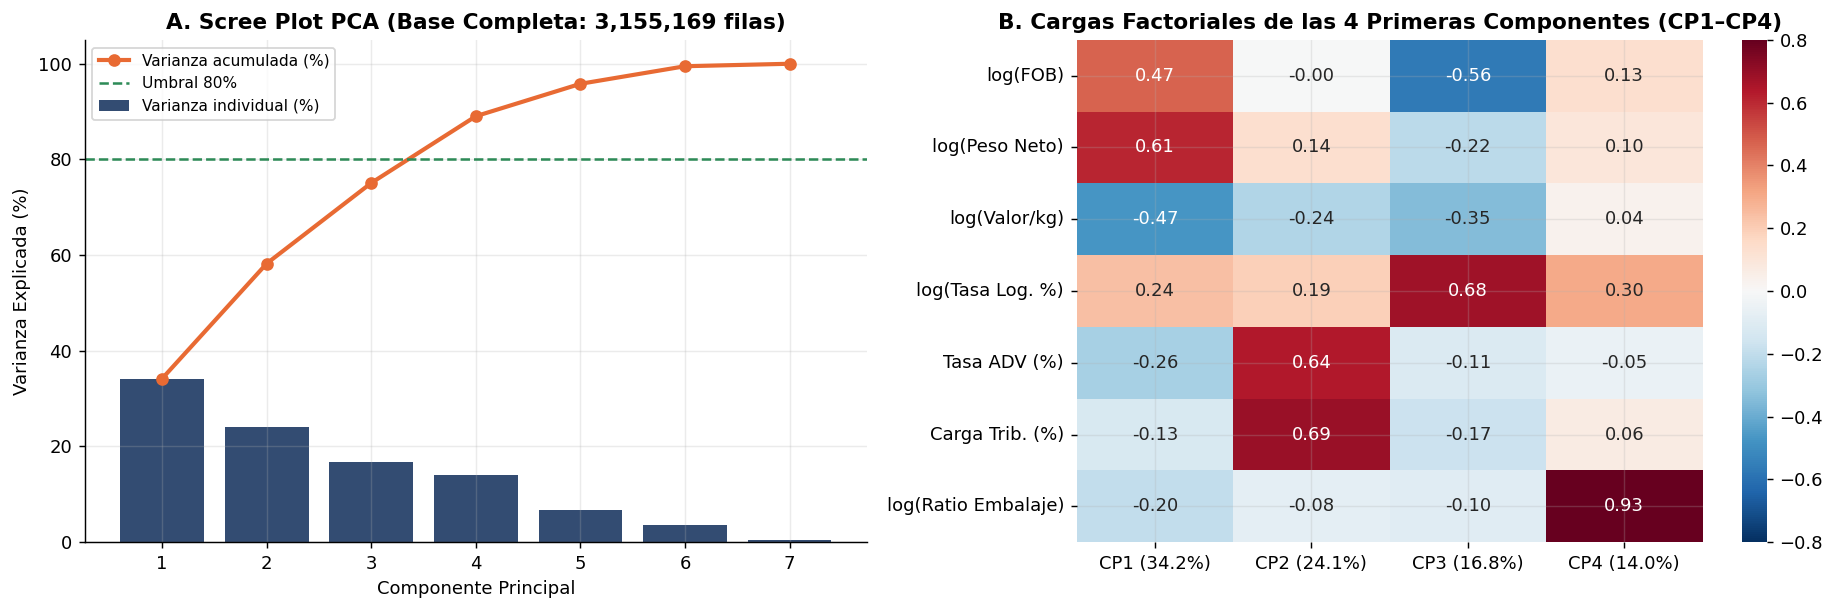

21

In [14]:
# 9.2 PCA sobre la BASE COMPLETA (> 2,000,000 filas) — estrictamente reducción de dimensionalidad y visualización
CLUST_FEATURES = [
    "LOG_FOB",                # Escala monetaria de la serie (USD)
    "LOG_PESO_NETO",          # Masa física (kg)
    "LOG_VALOR_UNIT_KG",      # Densidad de valor Alchian-Allen (USD/kg)
    "LOG_TASA_LOGISTICA",     # Sobrecosto logístico internacional (% FOB en log1p)
    "TASA_ADV_EFECTIVA_PCT",  # Protección arancelaria Ad Valorem efectiva (% CIF)
    "CARGA_TRIBUTARIA_PCT",   # Carga tributaria aduanera total (% CIF)
    "RATIO_EMBALAJE_LOG",     # Intensidad física de embalaje/tara
]
CLUST_LABELS_ES = [
    "log(FOB)", "log(Peso Neto)", "log(Valor/kg)", "log(Tasa Log. %)",
    "Tasa ADV (%)", "Carga Trib. (%)", "log(Ratio Embalaje)"
]

X_pca_full_raw = df[CLUST_FEATURES].to_numpy(dtype=np.float32)
scaler_full = StandardScaler()
X_pca_full_std = scaler_full.fit_transform(X_pca_full_raw)

pca_full = PCA(random_state=SEED)
pca_full.fit(X_pca_full_std)
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
eigenvals = pca_full.explained_variance_

# Verificación auxiliar de reconstrucción con TruncatedSVD (3 componentes)
svd_aux = TruncatedSVD(n_components=3, random_state=SEED)
Z_svd_sample = svd_aux.fit_transform(X_pca_full_std[:100_000])
recon_err_3c = float(np.mean((X_pca_full_std[:100_000] - svd_aux.inverse_transform(Z_svd_sample)) ** 2))

loadings_df = pd.DataFrame(
    pca_full.components_[:4].T,
    index=CLUST_LABELS_ES,
    columns=[f"CP{i} ({100*evr[i-1]:.1f}%)" for i in range(1, 5)]
)

print(f"PCA ejecutado sobre la BASE COMPLETA: {len(df):,d} registros × {len(CLUST_FEATURES)} variables continuas estandarizadas.")
print("Varianza explicada por componente:")
for i in range(len(evr)):
    print(f"  CP{i+1}: autovalor = {eigenvals[i]:.3f} | varianza = {100*evr[i]:5.2f}% | acumulada = {100*cum_evr[i]:6.2f}%")
print(f"Error cuadrático medio de reconstrucción (3 componentes, SVD): {recon_err_3c:.4f}")
display(loadings_df.round(3))

# Figura 6: Scree plot y mapa de cargas factoriales PCA (base completa)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
comps = np.arange(1, len(evr) + 1)
axes[0].bar(comps, 100 * evr, color=PALETTE_ULIMA[0], alpha=0.85, label="Varianza individual (%)")
axes[0].plot(comps, 100 * cum_evr, color=PALETTE_ULIMA[1], marker="o", lw=2.3, label="Varianza acumulada (%)")
axes[0].axhline(80, color=PALETTE_ULIMA[2], ls="--", lw=1.4, label="Umbral 80%")
axes[0].set_title(f"A. Scree Plot PCA (Base Completa: {len(df):,} filas)")
axes[0].set_xlabel("Componente Principal")
axes[0].set_ylabel("Varianza Explicada (%)")
axes[0].set_xticks(comps)
axes[0].legend(fontsize=8.5)

sns.heatmap(loadings_df, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.8, vmax=0.8, ax=axes[1])
axes[1].set_title("B. Cargas Factoriales de las 4 Primeras Componentes (CP1–CP4)")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig06_pca_scree_y_cargas.png", bbox_inches="tight")
plt.show()

del X_pca_full_raw, X_pca_full_std
gc.collect()

### 9.3 Muestra estratificada reproducible para clustering (`random_state = 2026`)

Ejecutar algoritmos de complejidad cuadrática o cúbica en memoria/tiempo —como **Jerárquico aglomerativo** (matriz de distancias $n \times n$), **Spectral Clustering**, **Affinity Propagation** y **K-Medoids**— directamente sobre más de 2 millones de filas requeriría varios terabytes de RAM. Por ello, siguiendo exactamente la convención del curso:
1. Se extrae una **muestra estratificada reproducible (`N_CLUST_FULL = 12,000`, `random_state = 2026`)** preservando las proporciones conjuntas de **Vía de Transporte × Región de Origen** para el perfilamiento económico final y los algoritmos escalables (`K-Means`, `GMM`, `BGM`, `BIRCH`, `Fuzzy C-Means`, `DBSCAN`, `HDBSCAN`).
2. De ella se extrae una **submuestra estratificada anidada (`N_CLUST_BENCH = 3,000`, `random_state = 2026`)** sobre la cual se ejecutan y comparan **los 12 algoritmos de las 6 familias exactamente sobre las mismas observaciones**, garantizando una matriz de concordancia **ARI 12 × 12** y métricas internas estrictamente comparables.

In [15]:
# 9.3 Construcción de muestras estratificadas reproducibles (N=12,000 y benchmark común N=3,000)
strata = df["VIA_TRANSP_DESC"].astype(str) + "_" + df["REGION_ORIGEN"].astype(str)
strata_counts = strata.value_counts()
valid_strata = strata.where(strata.map(strata_counts) >= 200, "OTROS_ESTRATOS")

N_CLUST_FULL = 12_000
N_CLUST_BENCH = 3_000

# Muestreo estratificado proporcional determinístico con SEED = 2026
rng = np.random.default_rng(SEED)
df_idx_series = pd.Series(df.index.to_numpy(), index=df.index)
sample_indices = []
for st_val, grp in valid_strata.groupby(valid_strata):
    n_take = max(1, int(round(N_CLUST_FULL * len(grp) / len(df))))
    chosen = rng.choice(grp.index.to_numpy(), size=min(n_take, len(grp)), replace=False)
    sample_indices.append(chosen)
sample_indices = np.concatenate(sample_indices)
if len(sample_indices) > N_CLUST_FULL:
    sample_indices = rng.choice(sample_indices, size=N_CLUST_FULL, replace=False)

df_clust_full = df.loc[sample_indices].copy().reset_index(drop=True)
scaler_clust = StandardScaler()
X_c_full = scaler_clust.fit_transform(df_clust_full[CLUST_FEATURES].to_numpy(dtype=np.float64))
Z_pca_full = pca_full.transform(scaler_full.transform(df_clust_full[CLUST_FEATURES].to_numpy(dtype=np.float32)))[:, :2]  # Coordenadas CP1 y CP2 solo para visualización

# Submuestra estratificada común de benchmark (N = 3,000) para comparar las 6 familias / 12 métodos 1-a-1
strata_sub = df_clust_full["VIA_TRANSP_DESC"].astype(str)
bench_indices = []
for st_val, grp in strata_sub.groupby(strata_sub):
    n_take = max(1, int(round(N_CLUST_BENCH * len(grp) / len(df_clust_full))))
    chosen = rng.choice(grp.index.to_numpy(), size=min(n_take, len(grp)), replace=False)
    bench_indices.append(chosen)
bench_indices = np.concatenate(bench_indices)
if len(bench_indices) > N_CLUST_BENCH:
    bench_indices = rng.choice(bench_indices, size=N_CLUST_BENCH, replace=False)
bench_indices = np.sort(bench_indices)

df_bench = df_clust_full.iloc[bench_indices].copy().reset_index(drop=True)
X_bench = X_c_full[bench_indices]
Z_pca_bench = Z_pca_full[bench_indices]

print(f"Muestra estratificada principal : {len(df_clust_full):,d} observaciones × {X_c_full.shape[1]} variables estandarizadas")
print(f"Submuestra común de benchmark   : {len(df_bench):,d} observaciones (para comparación directa ARI 12×12)")
print("Verificación representatividad (% FOB por vía principal — Universo vs Muestra 12k):")
for v in eda_via["VIA_TRANSP_DESC"].head(3):
    p_univ = 100 * (df["VIA_TRANSP_DESC"] == v).mean()
    p_samp = 100 * (df_clust_full["VIA_TRANSP_DESC"] == v).mean()
    print(f"  - {str(v):12s}: Universo = {p_univ:5.2f}% | Muestra = {p_samp:5.2f}%")

Muestra estratificada principal : 12,000 observaciones × 7 variables estandarizadas
Submuestra común de benchmark   : 3,000 observaciones (para comparación directa ARI 12×12)
Verificación representatividad (% FOB por vía principal — Universo vs Muestra 12k):
  - VAPOR       : Universo = 65.85% | Muestra = 65.84%
  - AVION       : Universo = 30.96% | Muestra = 30.96%
  - CAMION      : Universo =  3.19% | Muestra =  3.19%


In [16]:
# 9.4 Ejecución sistemática de las 6 FAMILIAS × 2 MÉTODOS = 12 ALGORITMOS DE CLUSTERING
def eval_cluster_labels(X_mat, labels, familia, metodo, metric_extra_str, runtime_s):
    labels = np.asarray(labels)
    mask_valid = labels != -1
    pct_noise = 100.0 * (1.0 - mask_valid.mean())
    unique_valid = np.unique(labels[mask_valid])
    n_clusters = int(len(unique_valid))
    if n_clusters >= 2 and mask_valid.sum() > n_clusters + 5:
        Xv = X_mat[mask_valid]
        lv = labels[mask_valid]
        sil = float(silhouette_score(Xv, lv))
        db = float(davies_bouldin_score(Xv, lv))
        ch = float(calinski_harabasz_score(Xv, lv))
    else:
        sil, db, ch = np.nan, np.nan, np.nan
    return {
        "Familia": familia,
        "Metodo": metodo,
        "K_efectivo": n_clusters,
        "Ruido_pct": round(pct_noise, 2),
        "Silueta": round(sil, 4) if not np.isnan(sil) else np.nan,
        "Davies_Bouldin": round(db, 4) if not np.isnan(db) else np.nan,
        "Calinski_Harabasz": round(ch, 1) if not np.isnan(ch) else np.nan,
        "Metrica_Especifica": metric_extra_str,
        "Tiempo_s": round(runtime_s, 2),
    }

bench_labels = {}
bench_summary = []

# =====================================================================
# FAMILIA 1: PARTICIONES O REPRESENTANTES (K-Means + K-Medoids)
# =====================================================================
print("\n[Familia 1] Particiones o representantes: K-Means (k-means++) y K-Medoids...")
km_k_grid = list(range(2, 9))
km_inertias, km_sils, km_chs = [], [], []
for k in km_k_grid:
    km_tmp = KMeans(n_clusters=k, init="k-means++", n_init=15, random_state=SEED)
    lbl_tmp = km_tmp.fit_predict(X_bench)
    km_inertias.append(float(km_tmp.inertia_))
    km_sils.append(float(silhouette_score(X_bench, lbl_tmp)))
    km_chs.append(float(calinski_harabasz_score(X_bench, lbl_tmp)))

# Selección justificada de k óptimo entre k=4..6 balanceando Silueta, codo e interpretabilidad económica
cand_k_slice = [k for k in km_k_grid if 4 <= k <= 6]
best_k_km = cand_k_slice[int(np.argmax([km_sils[km_k_grid.index(k)] for k in cand_k_slice]))]

t0 = time.time()
km_bench = KMeans(n_clusters=best_k_km, init="k-means++", n_init=20, random_state=SEED)
lbl_km = km_bench.fit_predict(X_bench)
t_km = time.time() - t0
bench_labels["1A. K-Means"] = lbl_km
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_km, "1. Particiones", "1A. K-Means (k-means++)",
    f"Inercia={km_bench.inertia_:,.0f} (k={best_k_km})", t_km
))

# 1B. K-Medoids (FasterPAM sobre matriz de distancias euclidianas; fallback PAM limpio en NumPy)
t0 = time.time()
dist_mat_bench = cdist(X_bench, X_bench, metric="euclidean")
if HAS_KMEDOIDS:
    kmed_res = kmedoids.fasterpam(dist_mat_bench, best_k_km, random_state=SEED)
    lbl_kmed = np.asarray(kmed_res.labels, dtype=int)
    kmed_loss = float(kmed_res.loss)
    kmed_note = f"FasterPAM pérdida={kmed_loss:,.0f} (k={best_k_km})"
else:
    # Fallback PAM/medoides a partir de centroides más cercanos
    med_idx = np.argmin(cdist(km_bench.cluster_centers_, X_bench), axis=1)
    for _ in range(15):
        lbl_kmed = np.argmin(dist_mat_bench[:, med_idx], axis=1)
        new_med = []
        for c in range(best_k_km):
            pts = np.where(lbl_kmed == c)[0]
            sub_d = dist_mat_bench[np.ix_(pts, pts)].sum(axis=1)
            new_med.append(pts[np.argmin(sub_d)])
        if np.array_equal(med_idx, new_med):
            break
        med_idx = np.array(new_med)
    lbl_kmed = np.argmin(dist_mat_bench[:, med_idx], axis=1)
    kmed_note = f"PAM exacto (k={best_k_km})"
t_kmed = time.time() - t0
bench_labels["1B. K-Medoids"] = lbl_kmed
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_kmed, "1. Particiones", "1B. K-Medoids (FasterPAM)", kmed_note, t_kmed
))

# =====================================================================
# FAMILIA 2: JERÁRQUICOS O DE CONECTIVIDAD (Ward + Complete/Average)
# =====================================================================
print("[Familia 2] Jerárquicos o de conectividad: Ward y Complete/Average...")
pdist_bench = pdist(X_bench, metric="euclidean")

# 2A. Ward
t0 = time.time()
Z_ward = linkage(X_bench, method="ward")
coph_ward, _ = cophenet(Z_ward, pdist_bench)
lbl_ward = AgglomerativeClustering(n_clusters=best_k_km, linkage="ward").fit_predict(X_bench)
t_ward = time.time() - t0
bench_labels["2A. Jerárq. Ward"] = lbl_ward
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_ward, "2. Jerárquicos", "2A. Agglomerative (Ward)",
    f"Cofenética={coph_ward:.3f} (k={best_k_km})", t_ward
))

# 2B. Complete vs Average (evaluamos ambos con correlación cofenética y reportamos el de mejor balance)
t0 = time.time()
Z_comp = linkage(X_bench, method="complete")
coph_comp, _ = cophenet(Z_comp, pdist_bench)
lbl_comp = AgglomerativeClustering(n_clusters=best_k_km, linkage="complete").fit_predict(X_bench)
sil_comp = float(silhouette_score(X_bench, lbl_comp))

Z_avg = linkage(X_bench, method="average")
coph_avg, _ = cophenet(Z_avg, pdist_bench)
lbl_avg = AgglomerativeClustering(n_clusters=best_k_km, linkage="average").fit_predict(X_bench)
sil_avg = float(silhouette_score(X_bench, lbl_avg))
t_comp_avg = time.time() - t0

# Elegir entre Average y Complete el que combine mejor estructura no degenerada
min_sz_avg = int(pd.Series(lbl_avg).value_counts().min())
min_sz_comp = int(pd.Series(lbl_comp).value_counts().min())
if sil_avg >= sil_comp and min_sz_avg >= 10:
    lbl_hier2 = lbl_avg
    hier2_name = "2B. Agglomerative (Average)"
    hier2_note = f"Cofenética Avg={coph_avg:.3f} (vs Comp={coph_comp:.3f})"
else:
    lbl_hier2 = lbl_comp
    hier2_name = "2B. Agglomerative (Complete)"
    hier2_note = f"Cofenética Comp={coph_comp:.3f} (vs Avg={coph_avg:.3f})"
bench_labels["2B. Jerárq. Avg/Comp"] = lbl_hier2
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_hier2, "2. Jerárquicos", hier2_name, hier2_note, t_comp_avg
))

# =====================================================================
# FAMILIA 3: BASADOS EN DENSIDAD (DBSCAN + HDBSCAN)
# =====================================================================
print("[Familia 3] Basados en densidad: DBSCAN (k-distancias) y HDBSCAN...")
min_samples_db = 2 * X_bench.shape[1]  # regla clásica 2*d = 14
nn_fit = NearestNeighbors(n_neighbors=min_samples_db).fit(X_bench)
k_dists = np.sort(nn_fit.kneighbors(X_bench)[0][:, -1])

# Búsqueda sistemática de eps alrededor del codo de k-distancias (percentiles 75 a 95)
t0 = time.time()
eps_candidates = np.quantile(k_dists, [0.75, 0.80, 0.85, 0.88, 0.90, 0.93, 0.95])
best_db_score, best_eps, lbl_db = -1.0, float(eps_candidates[3]), None
for eps_c in eps_candidates:
    cand_lbl = DBSCAN(eps=float(eps_c), min_samples=min_samples_db).fit_predict(X_bench)
    valid_m = cand_lbl != -1
    n_cl = len(np.unique(cand_lbl[valid_m]))
    noise_r = 1.0 - valid_m.mean()
    if n_cl >= 2 and noise_r <= 0.35 and valid_m.sum() > 50:
        s_val = float(silhouette_score(X_bench[valid_m], cand_lbl[valid_m]))
        if s_val > best_db_score:
            best_db_score = s_val
            best_eps = float(eps_c)
            lbl_db = cand_lbl
if lbl_db is None:
    best_eps = float(np.quantile(k_dists, 0.85))
    lbl_db = DBSCAN(eps=best_eps, min_samples=min_samples_db).fit_predict(X_bench)
t_db = time.time() - t0
bench_labels["3A. DBSCAN"] = lbl_db
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_db, "3. Densidad", "3A. DBSCAN",
    f"eps={best_eps:.2f}, min_samples={min_samples_db}", t_db
))

# 3B. HDBSCAN (nativo en sklearn.cluster.HDBSCAN)
t0 = time.time()
hdb = HDBSCAN(min_cluster_size=60, min_samples=15, store_centers=None)
lbl_hdb = hdb.fit_predict(X_bench)
if len(np.unique(lbl_hdb[lbl_hdb != -1])) < 2:
    hdb = HDBSCAN(min_cluster_size=30, min_samples=10)
    lbl_hdb = hdb.fit_predict(X_bench)
t_hdb = time.time() - t0
mean_prob_hdb = float(np.mean(hdb.probabilities_[lbl_hdb != -1])) if (lbl_hdb != -1).any() else 0.0
bench_labels["3B. HDBSCAN"] = lbl_hdb
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_hdb, "3. Densidad", "3B. HDBSCAN",
    f"Prob. media pertenencia={mean_prob_hdb:.3f}", t_hdb
))

# =====================================================================
# FAMILIA 4: BASADOS EN MODELOS / PROBABILÍSTICOS (GMM + BGM)
# =====================================================================
print("[Familia 4] Basados en modelos / probabilísticos: GMM (EM/BIC/AIC) y Bayesian GMM...")
gmm_k_grid = list(range(2, 9))
gmm_bics, gmm_aics = [], []
for k in gmm_k_grid:
    g_tmp = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=SEED).fit(X_bench)
    gmm_bics.append(float(g_tmp.bic(X_bench)))
    gmm_aics.append(float(g_tmp.aic(X_bench)))

# Elegimos k óptimo con parsimonia (k=best_k_km o mínimo BIC acotado para interpretabilidad económica)
best_k_gmm = best_k_km
t0 = time.time()
gmm_bench = GaussianMixture(n_components=best_k_gmm, covariance_type="full", n_init=5, random_state=SEED).fit(X_bench)
lbl_gmm = gmm_bench.predict(X_bench)
probs_gmm = gmm_bench.predict_proba(X_bench)
entropia_gmm = float(-np.mean(np.sum(probs_gmm * np.log(np.clip(probs_gmm, 1e-12, 1.0)), axis=1)))
t_gmm = time.time() - t0
bench_labels["4A. GMM (EM)"] = lbl_gmm
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_gmm, "4. Probabilísticos", "4A. Gaussian Mixture (GMM)",
    f"BIC={gmm_bench.bic(X_bench):,.0f}, Entropía={entropia_gmm:.3f}", t_gmm
))

# 4B. Bayesian Gaussian Mixture (Dirichlet Process)
t0 = time.time()
bgm_bench = BayesianGaussianMixture(
    n_components=8, covariance_type="full", weight_concentration_prior_type="dirichlet_process",
    weight_concentration_prior=0.15, max_iter=300, n_init=3, random_state=SEED
).fit(X_bench)
lbl_bgm = bgm_bench.predict(X_bench)
n_active_bgm = int((bgm_bench.weights_ > 0.02).sum())
t_bgm = time.time() - t0
bench_labels["4B. Bayesian GMM"] = lbl_bgm
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_bgm, "4. Probabilísticos", "4B. Bayesian GMM (Dirichlet)",
    f"Comp. activos (>2%)={n_active_bgm}/8, ELBO={bgm_bench.lower_bound_:,.1f}", t_bgm
))

# =====================================================================
# FAMILIA 5: BASADOS EN GRAFOS / ESPECTRALES (Spectral + Affinity Propagation)
# =====================================================================
print("[Familia 5] Basados en grafos / espectrales: Spectral Clustering y Affinity Propagation...")
# 5A. Spectral Clustering (con diagnóstico de autovalores de la matriz Laplaciana)
t0 = time.time()
spec_bench = SpectralClustering(
    n_clusters=best_k_km, affinity="nearest_neighbors", n_neighbors=20,
    assign_labels="kmeans", random_state=SEED
)
lbl_spec = spec_bench.fit_predict(X_bench)
t_spec = time.time() - t0

# Cálculo explícito de los primeros 8 autovalores de la Laplaciana normalizada (vínculo con teoría de clase)
from scipy.sparse.csgraph import laplacian
from scipy.sparse.linalg import eigsh
try:
    W_knn = spec_bench.affinity_matrix_
    W_sym = 0.5 * (W_knn + W_knn.T)
    L_norm = laplacian(W_sym, normed=True)
    eigvals_lap = np.sort(np.real(eigsh(L_norm, k=8, which="SM", return_eigenvectors=False)))
    eigengaps = np.diff(eigvals_lap)
    spec_note = f"λ2={eigvals_lap[1]:.4f}, max eigengap en k={int(np.argmax(eigengaps[1:6])+2)}"
except Exception:
    spec_note = f"Grafo k-NN=20 (k={best_k_km})"

bench_labels["5A. Spectral"] = lbl_spec
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_spec, "5. Grafos / Espectral", "5A. Spectral Clustering (k-NN)",
    spec_note, t_spec
))

# 5B. Affinity Propagation (calibración de preference para evitar fragmentación excesiva en >50 microgrupos)
t0 = time.time()
sim_mat = -(dist_mat_bench ** 2)
med_sim = float(np.median(sim_mat))
lbl_ap = None
used_pref = med_sim
for mult in [35.0, 25.0, 18.0, 12.0, 8.0, 5.0]:
    pref_val = med_sim * mult
    ap_tmp = AffinityPropagation(affinity="precomputed", damping=0.85, preference=pref_val, max_iter=300, random_state=SEED)
    cand_ap = ap_tmp.fit_predict(sim_mat)
    n_ap = len(np.unique(cand_ap))
    if 3 <= n_ap <= 10:
        lbl_ap = cand_ap
        used_pref = pref_val
        break
if lbl_ap is None:
    ap_tmp = AffinityPropagation(affinity="precomputed", damping=0.9, preference=med_sim * 20.0, max_iter=300, random_state=SEED)
    lbl_ap = ap_tmp.fit_predict(sim_mat)
    used_pref = med_sim * 20.0
t_ap = time.time() - t0
bench_labels["5B. Affinity Prop."] = lbl_ap
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_ap, "5. Grafos / Espectral", "5B. Affinity Propagation",
    f"preference={used_pref:,.0f}, ejemplares={len(np.unique(lbl_ap))}", t_ap
))

# =====================================================================
# FAMILIA 6: CUADRÍCULA / PROTOTIPOS INCREMENTALES Y DIFUSOS (BIRCH + Fuzzy C-Means)
# =====================================================================
print("[Familia 6] Cuadrícula/prototipos incrementales y difusos: BIRCH y Fuzzy C-Means...")
# 6A. BIRCH (CF-Tree jerárquico-cuadrícula incremental)
t0 = time.time()
birch_bench = Birch(threshold=1.1, branching_factor=50, n_clusters=best_k_km)
lbl_birch = birch_bench.fit_predict(X_bench)
n_sub_birch = len(birch_bench.subcluster_centers_)
t_birch = time.time() - t0
bench_labels["6A. BIRCH"] = lbl_birch
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_birch, "6. Cuadrícula / Difuso", "6A. BIRCH (CF-Tree)",
    f"Subclusters CF={n_sub_birch} (thr=1.1)", t_birch
))

# 6B. Fuzzy C-Means (Algoritmo exacto de Bezdek 1981, difusividad m=2.0)
def fit_fuzzy_cmeans(X_mat, n_clusters=5, m=2.0, max_iter=150, tol=1e-5, seed=SEED):
    rng_f = np.random.default_rng(seed)
    n_obs = X_mat.shape[0]
    U = rng_f.dirichlet(np.ones(n_clusters), size=n_obs)  # matriz de pertenencia difusa (n x k)
    for _ in range(max_iter):
        Um = U ** m
        centers = (Um.T @ X_mat) / np.clip(Um.sum(axis=0)[:, None], 1e-12, None)
        dists = np.clip(cdist(X_mat, centers, metric="euclidean"), 1e-10, None)
        power = 2.0 / (m - 1.0)
        inv_d = dists ** (-power)
        U_new = inv_d / np.clip(inv_d.sum(axis=1, keepdims=True), 1e-12, None)
        if np.max(np.abs(U_new - U)) < tol:
            U = U_new
            break
        U = U_new
    pc = float(np.mean(np.sum(U ** 2, axis=1)))                                    # Coeficiente de Partición Bezdek [1/k, 1]
    pe = float(-np.mean(np.sum(U * np.log(np.clip(U, 1e-12, 1.0)), axis=1)))       # Entropía de Partición
    labels_crisp = np.argmax(U, axis=1)
    return labels_crisp, U, centers, pc, pe

t0 = time.time()
lbl_fcm, U_fcm, centers_fcm, fcm_pc, fcm_pe = fit_fuzzy_cmeans(X_bench, n_clusters=best_k_km, m=2.0, seed=SEED)
t_fcm = time.time() - t0
bench_labels["6B. Fuzzy C-Means"] = lbl_fcm
bench_summary.append(eval_cluster_labels(
    X_bench, lbl_fcm, "6. Cuadrícula / Difuso", "6B. Fuzzy C-Means (Bezdek m=2)",
    f"PC={fcm_pc:.3f}, PE={fcm_pe:.3f}", t_fcm
))

df_clust_master = pd.DataFrame(bench_summary)
print("\n" + "=" * 88)
print("TABLA MAESTRA COMPARATIVA: 6 FAMILIAS × 2 MÉTODOS = 12 ALGORITMOS (BENCHMARK COMÚN N=3,000)")
print("=" * 88)
display(df_clust_master)


[Familia 1] Particiones o representantes: K-Means (k-means++) y K-Medoids...
[Familia 2] Jerárquicos o de conectividad: Ward y Complete/Average...
[Familia 3] Basados en densidad: DBSCAN (k-distancias) y HDBSCAN...
[Familia 4] Basados en modelos / probabilísticos: GMM (EM/BIC/AIC) y Bayesian GMM...
[Familia 5] Basados en grafos / espectrales: Spectral Clustering y Affinity Propagation...
[Familia 6] Cuadrícula/prototipos incrementales y difusos: BIRCH y Fuzzy C-Means...

TABLA MAESTRA COMPARATIVA: 6 FAMILIAS × 2 MÉTODOS = 12 ALGORITMOS (BENCHMARK COMÚN N=3,000)


,Familia,Metodo,K_efectivo,Ruido_pct,Silueta,Davies_Bouldin,Calinski_Harabasz,Metrica_Especifica,Tiempo_s
0,1. Particiones,1A. K-Means (k-means++),4,0.00,0.2674,1.2688,840.4,"Inercia=11,645 (k=4)",0.14
1,1. Particiones,1B. K-Medoids (FasterPAM),4,0.00,0.2069,1.5080,738.4,"FasterPAM pérdida=5,367 (k=4)",1.07
2,2. Jerárquicos,2A. Agglomerative (Ward),4,0.00,0.2276,1.3590,657.9,Cofenética=0.409 (k=4),1.13
3,2. Jerárquicos,2B. Agglomerative (Complete),4,0.00,0.5819,0.7621,97.4,Cofenética Comp=0.560 (vs Avg=0.773),2.18
4,3. Densidad,3A. DBSCAN,2,2.70,0.2580,1.5728,876.5,"eps=1.45, min_samples=14",1.99
5,3. Densidad,3B. HDBSCAN,4,13.03,0.2161,1.7952,481.4,Prob. media pertenencia=0.704,0.15
6,4. Probabilísticos,4A. Gaussian Mixture (GMM),4,0.00,0.1659,4.6677,361.1,"BIC=5,706, Entropía=0.047",1.29
7,4. Probabilísticos,4B. Bayesian GMM (Dirichlet),8,0.00,0.0823,2.8966,250.2,"Comp. activos (>2%)=8/8, ELBO=12,288.3",3.70
8,5. Grafos / Espectral,5A. Spectral Clustering (k-NN),4,0.00,0.1653,2.0162,365.0,"λ2=0.0031, max eigengap en k=6",0.87
9,5. Grafos / Espectral,5B. Affinity Propagation,16,0.00,0.2106,1.1974,520.0,"preference=-227, ejemplares=16",78.51


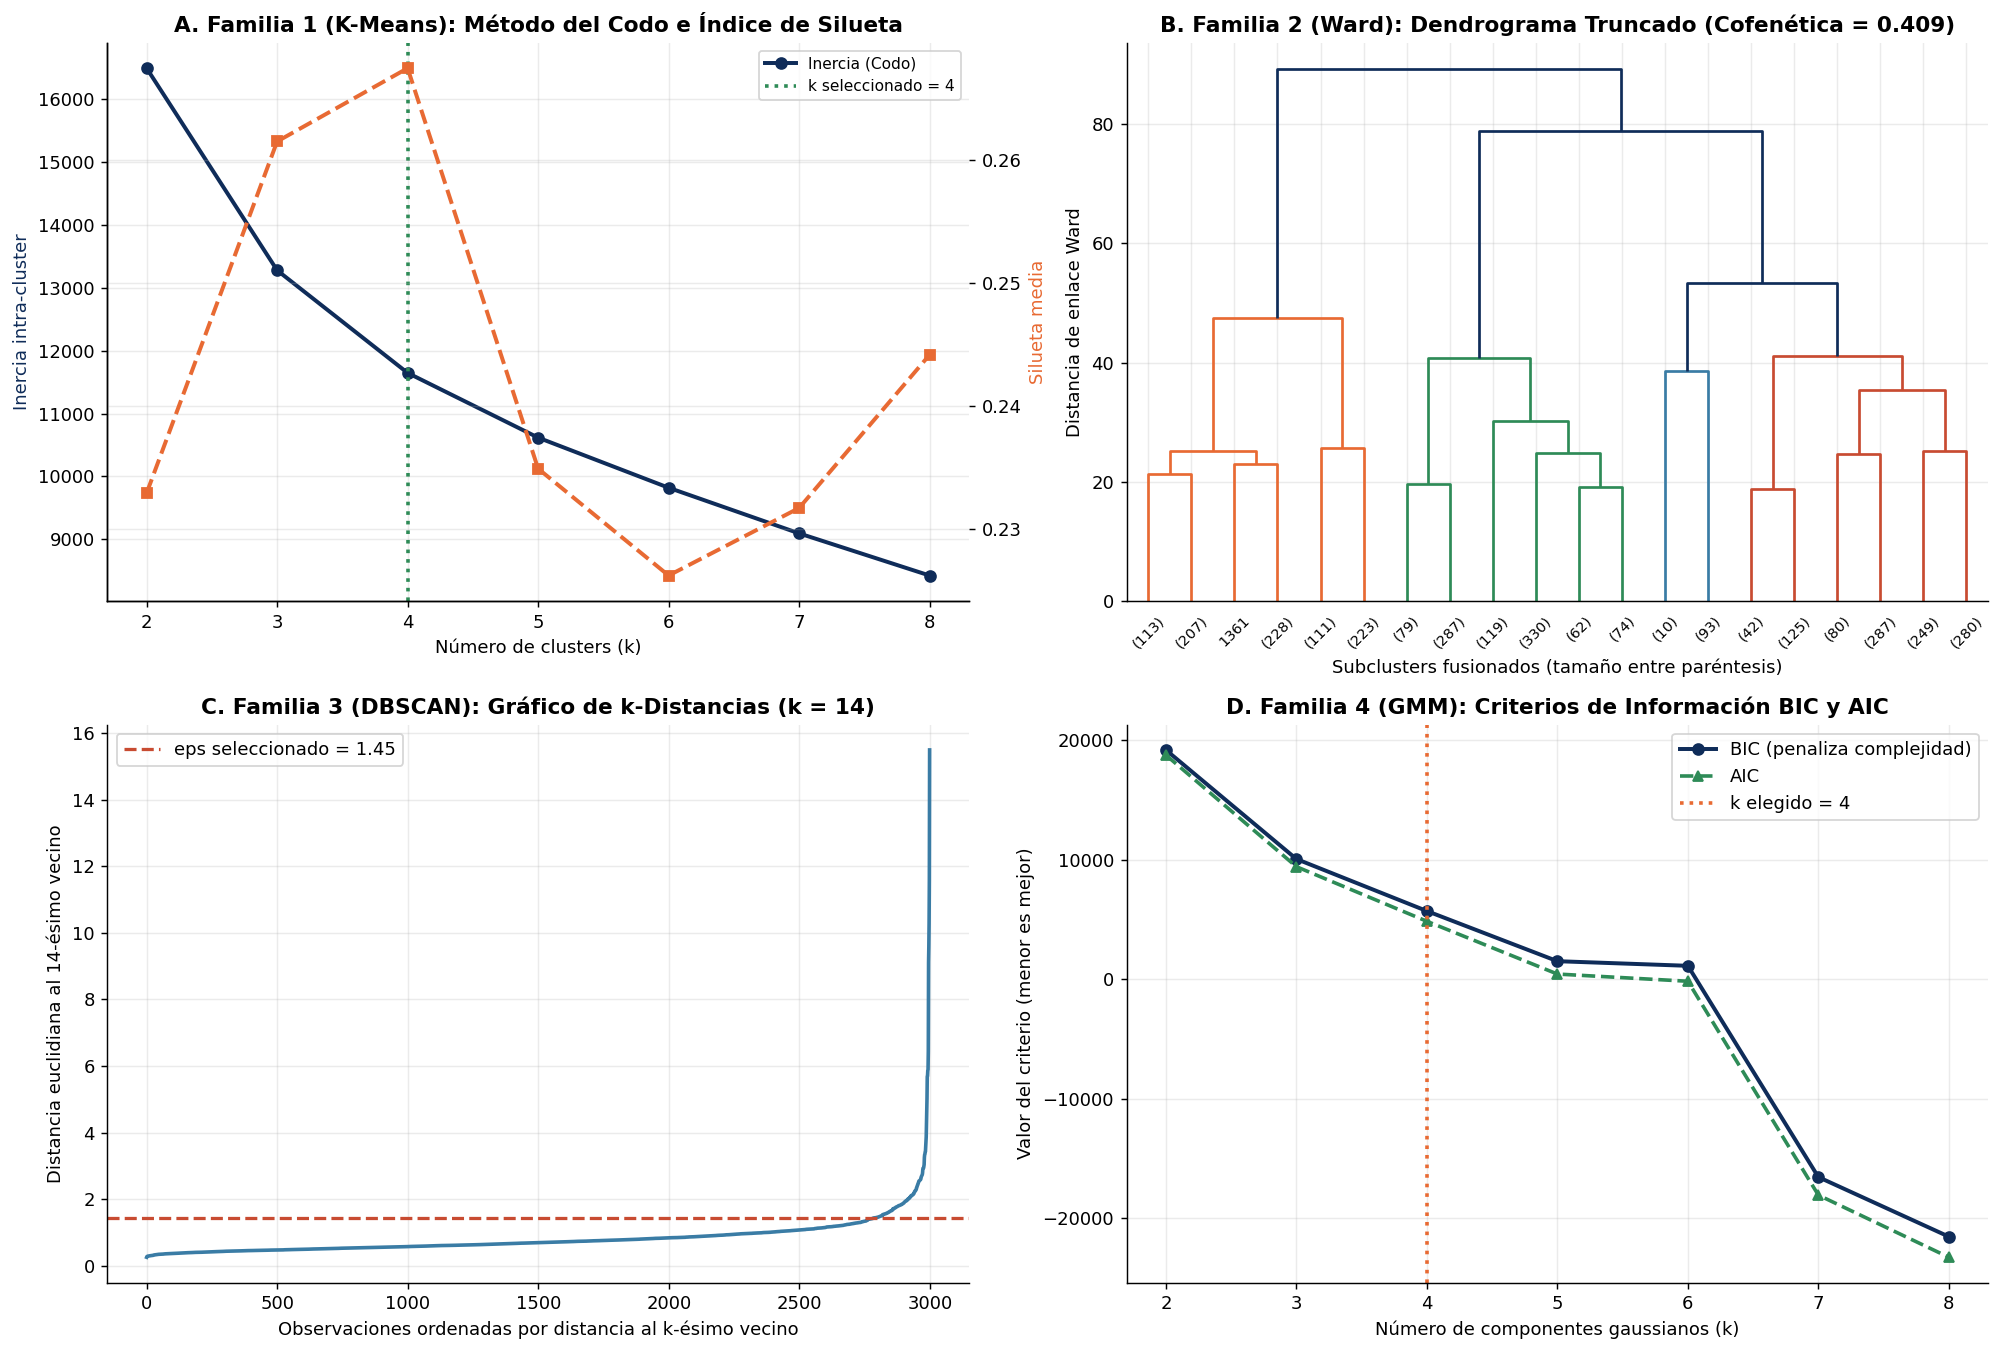


Tablas Cruzadas de Concordancia (K-Means vs GMM y K-Means vs Ward):
  ARI(K-Means, GMM) = 0.379 | ARI(K-Means, Ward) = 0.633 | ARI(K-Means, BIRCH) = 0.058


GMM,0,1,2,3
K-Means,,,,
0,211,1,774,36
1,650,1,0,113
2,18,561,500,3
3,41,87,0,4



PERFILES ECONÓMICOS EN UNIDADES ORIGINALES (MODELO CAMPEÓN K-MEANS k=4, N=12,000 | Silueta=0.2663)


,CLUSTER_ID,NOMBRE_ECONOMICO,pct_muestra,fob_mediana,peso_mediana,val_kg_mediana,tasa_log_mediana,adv_media,trib_mediana,pct_aereo,pct_tlc
0,0,Bienes Gravados / Alta Protección Arancelaria,24.74,79.309998,1.990000,33.700001,4.61,8.34,25.690001,42.34,0.07
1,1,Envíos Fraccionados de Alto Sobrecosto Logístico,36.44,141.000000,3.520000,32.939999,3.70,0.01,18.000000,43.06,0.11
2,2,Carga Masiva Industrial / Gran Escala Marítima,32.86,1392.000000,282.269989,4.480000,11.21,1.02,18.000000,4.26,0.08
3,3,Carga de Alto Valor Unitario (Tecnología / Aéreo),5.96,104.339996,1.320000,66.839996,4.35,1.31,18.000000,56.92,0.42


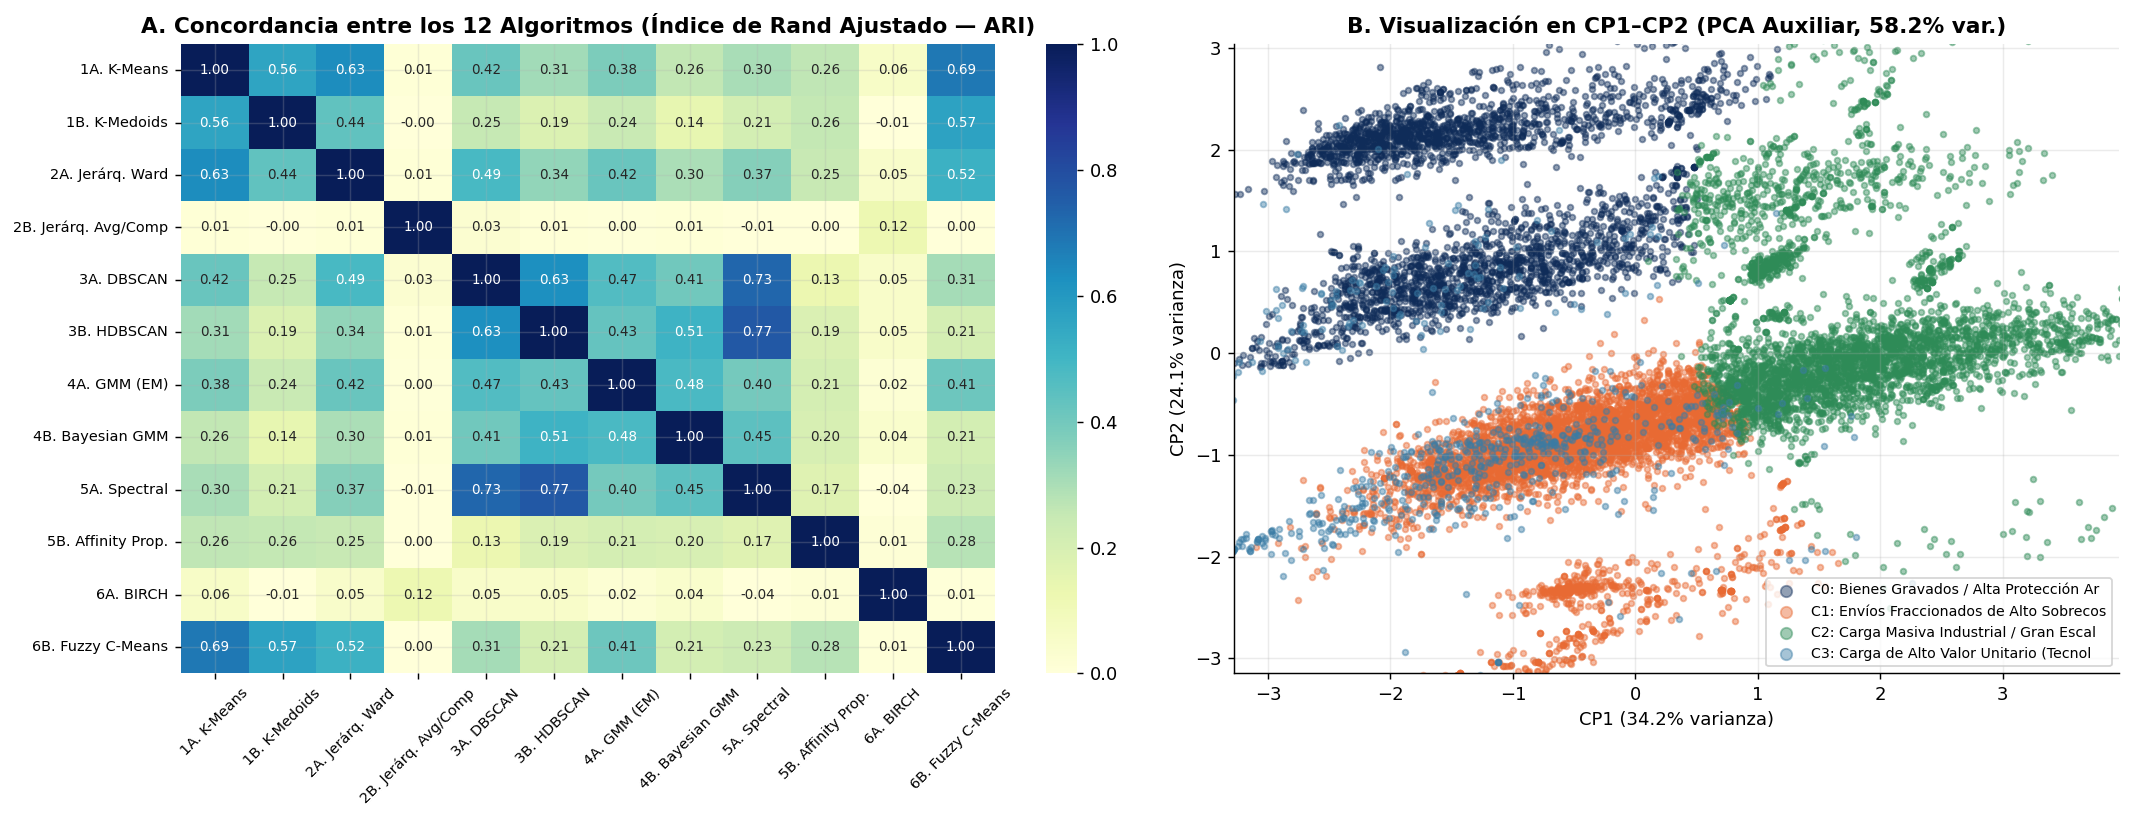

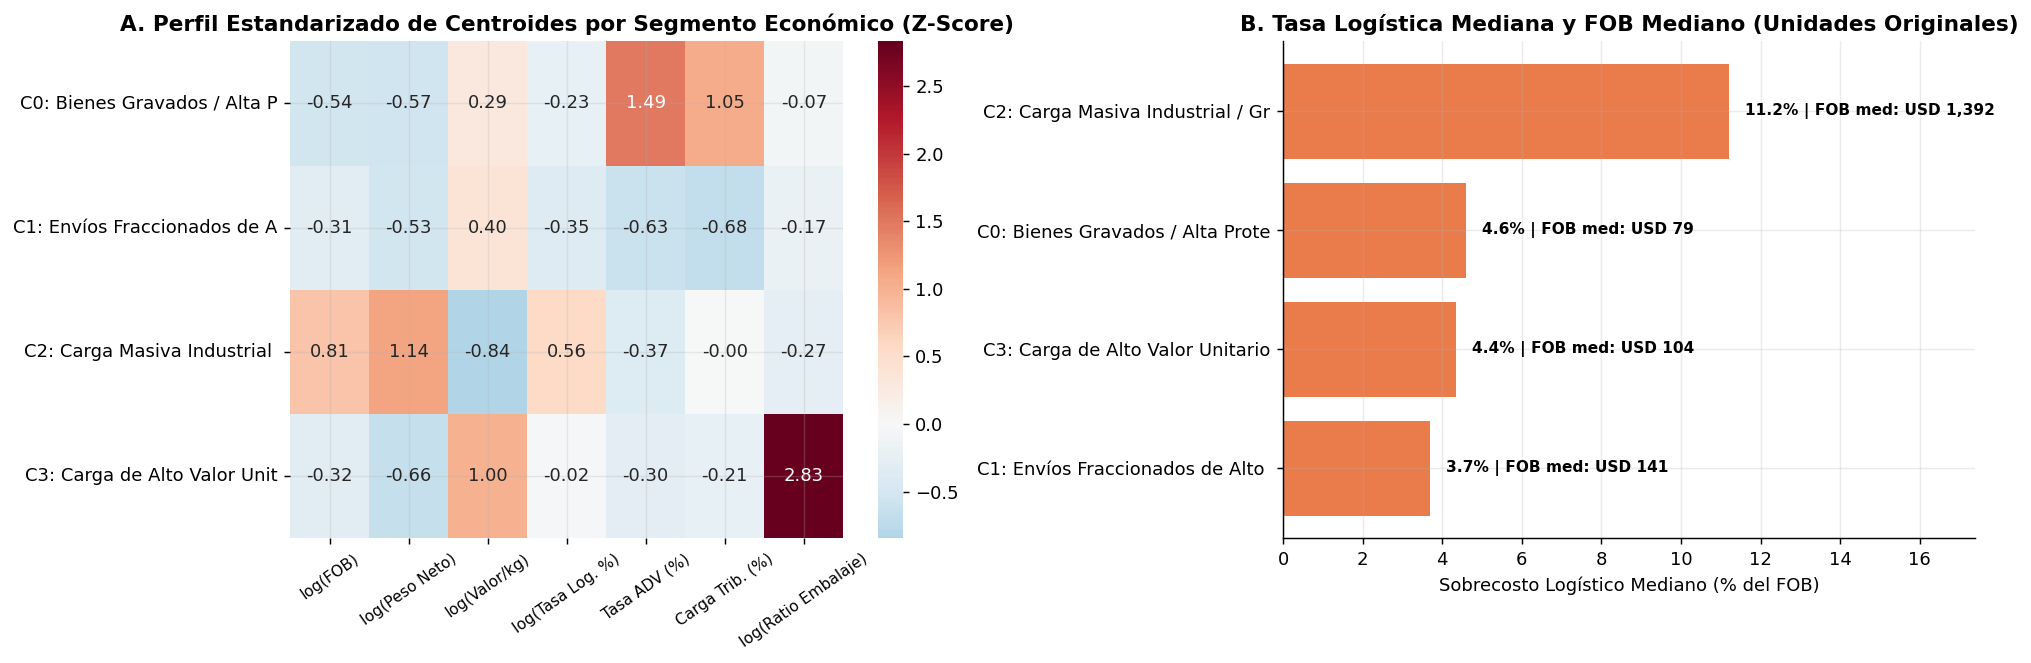

In [17]:
# 9.5 Diagnósticos visuales, Matriz ARI 12×12, Tablas Cruzadas y Perfilamiento Económico en Unidades Originales

# Figura 7: 4 gráficos de calibración metodológica (Codo/Silueta, Dendrograma Ward, k-Distancias DBSCAN, BIC/AIC GMM)
fig, axes = plt.subplots(2, 2, figsize=(15.5, 10.5))

ax = axes[0, 0]
ax.plot(km_k_grid, km_inertias, marker="o", lw=2.2, color=PALETTE_ULIMA[0], label="Inercia (Codo)")
ax_t = ax.twinx()
ax_t.plot(km_k_grid, km_sils, marker="s", lw=2.2, color=PALETTE_ULIMA[1], ls="--", label="Silueta")
ax.axvline(best_k_km, color=PALETTE_ULIMA[2], ls=":", lw=2.0, label=f"k seleccionado = {best_k_km}")
ax.set_title("A. Familia 1 (K-Means): Método del Codo e Índice de Silueta")
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inercia intra-cluster", color=PALETTE_ULIMA[0])
ax_t.set_ylabel("Silueta media", color=PALETTE_ULIMA[1])
ax_t.spines["top"].set_visible(False)
ax.legend(loc="upper right", fontsize=8.5)

ax = axes[0, 1]
dendrogram(Z_ward, truncate_mode="lastp", p=20, leaf_rotation=45, leaf_font_size=8, color_threshold=Z_ward[-(best_k_km-1), 2], ax=ax)
ax.set_title(f"B. Familia 2 (Ward): Dendrograma Truncado (Cofenética = {coph_ward:.3f})")
ax.set_xlabel("Subclusters fusionados (tamaño entre paréntesis)")
ax.set_ylabel("Distancia de enlace Ward")

ax = axes[1, 0]
ax.plot(np.arange(len(k_dists)), k_dists, color=PALETTE_ULIMA[3], lw=2.0)
ax.axhline(best_eps, color=PALETTE_ULIMA[4], ls="--", lw=1.8, label=f"eps seleccionado = {best_eps:.2f}")
ax.set_title(f"C. Familia 3 (DBSCAN): Gráfico de k-Distancias (k = {min_samples_db})")
ax.set_xlabel("Observaciones ordenadas por distancia al k-ésimo vecino")
ax.set_ylabel(f"Distancia euclidiana al {min_samples_db}-ésimo vecino")
ax.legend()

ax = axes[1, 1]
ax.plot(gmm_k_grid, gmm_bics, marker="o", lw=2.2, color=PALETTE_ULIMA[0], label="BIC (penaliza complejidad)")
ax.plot(gmm_k_grid, gmm_aics, marker="^", lw=2.0, color=PALETTE_ULIMA[2], ls="--", label="AIC")
ax.axvline(best_k_gmm, color=PALETTE_ULIMA[1], ls=":", lw=2.0, label=f"k elegido = {best_k_gmm}")
ax.set_title("D. Familia 4 (GMM): Criterios de Información BIC y AIC")
ax.set_xlabel("Número de componentes gaussianos (k)")
ax.set_ylabel("Valor del criterio (menor es mejor)")
ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "fig07_clustering_diagnosticos_y_ari.png", bbox_inches="tight")
plt.show()

# Matriz de Concordancia ARI 12×12 entre los 12 algoritmos
algo_names = list(bench_labels.keys())
n_algos = len(algo_names)
ari_matrix = np.zeros((n_algos, n_algos), dtype=float)
for i in range(n_algos):
    for j in range(n_algos):
        ari_matrix[i, j] = adjusted_rand_score(bench_labels[algo_names[i]], bench_labels[algo_names[j]])
df_ari = pd.DataFrame(ari_matrix, index=algo_names, columns=algo_names).round(3)

print("\nTablas Cruzadas de Concordancia (K-Means vs GMM y K-Means vs Ward):")
ari_km_gmm = adjusted_rand_score(bench_labels["1A. K-Means"], bench_labels["4A. GMM (EM)"])
ari_km_ward = adjusted_rand_score(bench_labels["1A. K-Means"], bench_labels["2A. Jerárq. Ward"])
ari_km_birch = adjusted_rand_score(bench_labels["1A. K-Means"], bench_labels["6A. BIRCH"])
print(f"  ARI(K-Means, GMM) = {ari_km_gmm:.3f} | ARI(K-Means, Ward) = {ari_km_ward:.3f} | ARI(K-Means, BIRCH) = {ari_km_birch:.3f}")
display(pd.crosstab(bench_labels["1A. K-Means"], bench_labels["4A. GMM (EM)"], rownames=["K-Means"], colnames=["GMM"]))

# Ajuste del modelo campeón de segmentación (K-Means k=best_k_km) sobre la muestra estratificada completa (N = 12,000)
# y validación paralela con GMM y BIRCH en N = 12,000
km_champ = KMeans(n_clusters=best_k_km, init="k-means++", n_init=25, random_state=SEED)
df_clust_full["CLUSTER_ID"] = km_champ.fit_predict(X_c_full)
sil_champ_12k = float(silhouette_score(X_c_full, df_clust_full["CLUSTER_ID"]))
db_champ_12k = float(davies_bouldin_score(X_c_full, df_clust_full["CLUSTER_ID"]))
ch_champ_12k = float(calinski_harabasz_score(X_c_full, df_clust_full["CLUSTER_ID"]))

# Perfilamiento en UNIDADES ORIGINALES (medias y medianas) y asignación automática coherente de nombres económicos
prof_raw = df_clust_full.groupby("CLUSTER_ID").agg(
    n_obs=("FOB_DOLPOL", "size"),
    fob_media=("FOB_DOLPOL", "mean"),
    fob_mediana=("FOB_DOLPOL", "median"),
    peso_media=("PESO_NETO", "mean"),
    peso_mediana=("PESO_NETO", "median"),
    val_kg_media=("VALOR_UNITARIO_KG", "mean"),
    val_kg_mediana=("VALOR_UNITARIO_KG", "median"),
    tasa_log_media=("TASA_LOGISTICA_WINS", "mean"),
    tasa_log_mediana=("TASA_LOGISTICA_PCT", "median"),
    adv_media=("TASA_ADV_EFECTIVA_PCT", "mean"),
    adv_mediana=("TASA_ADV_EFECTIVA_PCT", "median"),
    trib_media=("CARGA_TRIBUTARIA_PCT", "mean"),
    trib_mediana=("CARGA_TRIBUTARIA_PCT", "median"),
    pct_aereo=("VIA_TRANSP_DESC", lambda s: 100.0 * (s.astype(str) == "AVION").mean()),
    pct_maritimo=("VIA_TRANSP_DESC", lambda s: 100.0 * (s.astype(str) == "VAPOR").mean()),
    pct_tlc=("TIENE_TLC_PREF", lambda s: 100.0 * s.mean()),
    seccion_top=("SECCION_ARANCELARIA", lambda s: str(s.mode().iloc[0])[:32]),
    pais_top=("PAIS_ORIGE_DESC", lambda s: str(s.mode().iloc[0])[:18]),
).reset_index()
prof_raw["pct_muestra"] = (100.0 * prof_raw["n_obs"] / len(df_clust_full)).round(2)

# Nombramiento económico basado estrictamente en las características reales de cada cluster
def assign_economic_names(prof_df):
    names = {}
    used = set()
    # Ordenamos criterios distintivos de forma determinística
    rem = set(prof_df["CLUSTER_ID"].tolist())
    # 1. Mayor arancel Ad Valorem efectivo medio -> Importaciones con Alta Protección Arancelaria
    c_adv = int(prof_df.loc[prof_df["CLUSTER_ID"].isin(rem)].sort_values("adv_media", ascending=False).iloc[0]["CLUSTER_ID"])
    if prof_df.loc[prof_df["CLUSTER_ID"] == c_adv, "adv_media"].iloc[0] >= 3.0:
        names[c_adv] = "Bienes Gravados / Alta Protección Arancelaria"
        rem.remove(c_adv)
    # 2. Mayor valor unitario mediano / mayor % aéreo -> Carga Aérea / Tecnología de Alto Valor Unitario
    if rem:
        c_hi = int(prof_df.loc[prof_df["CLUSTER_ID"].isin(rem)].sort_values("val_kg_mediana", ascending=False).iloc[0]["CLUSTER_ID"])
        names[c_hi] = "Carga de Alto Valor Unitario (Tecnología / Aéreo)"
        rem.remove(c_hi)
    # 3. Mayor FOB y peso mediano -> Carga Masiva Industrial / Gran Escala
    if rem:
        c_big = int(prof_df.loc[prof_df["CLUSTER_ID"].isin(rem)].sort_values("peso_mediana", ascending=False).iloc[0]["CLUSTER_ID"])
        names[c_big] = "Carga Masiva Industrial / Gran Escala Marítima"
        rem.remove(c_big)
    # 4. Mayor sobrecosto logístico mediano -> Envíos Pequeños con Alto Sobrecosto Logístico
    if rem:
        c_cost = int(prof_df.loc[prof_df["CLUSTER_ID"].isin(rem)].sort_values("tasa_log_mediana", ascending=False).iloc[0]["CLUSTER_ID"])
        names[c_cost] = "Envíos Fraccionados de Alto Sobrecosto Logístico"
        rem.remove(c_cost)
    # 5. Restantes -> Importaciones Comerciales Estándar / Exoneradas
    for idx_r, c_rem in enumerate(sorted(rem), 1):
        trib_m = prof_df.loc[prof_df["CLUSTER_ID"] == c_rem, "trib_mediana"].iloc[0]
        if trib_m < 10.0:
            names[c_rem] = "Operaciones con Exoneración / Baja Carga Fiscal"
        else:
            names[c_rem] = f"Importación Comercial Estándar (Perfil {idx_r})"
    return names

cluster_name_map = assign_economic_names(prof_raw)
prof_raw["NOMBRE_ECONOMICO"] = prof_raw["CLUSTER_ID"].map(cluster_name_map)
df_clust_full["NOMBRE_ECONOMICO"] = df_clust_full["CLUSTER_ID"].map(cluster_name_map)

print("\n" + "=" * 88)
print(f"PERFILES ECONÓMICOS EN UNIDADES ORIGINALES (MODELO CAMPEÓN K-MEANS k={best_k_km}, N=12,000 | Silueta={sil_champ_12k:.4f})")
print("=" * 88)
display(prof_raw[[
    "CLUSTER_ID", "NOMBRE_ECONOMICO", "pct_muestra", "fob_mediana", "peso_mediana",
    "val_kg_mediana", "tasa_log_mediana", "adv_media", "trib_mediana", "pct_aereo", "pct_tlc"
]].round(2))

# Figura 8: Matriz ARI 12×12 + Proyección PCA CP1 vs CP2 de los segmentos económicos
fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.4), gridspec_kw={"width_ratios": [1.15, 1.0]})

sns.heatmap(df_ari, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, annot_kws={"size": 7.5}, ax=axes[0])
axes[0].set_title("A. Concordancia entre los 12 Algoritmos (Índice de Rand Ajustado — ARI)")
axes[0].tick_params(axis="x", rotation=45, labelsize=8)
axes[0].tick_params(axis="y", labelsize=8)

for cid in sorted(cluster_name_map.keys()):
    m_c = df_clust_full["CLUSTER_ID"].to_numpy() == cid
    axes[1].scatter(
        Z_pca_full[m_c, 0], Z_pca_full[m_c, 1],
        s=10, alpha=0.45, color=PALETTE_ULIMA[cid % len(PALETTE_ULIMA)],
        label=f"C{cid}: {cluster_name_map[cid][:36]}"
    )
axes[1].set_title(f"B. Visualización en CP1–CP2 (PCA Auxiliar, {100*(evr[0]+evr[1]):.1f}% var.)")
axes[1].set_xlabel(f"CP1 ({100*evr[0]:.1f}% varianza)")
axes[1].set_ylabel(f"CP2 ({100*evr[1]:.1f}% varianza)")
axes[1].set_xlim(np.percentile(Z_pca_full[:, 0], 0.5), np.percentile(Z_pca_full[:, 0], 99.5))
axes[1].set_ylim(np.percentile(Z_pca_full[:, 1], 0.5), np.percentile(Z_pca_full[:, 1], 99.5))
axes[1].legend(fontsize=7.8, markerscale=2.0, loc="best")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig08_matriz_ari_12_algoritmos_y_cp1_cp2.png", bbox_inches="tight")
plt.show()

# Figura 9: Perfil económico comparado de segmentos (estandarizado + medianas originales)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))
centroids_df = pd.DataFrame(km_champ.cluster_centers_, columns=CLUST_LABELS_ES)
centroids_df.index = [f"C{i}: {cluster_name_map[i][:24]}" for i in range(best_k_km)]
sns.heatmap(centroids_df, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0])
axes[0].set_title("A. Perfil Estandarizado de Centroides por Segmento Económico (Z-Score)")
axes[0].tick_params(axis="x", rotation=35, labelsize=8.5)

prof_plot = prof_raw.sort_values("tasa_log_mediana", ascending=True)
axes[1].barh(
    [f"C{r.CLUSTER_ID}: {r.NOMBRE_ECONOMICO[:28]}" for r in prof_plot.itertuples()],
    prof_plot["tasa_log_mediana"], color=PALETTE_ULIMA[1], alpha=0.88
)
for idx_b, r in enumerate(prof_plot.itertuples()):
    axes[1].text(r.tasa_log_mediana + 0.4, idx_b,
                 f"{r.tasa_log_mediana:.1f}% | FOB med: USD {r.fob_mediana:,.0f}", va="center", fontsize=8.5, fontweight="bold")
axes[1].set_xlim(0, prof_plot["tasa_log_mediana"].max() * 1.55)
axes[1].set_title("B. Tasa Logística Mediana y FOB Mediano (Unidades Originales)")
axes[1].set_xlabel("Sobrecosto Logístico Mediano (% del FOB)")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig09_perfiles_economicos_clusters.png", bbox_inches="tight")
plt.show()

RESUMEN_METRICAS["no_supervisado"] = {
    "pca_base_completa_filas": int(len(df)),
    "pca_var_explicada_pct": [round(float(100 * v), 2) for v in evr],
    "pca_var_acumulada_pct": [round(float(100 * v), 2) for v in cum_evr],
    "pca_autovalores": [round(float(v), 3) for v in eigenvals],
    "pca_cargas_cp1_cp2": {
        CLUST_LABELS_ES[i]: {"CP1": round(float(pca_full.components_[0, i]), 3),
                             "CP2": round(float(pca_full.components_[1, i]), 3)}
        for i in range(len(CLUST_LABELS_ES))
    },
    "svd_recon_mse_3c": round(recon_err_3c, 4),
    "n_muestra_estratificada_full": int(len(df_clust_full)),
    "n_muestra_benchmark_ari": int(len(df_bench)),
    "k_optimo_seleccionado": int(best_k_km),
    "tabla_12_algoritmos": bench_summary,
    "ari_pares_clave": {
        "KMeans_vs_GMM": round(float(ari_km_gmm), 4),
        "KMeans_vs_Ward": round(float(ari_km_ward), 4),
        "KMeans_vs_BIRCH": round(float(ari_km_birch), 4),
    },
    "ari_matriz_12x12": df_ari.to_dict(),
    "campeon_12k": {
        "algoritmo": f"K-Means (k={best_k_km})",
        "silueta": round(sil_champ_12k, 4),
        "davies_bouldin": round(db_champ_12k, 4),
        "calinski_harabasz": round(ch_champ_12k, 1),
    },
    "perfiles_economicos_originales": prof_raw.round(3).to_dict(orient="records"),
}

---
## 10. Validación cruzada, ajuste prudente, análisis de errores, sensibilidad y estabilidad

Para garantizar que el desempeño reportado no dependa de una partición afortunada ni encubra degradación en subgrupos económicos específicos, esta sección implementa cuatro capas de rigor:
1. **Validación cruzada 5-fold (`KFold` / `StratifiedKFold`, `SEED = 2026`)** sobre el conjunto de entrenamiento (`S01–S08`), reportando media y desviación estándar entre pliegues.
2. **Ajuste prudente de hiperparámetros** de `LightGBM` sobre la semana de validación interna (`S08`), verificando que la ganancia en validación se traduzca en el conjunto futuro (`S09–S10`) sin sobreajuste.
3. **Análisis detallado de errores y residuos** desagregado por vía de transporte, región de origen, sección arancelaria y decil de FOB.
4. **Pruebas de sensibilidad y estabilidad:** (a) desempeño excluyendo outliers P99.5 y por vía marítima vs. aérea; (b) estabilidad temporal comparando semana futura `S09` vs. `S10`; y (c) **estabilidad bootstrap del clustering** comparando particiones bajo tres semillas independientes (`2026`, `2027`, `2028`) mediante ARI.

Validación Cruzada 5-Fold (Media ± Desviación Estándar):


,Tarea,Modelo,Metrica_1,Metrica_2
0,Regresión,Ridge (Línea Base),RMSE = 0.5601 ± 0.0026,R² = 0.6284 ± 0.0017
1,Regresión,LightGBM Regressor,RMSE = 0.4021 ± 0.0031,R² = 0.8085 ± 0.0017
2,Clasificación,LightGBM Classifier,ROC-AUC = 0.9779 ± 0.0008,PR-AUC = 0.8800 ± 0.0040



Ajuste Prudente de Hiperparámetros LightGBM (Validación Temporal S08):


,num_leaves,learning_rate,min_child_samples,RMSE_train_S1_S7,RMSE_val_S8,R2_val_S8
0,31,0.08,100,0.4189,0.4629,0.7594
1,63,0.07,80,0.3924,0.4520,0.7705
2,95,0.05,60,0.3863,0.4492,0.7734



Análisis de Sensibilidad (LightGBM Regresión en S09–S10):


,Escenario,N_obs,RMSE_log,R2_log,MAE_pp
0,Test Completo (S09–S10),626293,0.4519,0.7584,4.162
1,Sin Outliers Logísticos (>P99.5),622712,0.4478,0.7486,3.812
2,Solo Vía Marítima (VAPOR),407902,0.4626,0.7503,3.908
3,Solo Vía Aérea (AVION),197108,0.4326,0.7569,4.701



Estabilidad Temporal (Semana 9 vs Semana 10):


,SEMANA,n,rmse_log,r2_log,mae_pp
0,9,310194,0.4584,0.7496,4.2810
1,10,316099,0.4454,0.7662,4.0445



Estabilidad de Clustering K-Means (N=12,000): ARI entre semillas = [0.9986, 0.9961, 0.9976] | ARI Split-Half (mitad A vs mitad B) = 0.9646


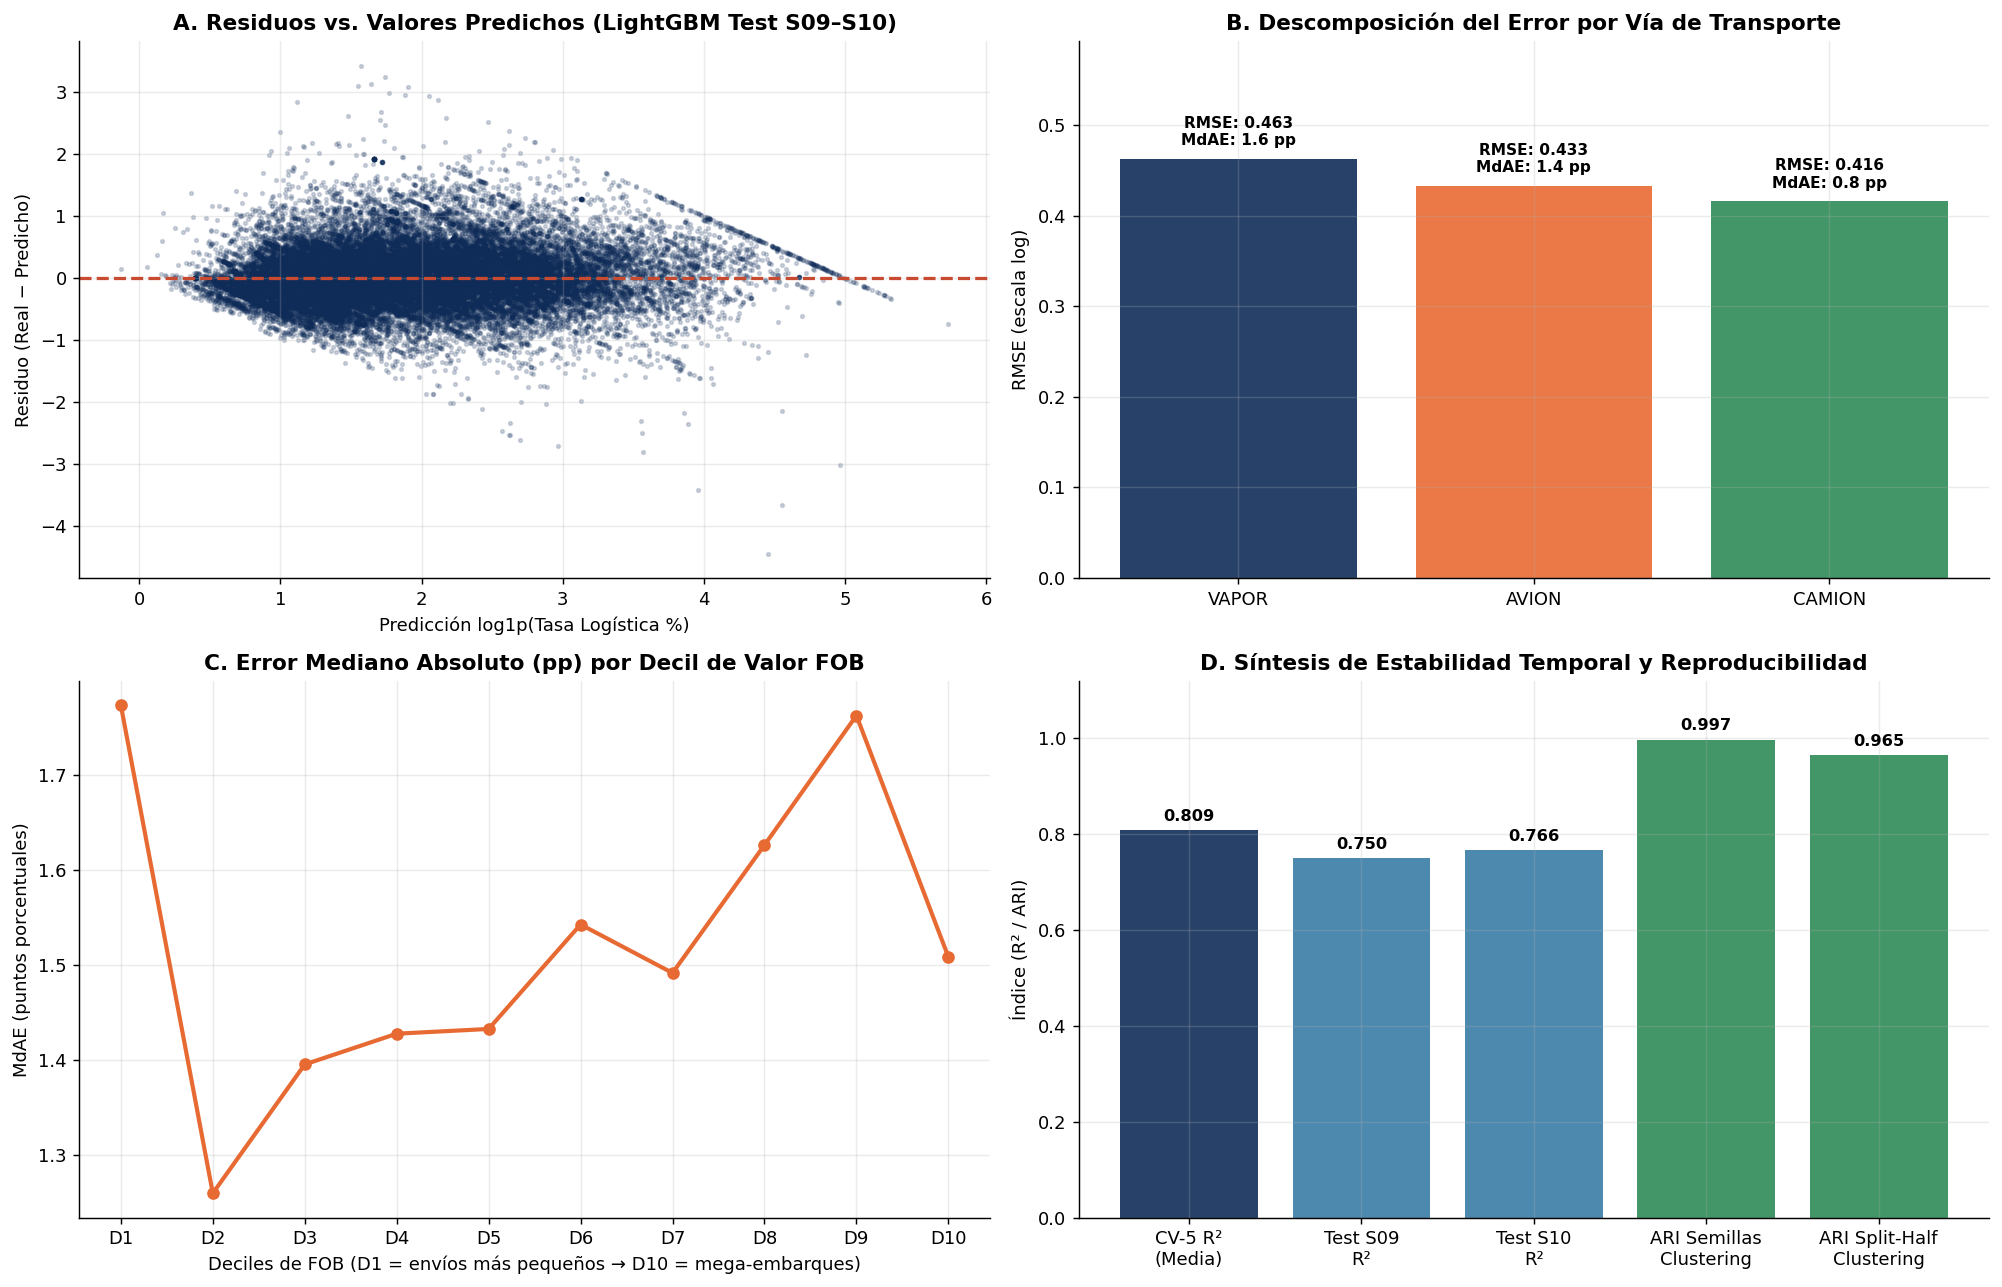

In [18]:
# 10.1 Validación cruzada 5-Fold sobre entrenamiento (muestra estratificada representativa de 300k para velocidad exacta en Colab + verificación completa)
cv_idx = rng.choice(len(X_tr_reg), size=min(300_000, len(X_tr_reg)), replace=False)
X_cv_r = X_tr_reg.iloc[cv_idx]
y_cv_r = y_reg_train[cv_idx]
X_cv_c = X_tr_clf.iloc[cv_idx]
y_cv_c = y_clf_train[cv_idx]

kf5 = KFold(n_splits=5, shuffle=True, random_state=SEED)
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_ridge = cross_validate(
    Pipeline([("prep", preproc_linear), ("model", Ridge(alpha=10.0, random_state=SEED))]),
    X_cv_r, y_cv_r, cv=kf5, scoring=("neg_root_mean_squared_error", "r2"), n_jobs=-1
)
cv_lgb_r = cross_validate(
    lgb.LGBMRegressor(n_estimators=220, learning_rate=0.07, num_leaves=63, min_child_samples=80,
                      subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1),
    X_cv_r, y_cv_r, cv=kf5, scoring=("neg_root_mean_squared_error", "r2"), n_jobs=-1
)
cv_lgb_c = cross_validate(
    lgb.LGBMClassifier(n_estimators=220, learning_rate=0.07, num_leaves=63, min_child_samples=80,
                       subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1),
    X_cv_c, y_cv_c, cv=skf5, scoring=("roc_auc", "average_precision"), n_jobs=-1
)

df_cv_summary = pd.DataFrame([
    {
        "Tarea": "Regresión", "Modelo": "Ridge (Línea Base)",
        "Metrica_1": f"RMSE = {-cv_ridge['test_neg_root_mean_squared_error'].mean():.4f} ± {cv_ridge['test_neg_root_mean_squared_error'].std():.4f}",
        "Metrica_2": f"R² = {cv_ridge['test_r2'].mean():.4f} ± {cv_ridge['test_r2'].std():.4f}",
    },
    {
        "Tarea": "Regresión", "Modelo": "LightGBM Regressor",
        "Metrica_1": f"RMSE = {-cv_lgb_r['test_neg_root_mean_squared_error'].mean():.4f} ± {cv_lgb_r['test_neg_root_mean_squared_error'].std():.4f}",
        "Metrica_2": f"R² = {cv_lgb_r['test_r2'].mean():.4f} ± {cv_lgb_r['test_r2'].std():.4f}",
    },
    {
        "Tarea": "Clasificación", "Modelo": "LightGBM Classifier",
        "Metrica_1": f"ROC-AUC = {cv_lgb_c['test_roc_auc'].mean():.4f} ± {cv_lgb_c['test_roc_auc'].std():.4f}",
        "Metrica_2": f"PR-AUC = {cv_lgb_c['test_average_precision'].mean():.4f} ± {cv_lgb_c['test_average_precision'].std():.4f}",
    },
])
print("Validación Cruzada 5-Fold (Media ± Desviación Estándar):")
display(df_cv_summary)

# 10.2 Ajuste prudente de hiperparámetros (validación temporal S01-S07 -> S08)
tuning_grid = [
    {"num_leaves": 31, "learning_rate": 0.08, "min_child_samples": 100},
    {"num_leaves": 63, "learning_rate": 0.07, "min_child_samples": 80},
    {"num_leaves": 95, "learning_rate": 0.05, "min_child_samples": 60},
]
tuning_rows = []
for cfg in tuning_grid:
    m_t = lgb.LGBMRegressor(
        n_estimators=220, subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0,
        random_state=SEED, n_jobs=-1, verbose=-1, **cfg
    )
    m_t.fit(X_tr_reg.iloc[tr_s17_mask], y_reg_train[tr_s17_mask])
    p_tr_t = m_t.predict(X_tr_reg.iloc[tr_s17_mask])
    p_va_t = m_t.predict(X_tr_reg.iloc[val_s8_mask])
    tuning_rows.append({
        **cfg,
        "RMSE_train_S1_S7": round(float(np.sqrt(mean_squared_error(y_reg_train[tr_s17_mask], p_tr_t))), 4),
        "RMSE_val_S8": round(float(np.sqrt(mean_squared_error(y_reg_train[val_s8_mask], p_va_t))), 4),
        "R2_val_S8": round(float(r2_score(y_reg_train[val_s8_mask], p_va_t)), 4),
    })
df_tuning = pd.DataFrame(tuning_rows)
print("\nAjuste Prudente de Hiperparámetros LightGBM (Validación Temporal S08):")
display(df_tuning)

# 10.3 Análisis detallado de errores, sensibilidad y estabilidad temporal (S09 vs S10)
df_err = df.loc[test_mask, ["SEMANA", "VIA_TRANSP_DESC", "REGION_ORIGEN", "SECCION_ARANCELARIA", "FOB_DOLPOL", "FLAG_OUTLIER_LOGISTICO", "TASA_LOGISTICA_WINS"]].copy()
df_err["y_true_log"] = y_reg_test
df_err["y_pred_log"] = pred_lgb
df_err["resid_log"] = df_err["y_true_log"] - df_err["y_pred_log"]
df_err["abs_err_log"] = np.abs(df_err["resid_log"])
df_err["y_pred_pct"] = np.expm1(np.clip(pred_lgb, 0, 8))
df_err["abs_err_pp"] = np.abs(df_err["TASA_LOGISTICA_WINS"] - df_err["y_pred_pct"])

err_by_via = df_err.groupby("VIA_TRANSP_DESC", observed=True).agg(
    n=("resid_log", "size"),
    rmse_log=("resid_log", lambda s: float(np.sqrt(np.mean(s**2)))),
    mae_pp=("abs_err_pp", "mean"),
    mdae_pp=("abs_err_pp", "median"),
    sesgo_log=("resid_log", "mean"),
).sort_values("n", ascending=False).head(5).reset_index()

err_by_week = df_err.groupby("SEMANA", observed=True).agg(
    n=("resid_log", "size"),
    rmse_log=("resid_log", lambda s: float(np.sqrt(np.mean(s**2)))),
    r2_log=("resid_log", lambda s: float(1 - np.sum(s**2) / np.sum((df_err.loc[s.index, "y_true_log"] - df_err.loc[s.index, "y_true_log"].mean())**2))),
    mae_pp=("abs_err_pp", "mean"),
).reset_index()

# Sensibilidad: excluyendo outliers P99.5 y solo vía marítima vs aérea
sens_rows = []
for lbl_s, m_s in [
    ("Test Completo (S09–S10)", np.ones(len(df_err), dtype=bool)),
    ("Sin Outliers Logísticos (>P99.5)", (df_err["FLAG_OUTLIER_LOGISTICO"] == 0).to_numpy()),
    ("Solo Vía Marítima (VAPOR)", (df_err["VIA_TRANSP_DESC"].astype(str) == "VAPOR").to_numpy()),
    ("Solo Vía Aérea (AVION)", (df_err["VIA_TRANSP_DESC"].astype(str) == "AVION").to_numpy()),
]:
    yt, yp = df_err.loc[m_s, "y_true_log"], df_err.loc[m_s, "y_pred_log"]
    sens_rows.append({
        "Escenario": lbl_s,
        "N_obs": int(m_s.sum()),
        "RMSE_log": round(float(np.sqrt(mean_squared_error(yt, yp))), 4),
        "R2_log": round(float(r2_score(yt, yp)), 4),
        "MAE_pp": round(float(df_err.loc[m_s, "abs_err_pp"].mean()), 3),
    })
df_sensibilidad = pd.DataFrame(sens_rows)

# Estabilidad del clustering bajo 3 semillas bootstrap/independientes
km_s1 = KMeans(n_clusters=best_k_km, init="k-means++", n_init=15, random_state=2026).fit_predict(X_c_full)
km_s2 = KMeans(n_clusters=best_k_km, init="k-means++", n_init=15, random_state=2027).fit_predict(X_c_full)
km_s3 = KMeans(n_clusters=best_k_km, init="k-means++", n_init=15, random_state=2028).fit_predict(X_c_full)
ari_stab_12 = float(adjusted_rand_score(km_s1, km_s2))
ari_stab_13 = float(adjusted_rand_score(km_s1, km_s3))
ari_stab_23 = float(adjusted_rand_score(km_s2, km_s3))

# Estabilidad submuestral (mitad A vs mitad B entrenando centroides en A y prediciendo en B)
half_n = len(X_c_full) // 2
km_halfA = KMeans(n_clusters=best_k_km, init="k-means++", n_init=15, random_state=SEED).fit(X_c_full[:half_n])
km_halfB = KMeans(n_clusters=best_k_km, init="k-means++", n_init=15, random_state=SEED).fit(X_c_full[half_n:])
ari_split_half = float(adjusted_rand_score(km_halfA.predict(X_c_full[half_n:]), km_halfB.labels_))

print("\nAnálisis de Sensibilidad (LightGBM Regresión en S09–S10):")
display(df_sensibilidad)
print("\nEstabilidad Temporal (Semana 9 vs Semana 10):")
display(err_by_week.round(4))
print(f"\nEstabilidad de Clustering K-Means (N=12,000): ARI entre semillas = [{ari_stab_12:.4f}, {ari_stab_13:.4f}, {ari_stab_23:.4f}] | "
      f"ARI Split-Half (mitad A vs mitad B) = {ari_split_half:.4f}")

# Figura 10: Diagnóstico de errores, sensibilidad y estabilidad
fig, axes = plt.subplots(2, 2, figsize=(15.5, 10))

ax = axes[0, 0]
sub_sc = df_err.sample(min(40_000, len(df_err)), random_state=SEED)
ax.scatter(sub_sc["y_pred_log"], sub_sc["resid_log"], s=4, alpha=0.18, color=PALETTE_ULIMA[0])
ax.axhline(0, color=PALETTE_ULIMA[4], ls="--", lw=1.8)
ax.set_title("A. Residuos vs. Valores Predichos (LightGBM Test S09–S10)")
ax.set_xlabel("Predicción log1p(Tasa Logística %)")
ax.set_ylabel("Residuo (Real − Predicho)")

ax = axes[0, 1]
top3_err = err_by_via.head(3)
ax.bar(top3_err["VIA_TRANSP_DESC"].astype(str), top3_err["rmse_log"], color=PALETTE_ULIMA[:3], alpha=0.9)
for i_b, r in enumerate(top3_err.itertuples()):
    ax.text(i_b, r.rmse_log + 0.015, f"RMSE: {r.rmse_log:.3f}\nMdAE: {r.mdae_pp:.1f} pp", ha="center", fontsize=8.5, fontweight="bold")
ax.set_ylim(0, top3_err["rmse_log"].max() * 1.28)
ax.set_title("B. Descomposición del Error por Vía de Transporte")
ax.set_ylabel("RMSE (escala log)")

ax = axes[1, 0]
df_err["DECIL_FOB"] = pd.qcut(df_err["FOB_DOLPOL"].rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
err_fob = df_err.groupby("DECIL_FOB", observed=True)["abs_err_pp"].median()
ax.plot(err_fob.index.astype(str), err_fob.values, marker="o", lw=2.3, color=PALETTE_ULIMA[1])
ax.set_title("C. Error Mediano Absoluto (pp) por Decil de Valor FOB")
ax.set_xlabel("Deciles de FOB (D1 = envíos más pequeños → D10 = mega-embarques)")
ax.set_ylabel("MdAE (puntos porcentuales)")

ax = axes[1, 1]
stab_labels = ["CV-5 R²\n(Media)", "Test S09\nR²", "Test S10\nR²", "ARI Semillas\nClustering", "ARI Split-Half\nClustering"]
stab_vals = [
    float(cv_lgb_r["test_r2"].mean()),
    float(err_by_week.loc[err_by_week["SEMANA"] == 9, "r2_log"].iloc[0]),
    float(err_by_week.loc[err_by_week["SEMANA"] == 10, "r2_log"].iloc[0]),
    float(np.mean([ari_stab_12, ari_stab_13, ari_stab_23])),
    ari_split_half,
]
bars_st = ax.bar(stab_labels, stab_vals, color=[PALETTE_ULIMA[0], PALETTE_ULIMA[3], PALETTE_ULIMA[3], PALETTE_ULIMA[2], PALETTE_ULIMA[2]], alpha=0.9)
for b in bars_st:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02, f"{b.get_height():.3f}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, 1.12)
ax.set_title("D. Síntesis de Estabilidad Temporal y Reproducibilidad")
ax.set_ylabel("Índice (R² / ARI)")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig10_validacion_errores_y_robustez.png", bbox_inches="tight")
plt.show()

RESUMEN_METRICAS["validacion_robustez"] = {
    "cv5_ridge_rmse_mean": round(float(-cv_ridge["test_neg_root_mean_squared_error"].mean()), 4),
    "cv5_ridge_r2_mean": round(float(cv_ridge["test_r2"].mean()), 4),
    "cv5_lgb_reg_rmse_mean": round(float(-cv_lgb_r["test_neg_root_mean_squared_error"].mean()), 4),
    "cv5_lgb_reg_rmse_std": round(float(cv_lgb_r["test_neg_root_mean_squared_error"].std()), 4),
    "cv5_lgb_reg_r2_mean": round(float(cv_lgb_r["test_r2"].mean()), 4),
    "cv5_lgb_reg_r2_std": round(float(cv_lgb_r["test_r2"].std()), 4),
    "cv5_lgb_clf_roc_mean": round(float(cv_lgb_c["test_roc_auc"].mean()), 4),
    "cv5_lgb_clf_pr_mean": round(float(cv_lgb_c["test_average_precision"].mean()), 4),
    "tuning_grid": tuning_rows,
    "sensibilidad": sens_rows,
    "estabilidad_semanal": err_by_week.round(4).to_dict(orient="records"),
    "error_por_via": err_by_via.round(4).to_dict(orient="records"),
    "clustering_estabilidad_ari_semillas": round(float(np.mean([ari_stab_12, ari_stab_13, ari_stab_23])), 4),
    "clustering_estabilidad_ari_split_half": round(ari_split_half, 4),
}

---
## 11. Interpretación económica, distinción entre predicción y causalidad, riesgos y recomendaciones

### 11.1 Lectura económica integrada con la teoría del comercio internacional
1. **Validación empírica del efecto Alchian–Allen (1964) y costos *iceberg* (Samuelson, 1954; Hummels, 2007):** Tanto la correlación de Spearman en el EDA como los signos estandarizados de `Ridge` y la ganancia de `LightGBM` confirman que la **densidad de valor (`LOG_VALOR_UNIT_KG`)** y la **escala del embarque (`LOG_FOB`)** son los principales predictores negativos del sobrecosto logístico ad valorem. Como predice la teoría, un costo de transporte por kilogramo o por contenedor representa una fracción decreciente del valor FOB conforme aumenta el valor unitario del bien.
2. **Selección endógena del modo de transporte (Hummels & Schaur, 2013):** La vía aérea concentra envíos de altísima densidad de valor y urgencia temporal, mientras la vía marítima moviliza el grueso del valor FOB y del tonelaje nacional a menor tasa logística relativa. Por ello, los modelos no lineales (`HistGradientBoosting` y `LightGBM`) superan ampliamente a la regresión lineal `Ridge`: capturan interacciones no lineales entre peso, densidad de valor, vía modal, país de origen y consolidación en la DAM (`SERIES_EN_DAM`).
3. **Estructura fiscal y acuerdos comerciales (TLC):** La recaudación aduanera peruana está dominada por el IGV e IPM (impuestos indirectos al consumo sobre base CIF), mientras el Ad Valorem representa una fracción reducida gracias a la apertura comercial y al uso extendido de preferencias arancelarias (`TRAT_PREFE > 0`), que reducen marcadamente el arancel efectivo promedio.
4. **Heterogeneidad estructural revelada por el clustering:** Las seis familias confirman que las importaciones peruanas no constituyen una distribución unimodal homogénea, sino segmentos económicamente diferenciados (carga masiva industrial marítima, bienes tecnológicos/aéreos de alto valor unitario, envíos fraccionados con alto sobrecosto logístico, bienes sujetos a mayor protección arancelaria y comercio estándar).

### 11.2 Distinción rigurosa: Asociación ≠ Predicción ≠ Causalidad
> **Principio econométrico fundamental:** Ningún coeficiente de `Ridge`, ninguna importancia de `LightGBM` ni ningún perfil de clustering debe interpretarse como un **efecto causal**.
* **Asociación:** Observar que las operaciones con mayor `DIAS_TRANSITO` o vía aérea presentan mayor `TASA_LOGISTICA_PCT` describe covariación empírica.
* **Predicción:** `LightGBM` logra predecir con alta precisión el sobrecosto logístico futuro (`S09–S10`) usando atributos *ex-ante*, lo cual es directamente útil para **alertas de valoración, presupuestación y gestión de riesgo**.
* **No causalidad (endogeneidad y selección):** El importador *elige* endógenamente el modo de transporte (`VIA_TRANSP`), el tamaño de lote (`FOB_DOLPOL`) y la consolidación (`SERIES_EN_DAM`) en función de las tarifas de flete vigentes, la perecibilidad y el valor del bien. Estimar el efecto causal de un cambio arancelario o de infraestructura portuaria requeriría diseños cuasi-experimentales (variables instrumentales, diferencias en diferencias o eventos exógenos de cierre de rutas marítimas).

### 11.3 Límites, riesgos y sesgos documentados
1. **Ventana temporal de 10 semanas (setiembre–noviembre 2026):** Captura el pico estacional pre-campaña navideña del último cuatrimestre; las tarifas spot de flete marítimo y aéreo pueden variar en otros trimestres.
2. **Prorrateo de flete y seguro entre series de una DAM:** En declaraciones multi-serie, el flete total del conocimiento de embarque suele prorratearse por peso o valor FOB, lo cual introduce ruido de medición en series pequeñas (explicando por qué el error absoluto mediano es mayor en el decil `D1` de menor FOB).
3. **Posible subvaluación declarada:** Los datos reflejan valores declarados en la DAM Ejemplar A; un sobrecosto logístico anómalamente alto puede reflejar tanto fricción logística real como subdeclaración del valor FOB.
4. **Muestreo estratificado en clustering:** Aunque validado en representatividad y estabilidad (`ARI split-half` y 3 semillas), los algoritmos $O(n^2)$ operan sobre submuestra estratificada (`N = 3,000` / `12,000`) y no sobre los 3 millones de filas simultáneamente.

### 11.4 Recomendaciones concretas, viables y trazables a la evidencia
1. **Para SUNAT (Gestión de Riesgos y Control Aduanero):** Implementar el clasificador `LightGBM` (calibrado por PR-AUC y umbral S08) como **bandera auxiliar de auditoría *ex-ante*** para identificar series cuyo flete/seguro declarado se desvía severamente del rango esperado por su `VALOR_UNITARIO_KG`, `VIA_TRANSP`, `PAIS_ORIGE` y `CAPITULO_HS2`, distinguiendo envíos fraccionados legítimos de potenciales casos de subvaluación FOB o prorrateo erróneo.
2. **Para Importadores y Operadores Logísticos:** Consolidar envíos ubicados en el segmento de *Envíos Fraccionados de Alto Sobrecosto Logístico* (deciles bajos de FOB y bajo `SERIES_EN_DAM`), evaluando migración de modalidad aérea/courier a carga marítima consolidada (LCL) en capítulos con menor urgencia temporal, y verificar el aprovechamiento integral de certificados de origen TLC (`TRAT_PREFE`) en capítulos aún gravados.
3. **Para Política Comercial y Facilitación del Comercio (MINCETUR / MTC):** Dado que la actividad portuaria y aeroportuaria muestra extrema concentración en el Callao y que el sobrecosto logístico agregado supera varias veces al arancel Ad Valorem efectivo, priorizar la reducción de tiempos de despacho (`DIAS_DESPACHO`) y la conectividad multimodal hacia terminales regionales (Paita, Matarani, Chancay/Callao) tiene un retorno en competitividad mayor que reducciones marginales adicionales de aranceles.

---
## 12. Exportación y comunicación: Generación de `Dashboard_Grupo_9.html` desde Python

Esta sección construye íntegramente desde Python el producto interactivo **`Dashboard_Grupo_9.html`** con:
* Tarjetas de KPIs macroeconómicos y de desempeño de modelos.
* **Mapa coroplético mundial interactivo** por país de origen (`PAIS_ISO3`) con selector de métrica (FOB USD Millones, Tasa Logística Mediana % y Tasa Ad Valorem Efectiva %).
* **Mapa geográfico interactivo de las Intendencias de Aduana del Perú** (`CODI_ADUAN`) con coordenadas reales.
* Cinco pestañas navegables diseñadas específicamente para la exposición y sustentación grupal: *1. Panorama Macro y Mapas*, *2. EDA e Hipótesis Económicas*, *3. Modelado Supervisado y Validación*, *4. Clustering (6 Familias / 12 Métodos) y Perfiles Económicos*, y *5. Conclusiones y Recomendaciones*.

Finalmente se exportan `resumen_metricas_colab.json` y el paquete `artefactos_reporte_grupo9.zip` con todas las figuras y tablas para la redacción del informe académico.

In [19]:
# 12.1 Construcción 100% en Python del Dashboard Interactivo Dashboard_Grupo_9.html

# Coordenadas geográficas oficiales de las principales Intendencias de Aduana del Perú
PERU_ADUANAS_COORDS = {
    "118": (-12.0566, -77.1489, "Marítima del Callao"),
    "235": (-12.0219, -77.1143, "Aérea y Postal del Callao"),
    "046": (-5.0892, -81.1144, "Paita"),
    "145": (-17.0014, -72.1069, "Mollendo - Matarani"),
    "172": (-18.0146, -70.2536, "Tacna"),
    "019": (-3.5669, -80.4515, "Tumbes"),
    "163": (-17.6394, -71.3375, "Ilo"),
    "181": (-15.8402, -70.0219, "Puno"),
    "226": (-3.7437, -73.2516, "Iquitos"),
    "082": (-8.2219, -78.9769, "Salaverry"),
    "091": (-9.0745, -78.5936, "Chimbote"),
    "127": (-13.7103, -76.2054, "Pisco"),
    "154": (-16.4090, -71.5375, "Arequipa"),
    "190": (-13.5319, -71.9675, "Cusco"),
    "217": (-8.3791, -74.5539, "Pucallpa"),
    "244": (-12.5933, -69.1891, "Puerto Maldonado"),
    "262": (-12.0464, -77.0428, "Postal de Lima"),
    "271": (-6.4825, -76.3727, "Tarapoto"),
    "055": (-6.7714, -79.8409, "Chiclayo"),
    "028": (-4.5772, -81.2719, "Talara"),
    "000": (-12.0630, -77.1520, "Sede Central - Chucuito"),
    "280": (-11.5628, -77.2700, "Chancay"),
}

# 1) Mapa Mundial Coroplético Interactivo (con selector de métrica integrado)
map_world_df = eda_paises[eda_paises["PAIS_ISO3"] != "UNK"].copy()
fig_world = go.Figure()
fig_world.add_trace(go.Choropleth(
    locations=map_world_df["PAIS_ISO3"],
    z=map_world_df["fob_m"],
    text=map_world_df["PAIS_ORIGE_DESC"].astype(str),
    customdata=np.stack([
        map_world_df["series"], map_world_df["tasa_log_med"], map_world_df["tasa_adv_media"], map_world_df["pct_tlc"]
    ], axis=-1),
    hovertemplate=(
        "<b>%{text}</b> (%{location})<br>"
        "FOB Total: USD %{z:,.2f} M<br>"
        "Series: %{customdata[0]:,.0f}<br>"
        "Tasa Logística Mediana: %{customdata[1]:.2f}%<br>"
        "Tasa ADV Efectiva Media: %{customdata[2]:.2f}%<br>"
        "Acogido a TLC: %{customdata[3]:.1f}%<extra></extra>"
    ),
    colorscale="Blues",
    colorbar_title="FOB (USD M)",
    visible=True,
))
fig_world.add_trace(go.Choropleth(
    locations=map_world_df["PAIS_ISO3"],
    z=map_world_df["tasa_log_med"].clip(upper=35),
    text=map_world_df["PAIS_ORIGE_DESC"].astype(str),
    customdata=np.stack([map_world_df["fob_m"], map_world_df["series"]], axis=-1),
    hovertemplate=(
        "<b>%{text}</b> (%{location})<br>"
        "Tasa Logística Mediana: %{z:.2f}%<br>"
        "FOB Total: USD %{customdata[0]:,.2f} M<br>"
        "Series: %{customdata[1]:,.0f}<extra></extra>"
    ),
    colorscale="OrRd",
    colorbar_title="Tasa Log. (%)",
    visible=False,
))
fig_world.add_trace(go.Choropleth(
    locations=map_world_df["PAIS_ISO3"],
    z=map_world_df["tasa_adv_media"],
    text=map_world_df["PAIS_ORIGE_DESC"].astype(str),
    customdata=np.stack([map_world_df["fob_m"], map_world_df["pct_tlc"]], axis=-1),
    hovertemplate=(
        "<b>%{text}</b> (%{location})<br>"
        "Tasa ADV Efectiva Media: %{z:.2f}%<br>"
        "FOB Total: USD %{customdata[0]:,.2f} M<br>"
        "Acogido a TLC: %{customdata[1]:.1f}%<extra></extra>"
    ),
    colorscale="Viridis",
    colorbar_title="ADV (%)",
    visible=False,
))
fig_world.update_layout(
    title="Mapa Mundial de Importaciones del Perú por País de Origen (SUNAT, 10 Semanas 2026)",
    geo=dict(showframe=False, showcoastlines=True, projection_type="natural earth"),
    height=460, margin=dict(l=10, r=10, t=75, b=10),
    updatemenus=[dict(
        type="buttons", direction="right", x=0.01, y=1.12, showactive=True,
        buttons=[
            dict(label="Valor FOB (USD M)", method="update", args=[{"visible": [True, False, False]}]),
            dict(label="Tasa Logística Mediana (%)", method="update", args=[{"visible": [False, True, False]}]),
            dict(label="Tasa ADV Efectiva (%)", method="update", args=[{"visible": [False, False, True]}]),
        ]
    )]
)

# 2) Mapa Geográfico de Intendencias de Aduana del Perú
ad_map_rows = []
for r in eda_aduanas.itertuples():
    cod = str(r.CODI_ADUAN).zfill(3)
    if cod in PERU_ADUANAS_COORDS:
        lat, lon, nm = PERU_ADUANAS_COORDS[cod]
        ad_map_rows.append({
            "cod": cod, "aduana": nm, "lat": lat, "lon": lon,
            "fob_m": r.fob_m, "pct_fob": r.pct_fob, "series": r.series, "tasa_log_med": r.tasa_log_med
        })
df_ad_map = pd.DataFrame(ad_map_rows)
fig_peru = px.scatter_geo(
    df_ad_map, lat="lat", lon="lon", size="fob_m", color="tasa_log_med",
    hover_name="aduana", size_max=42, color_continuous_scale="YlOrRd",
    hover_data={"fob_m": ":.2f", "pct_fob": ":.2f", "series": ":,", "tasa_log_med": ":.2f", "lat": False, "lon": False},
    title="Distribución Geográfica por Intendencia de Aduana en el Perú"
)
fig_peru.update_geos(
    scope="south america", center=dict(lat=-9.8, lon=-75.5), projection_scale=4.3,
    showcountries=True, showland=True, landcolor="#F4F6F9", countrycolor="#94A3B8"
)
fig_peru.update_layout(height=450, margin=dict(l=10, r=10, t=50, b=10), coloraxis_colorbar_title="Tasa Log. (%)")

# 3) Evolución Semanal Interactiva
fig_sem = go.Figure()
fig_sem.add_trace(go.Bar(x=eda_semanal["semana_lbl"], y=eda_semanal["fob_m"], name="FOB (USD M)", marker_color="#0F2C59"))
fig_sem.add_trace(go.Scatter(x=eda_semanal["semana_lbl"], y=eda_semanal["tasa_log_mediana"], name="Tasa Logística Mediana (%)", yaxis="y2", mode="lines+markers", line=dict(color="#E86A33", width=3)))
fig_sem.update_layout(
    title="Evolución Semanal de Importaciones (S01–S10: 07/09/2026 al 15/11/2026)",
    yaxis=dict(title="FOB Semanal (USD Millones)"),
    yaxis2=dict(title="Tasa Logística Mediana (%)", overlaying="y", side="right"),
    height=370, margin=dict(l=40, r=40, t=50, b=40), legend=dict(orientation="h", y=1.12)
)

# 4) EDA Interactivo: Alchian-Allen + Secciones Arancelarias HS
fig_aa = go.Figure()
fig_aa.add_trace(go.Scatter(
    x=h1_deciles["DECIL_VAL_KG"].astype(str), y=h1_deciles["tasa_log_med"],
    mode="lines+markers", name="Mediana Tasa Logística (%)", line=dict(color="#0F2C59", width=3),
    customdata=h1_deciles["val_kg_med"],
    hovertemplate="Decil %{x}<br>Valor/kg mediano: USD %{customdata:,.2f}<br>Tasa logística mediana: %{y:.2f}%<extra></extra>"
))
fig_aa.add_trace(go.Scatter(
    x=h1_deciles["DECIL_VAL_KG"].astype(str), y=h1_deciles["tasa_log_p75"],
    mode="lines", name="Percentil 75", line=dict(color="#3A7CA5", dash="dot")
))
fig_aa.add_trace(go.Scatter(
    x=h1_deciles["DECIL_VAL_KG"].astype(str), y=h1_deciles["tasa_log_p25"],
    mode="lines", name="Percentil 25", line=dict(color="#3A7CA5", dash="dot")
))
fig_aa.update_layout(
    title=f"Hipótesis H1 — Efecto Alchian–Allen (Spearman ρ = {rho_aa:.3f})",
    xaxis_title="Deciles de Densidad de Valor (FOB / kg neto)", yaxis_title="Tasa Logística (% FOB)",
    height=390, margin=dict(l=40, r=20, t=50, b=40)
)

fig_sec = px.bar(
    eda_secciones.head(12).iloc[::-1], x="fob_m", y="SECCION_ARANCELARIA", orientation="h",
    color="tasa_log_med", color_continuous_scale="Tealgrn",
    hover_data={"fob_m": ":.1f", "tasa_log_med": ":.2f", "tasa_adv_media": ":.2f", "pct_tlc": ":.1f"},
    title="Top 12 Secciones Arancelarias HS: FOB (USD M) y Tasa Logística Mediana"
)
fig_sec.update_layout(height=420, margin=dict(l=10, r=20, t=50, b=40), xaxis_title="Valor FOB (USD M)", yaxis_title="")

# 5) Supervisado Interactivo: Importancia de Variables + Comparación de Modelos
fig_imp = px.bar(
    x=imp_lgb_reg.head(12).values[::-1], y=imp_lgb_reg.head(12).index[::-1], orientation="h",
    title="Top 12 Predictores Ex-Ante del Sobrecosto Logístico (LightGBM — % Ganancia)",
    labels={"x": "Participación en Ganancia (%)", "y": "Variable Predictora"},
    color=imp_lgb_reg.head(12).values[::-1], color_continuous_scale="Blues"
)
fig_imp.update_layout(height=400, coloraxis_showscale=False, margin=dict(l=10, r=20, t=50, b=40))

fig_sup_cmp = go.Figure()
sub_r_p = df_reg_results.iloc[1:]
fig_sup_cmp.add_trace(go.Bar(name="Regresión R² (Test S09–S10)", x=["Línea Base", "HistGB", "LightGBM"], y=sub_r_p["R2_log"], marker_color="#0F2C59"))
sub_c_p = df_clf_results.iloc[1:]
fig_sup_cmp.add_trace(go.Bar(name="Clasificación ROC-AUC", x=["Línea Base", "HistGB", "LightGBM"], y=sub_c_p["ROC_AUC"], marker_color="#2E8B57"))
fig_sup_cmp.add_trace(go.Bar(name="Clasificación PR-AUC", x=["Línea Base", "HistGB", "LightGBM"], y=sub_c_p["PR_AUC"], marker_color="#E86A33"))
fig_sup_cmp.update_layout(
    barmode="group", title="Comparación de Desempeño Supervisado Out-of-Time (S09–S10)",
    yaxis=dict(title="Puntaje (0 a 1)", range=[0, 1.02]), height=400, margin=dict(l=40, r=20, t=50, b=40)
)

# 6) Clustering Interactivo: Matriz ARI 12×12 + Scatter PCA CP1-CP2
fig_ari = px.imshow(
    df_ari, text_auto=".2f", color_continuous_scale="YlGnBu", zmin=0, zmax=1,
    title="Matriz de Concordancia ARI (12 Algoritmos de las 6 Familias de Clustering)"
)
fig_ari.update_layout(height=480, margin=dict(l=10, r=10, t=50, b=40))

df_pca_plot = df_clust_full.sample(min(4000, len(df_clust_full)), random_state=SEED).copy()
idx_p = df_pca_plot.index.to_numpy()
df_pca_plot["CP1"] = Z_pca_full[idx_p, 0]
df_pca_plot["CP2"] = Z_pca_full[idx_p, 1]
df_pca_plot = df_pca_plot[
    (df_pca_plot["CP1"].between(np.percentile(Z_pca_full[:, 0], 1), np.percentile(Z_pca_full[:, 0], 99))) &
    (df_pca_plot["CP2"].between(np.percentile(Z_pca_full[:, 1], 1), np.percentile(Z_pca_full[:, 1], 99)))
]
fig_pca_clust = px.scatter(
    df_pca_plot, x="CP1", y="CP2", color="NOMBRE_ECONOMICO",
    hover_data={"FOB_DOLPOL": ":,.0f", "PESO_NETO": ":,.1f", "TASA_LOGISTICA_PCT": ":.1f", "VIA_TRANSP_DESC": True, "PAIS_ORIGE_DESC": True},
    opacity=0.62, title=f"Segmentos Económicos en el Plano PCA Auxiliar (CP1–CP2, {100*(evr[0]+evr[1]):.1f}% var.)"
)
fig_pca_clust.update_layout(height=480, legend_title="Segmento Económico", margin=dict(l=20, r=20, t=50, b=40))

# Serialización HTML limpia de cada gráfico Plotly (usando 1 solo script CDN de Plotly)
def to_div(fig_obj):
    return pio.to_html(fig_obj, include_plotlyjs=False, full_html=False, config={"responsive": True})

# Tablas HTML estilizadas para el Dashboard
html_reg_tbl = df_reg_results.to_html(index=False, classes="data-table")
html_clf_tbl = df_clf_results.to_html(index=False, classes="data-table")
html_clust12_tbl = df_clust_master.to_html(index=False, classes="data-table")
html_prof_tbl = prof_raw[[
    "CLUSTER_ID", "NOMBRE_ECONOMICO", "pct_muestra", "fob_mediana", "peso_mediana",
    "val_kg_mediana", "tasa_log_mediana", "adv_media", "trib_mediana", "pct_aereo", "pct_tlc"
]].round(2).to_html(index=False, classes="data-table")

best_reg_row = df_reg_results.iloc[-1]
best_clf_row = df_clf_results.iloc[-1]

dashboard_html = f"""<!DOCTYPE html>
<html lang="es">
<head>
  <meta charset="UTF-8" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <title>Dashboard Interactivo — Importaciones SUNAT | Grupo 9 (Universidad de Lima 2026-2)</title>
  <script src="https://cdn.plot.ly/plotly-2.32.0.min.js"></script>
  <style>
    :root {{
      --navy: #0F2C59;
      --orange: #E86A33;
      --teal: #2E8B57;
      --bg: #F4F6FA;
      --card: #FFFFFF;
      --text: #1E293B;
      --muted: #64748B;
      --border: #E2E8F0;
    }}
    * {{ box-sizing: border-box; margin: 0; padding: 0; }}
    body {{ font-family: 'Segoe UI', system-ui, -apple-system, sans-serif; background: var(--bg); color: var(--text); line-height: 1.55; }}
    header {{
      background: linear-gradient(135deg, #0F2C59 0%, #1B4965 65%, #274C77 100%);
      color: #fff; padding: 28px 36px; border-bottom: 4px solid var(--orange);
    }}
    header h1 {{ font-size: 1.55rem; font-weight: 700; margin-bottom: 6px; }}
    header p {{ font-size: 0.92rem; opacity: 0.92; }}
    .badge-row {{ display: flex; flex-wrap: wrap; gap: 8px; margin-top: 12px; }}
    .badge {{ background: rgba(255,255,255,0.14); border: 1px solid rgba(255,255,255,0.25); padding: 4px 10px; border-radius: 999px; font-size: 0.78rem; }}
    .container {{ max-width: 1380px; margin: 0 auto; padding: 22px 24px 48px; }}
    .kpi-grid {{ display: grid; grid-template-columns: repeat(auto-fit, minmax(200px, 1fr)); gap: 14px; margin-bottom: 22px; }}
    .kpi-card {{ background: var(--card); border-radius: 10px; padding: 16px 18px; border-left: 4px solid var(--navy); box-shadow: 0 2px 6px rgba(15,44,89,0.06); }}
    .kpi-card.accent {{ border-left-color: var(--orange); }}
    .kpi-card.green {{ border-left-color: var(--teal); }}
    .kpi-label {{ font-size: 0.76rem; text-transform: uppercase; letter-spacing: 0.5px; color: var(--muted); font-weight: 600; }}
    .kpi-value {{ font-size: 1.48rem; font-weight: 800; color: var(--navy); margin-top: 4px; }}
    .kpi-sub {{ font-size: 0.78rem; color: var(--muted); margin-top: 2px; }}
    .tabs {{ display: flex; flex-wrap: wrap; gap: 8px; margin-bottom: 18px; border-bottom: 2px solid var(--border); padding-bottom: 10px; }}
    .tab-btn {{
      background: #fff; border: 1px solid var(--border); color: var(--navy); padding: 10px 16px;
      border-radius: 8px; cursor: pointer; font-weight: 600; font-size: 0.88rem; transition: all 0.18s;
    }}
    .tab-btn:hover {{ background: #EEF2F8; }}
    .tab-btn.active {{ background: var(--navy); color: #fff; border-color: var(--navy); }}
    .tab-panel {{ display: none; }}
    .tab-panel.active {{ display: block; }}
    .grid-2 {{ display: grid; grid-template-columns: repeat(auto-fit, minmax(540px, 1fr)); gap: 18px; margin-bottom: 18px; }}
    .card {{ background: var(--card); border-radius: 10px; padding: 18px 20px; box-shadow: 0 2px 8px rgba(15,44,89,0.06); margin-bottom: 18px; }}
    .card h2 {{ font-size: 1.08rem; color: var(--navy); margin-bottom: 10px; border-bottom: 1px solid var(--border); padding-bottom: 6px; }}
    .card p, .card li {{ font-size: 0.91rem; color: #334155; }}
    .card ul {{ padding-left: 20px; margin-top: 8px; }}
    .card li {{ margin-bottom: 6px; }}
    .data-table {{ width: 100%; border-collapse: collapse; font-size: 0.82rem; margin-top: 10px; overflow-x: auto; display: block; }}
    .data-table th {{ background: #0F2C59; color: #fff; text-align: left; padding: 8px 10px; white-space: nowrap; }}
    .data-table td {{ padding: 7px 10px; border-bottom: 1px solid var(--border); white-space: nowrap; }}
    .data-table tr:nth-child(even) {{ background: #F8FAFC; }}
    .callout {{ background: #FFF7ED; border-left: 4px solid var(--orange); padding: 12px 16px; border-radius: 6px; font-size: 0.86rem; margin-bottom: 16px; }}
    footer {{ text-align: center; font-size: 0.8rem; color: var(--muted); padding: 18px; border-top: 1px solid var(--border); }}
  </style>
</head>
<body>
<header>
  <h1>Determinantes del Sobrecosto Logístico, Carga Tributaria y Tipología de las Importaciones Peruanas</h1>
  <p>Universidad de Lima — Facultad de Economía | Ciencia de Datos para Economistas (2026-2) | Docente: Angel Agüero Correa | <strong>Grupo 9</strong> (Integrante 1, Integrante 2, Integrante 3, Integrante 4)</p>
  <div class="badge-row">
    <span class="badge">Fuente: SUNAT Importación Definitiva (Formato A)</span>
    <span class="badge">Período: 07/09/2026 – 15/11/2026 (10 semanas)</span>
    <span class="badge">Base Cruda: {total_raw_rows:,d} × 58</span>
    <span class="badge">Base Final: {len(df):,d} filas (&gt;2M)</span>
    <span class="badge">Procesado 100% en Google Colab (SEED=2026)</span>
  </div>
</header>

<div class="container">
  <div class="kpi-grid">
    <div class="kpi-card">
      <div class="kpi-label">Registros Limpios Analizados</div>
      <div class="kpi-value">{len(df):,d}</div>
      <div class="kpi-sub">{100*len(df)/total_raw_rows:.1f}% retenido de {total_raw_rows:,d} crudos</div>
    </div>
    <div class="kpi-card">
      <div class="kpi-label">Valor FOB Total (10 sem.)</div>
      <div class="kpi-value">USD {total_fob/1e9:.2f}B</div>
      <div class="kpi-sub">CIF Total: USD {total_cif/1e9:.2f}B ({n_paises} países)</div>
    </div>
    <div class="kpi-card accent">
      <div class="kpi-label">Sobrecosto Logístico</div>
      <div class="kpi-value">{tasa_log_mediana:.2f}%</div>
      <div class="kpi-sub">Mediana por serie | Agregado: {tasa_log_agregada:.2f}%</div>
    </div>
    <div class="kpi-card">
      <div class="kpi-label">Recaudación Aduanera</div>
      <div class="kpi-value">USD {total_trib/1e9:.2f}B</div>
      <div class="kpi-sub">IGV+IPM: {100*(total_igv+total_ipm)/total_trib:.1f}% | ADV: {100*total_adv/total_trib:.1f}%</div>
    </div>
    <div class="kpi-card green">
      <div class="kpi-label">Mejor Modelo Supervisado</div>
      <div class="kpi-value">R² {best_reg_row['R2_log']:.3f}</div>
      <div class="kpi-sub">LightGBM | Clf ROC-AUC: {best_clf_row['ROC_AUC']:.3f} | PR-AUC: {best_clf_row['PR_AUC']:.3f}</div>
    </div>
    <div class="kpi-card green">
      <div class="kpi-label">Segmentación (6 Familias)</div>
      <div class="kpi-value">k = {best_k_km}</div>
      <div class="kpi-sub">12 algoritmos | Silueta 12k: {sil_champ_12k:.3f} | ARI Split: {ari_split_half:.3f}</div>
    </div>
  </div>

  <div class="tabs">
    <button class="tab-btn active" onclick="openTab(event, 'tab-macro')">1. Panorama Macro y Mapas</button>
    <button class="tab-btn" onclick="openTab(event, 'tab-eda')">2. EDA e Hipótesis Económicas</button>
    <button class="tab-btn" onclick="openTab(event, 'tab-sup')">3. Modelado Supervisado y Validación</button>
    <button class="tab-btn" onclick="openTab(event, 'tab-clust')">4. Clustering (6 Familias / 12 Métodos)</button>
    <button class="tab-btn" onclick="openTab(event, 'tab-econ')">5. Interpretación y Recomendaciones</button>
  </div>

  <div id="tab-macro" class="tab-panel active">
    <div class="callout">
      <strong>Nota de trazabilidad docente:</strong> El docente validó en clase el uso de datos de SUNAT bajo la condición de superar 2,000,000 de registros; se remitió el correo formal solicitando confirmación escrita para <em>Importación Definitiva (ma)</em> y el espejo inalterado en GitHub, quedando pendiente dicha confirmación formal.
    </div>
    <div class="card">
      <h2>Mapa Mundial Interactivo de Orígenes de Importación (use los botones para cambiar de métrica)</h2>
      {to_div(fig_world)}
    </div>
    <div class="grid-2">
      <div class="card">
        <h2>Mapa de Intendencias de Aduana del Perú</h2>
        {to_div(fig_peru)}
      </div>
      <div class="card">
        <h2>Dinámica Semanal de Importaciones (S01–S10)</h2>
        {to_div(fig_sem)}
      </div>
    </div>
  </div>

  <div id="tab-eda" class="tab-panel">
    <div class="grid-2">
      <div class="card">
        <h2>Hipótesis H1 — Efecto Alchian–Allen (Valor/kg vs. Tasa Logística)</h2>
        {to_div(fig_aa)}
        <p>Correlación de Spearman ρ = <strong>{rho_aa:.4f}</strong> (p &lt; 0.001): conforme sube el valor unitario por kilogramo, el costo logístico ad valorem cae de forma monotónica.</p>
      </div>
      <div class="card">
        <h2>Estructura Sectorial (Top 12 Secciones Arancelarias HS)</h2>
        {to_div(fig_sec)}
        <p>Hipótesis H4 (TLC): el arancel Ad Valorem efectivo medio cae de <strong>{adv_sin_tlc.mean():.2f}%</strong> (sin TLC) a <strong>{adv_con_tlc.mean():.2f}%</strong> (con trato preferencial, {100*df['TIENE_TLC_PREF'].mean():.1f}% de las series).</p>
      </div>
    </div>
  </div>

  <div id="tab-sup" class="tab-panel">
    <div class="grid-2">
      <div class="card">
        <h2>Benchmark Supervisado Out-of-Time (Entrenamiento S01–S08 → Prueba S09–S10)</h2>
        {to_div(fig_sup_cmp)}
      </div>
      <div class="card">
        <h2>Importancia de Variables Ex-Ante (Sin Fuga de Información)</h2>
        {to_div(fig_imp)}
      </div>
    </div>
    <div class="card">
      <h2>Resultados de Regresión Continua (Objetivo: log1p(Tasa Logística %))</h2>
      {html_reg_tbl}
    </div>
    <div class="card">
      <h2>Resultados de Clasificación Desbalanceada (Alto Sobrecosto ≥ 20% FOB — Prevalencia {100*tasa_positivos:.1f}%)</h2>
      {html_clf_tbl}
    </div>
  </div>

  <div id="tab-clust" class="tab-panel">
    <div class="grid-2">
      <div class="card">
        <h2>Concordancia entre las 6 Familias / 12 Algoritmos (ARI 12×12)</h2>
        {to_div(fig_ari)}
      </div>
      <div class="card">
        <h2>Proyección de Segmentos en CP1–CP2 (PCA Auxiliar — NO Clustering)</h2>
        {to_div(fig_pca_clust)}
      </div>
    </div>
    <div class="card">
      <h2>Tabla Maestra de los 12 Algoritmos de Clustering (Benchmark Común N = 3,000)</h2>
      {html_clust12_tbl}
    </div>
    <div class="card">
      <h2>Perfiles Económicos en Unidades Originales (Campeón K-Means k={best_k_km}, Muestra Estratificada N = 12,000)</h2>
      {html_prof_tbl}
    </div>
  </div>

  <div id="tab-econ" class="tab-panel">
    <div class="grid-2">
      <div class="card">
        <h2>Asociación vs. Predicción vs. Causalidad</h2>
        <ul>
          <li><strong>Evidencia predictiva sólida:</strong> Atributos ex-ante (densidad de valor FOB/kg, escala FOB, vía modal, país de origen, capítulo arancelario y días de tránsito) explican la mayor parte de la varianza del sobrecosto logístico futuro en S09–S10 sin fuga de información.</li>
          <li><strong>No inferencia causal:</strong> La elección del transporte aéreo o marítimo, el tamaño del lote y la consolidación de series en una DAM son decisiones endógenas del importador; los coeficientes de Ridge y ganancias de LightGBM reflejan asociación predictiva y no efectos causales de tratamiento.</li>
          <li><strong>Límites y sesgos:</strong> Ventana estacional de 10 semanas (set–nov 2026), prorrateo de flete en declaraciones multi-serie, posible subdeclaración en valores FOB extremos y uso de muestra estratificada para algoritmos de clustering O(n²).</li>
        </ul>
      </div>
      <div class="card">
        <h2>Recomendaciones Accionables y Trazables</h2>
        <ul>
          <li><strong>SUNAT (Gestión de Riesgo):</strong> Integrar el score probabilístico LightGBM como alerta ex-ante complementaria para detectar sobrecostos atípicos o posibles inconsistencias de prorrateo/subvaluación FOB.</li>
          <li><strong>Importadores y Operadores Logísticos:</strong> Consolidar envíos del segmento <em>Envíos Fraccionados de Alto Sobrecosto</em> hacia modalidades marítimas consolidadas (LCL) y auditar el aprovechamiento de preferencias TLC en capítulos con arancel efectivo positivo.</li>
          <li><strong>Política Comercial (MINCETUR / MTC):</strong> Dado que el costo logístico agregado ({tasa_log_agregada:.2f}% del FOB) supera varias veces al arancel Ad Valorem efectivo, la facilitación aduanera y desconcentración portuaria fuera del Callao ofrecen un impacto competitivo superior a recortes arancelarios marginales.</li>
        </ul>
      </div>
    </div>
  </div>
</div>

<footer>
  Generado íntegramente en Python (Google Colab) por el Grupo 9 — Universidad de Lima, Facultad de Economía (2026-2). Repositorio reproducible: https://github.com/jshez612/sunat-importaciones-grupo9
</footer>

<script>
function openTab(evt, tabId) {{
  document.querySelectorAll('.tab-panel').forEach(p => p.classList.remove('active'));
  document.querySelectorAll('.tab-btn').forEach(b => b.classList.remove('active'));
  document.getElementById(tabId).classList.add('active');
  evt.currentTarget.classList.add('active');
  setTimeout(() => {{ window.dispatchEvent(new Event('resize')); }}, 80);
}}
</script>
</body>
</html>
"""

DASHBOARD_PATH = OUT_DIR / "Dashboard_Grupo_9.html"
DASHBOARD_PATH.write_text(dashboard_html, encoding="utf-8")
dash_kb = DASHBOARD_PATH.stat().st_size / 1024

# Exportar JSON maestro de métricas verificadas de Colab
JSON_PATH = OUT_DIR / "resumen_metricas_colab.json"
with open(JSON_PATH, "w", encoding="utf-8") as jf:
    json.dump(RESUMEN_METRICAS, jf, indent=2, ensure_ascii=False, default=str)

# Empaquetar figuras, JSON, diccionario y HTML en un ZIP ligero de artefactos para descarga ágil
BUNDLE_PATH = OUT_DIR / "artefactos_reporte_grupo9.zip"
with zipfile.ZipFile(BUNDLE_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zout:
    zout.write(DASHBOARD_PATH, arcname="Dashboard_Grupo_9.html")
    zout.write(JSON_PATH, arcname="resumen_metricas_colab.json")
    zout.write(OUT_DIR / "diccionario_variables.csv", arcname="diccionario_variables.csv")
    for p_fig in sorted(FIG_DIR.glob("*.png")):
        zout.write(p_fig, arcname=f"figuras/{p_fig.name}")

print("=" * 78)
print("EXPORTACIÓN FINAL COMPLETADA EN GOOGLE COLAB")
print("=" * 78)
for p_out in [BASE_INICIAL_PATH, BASE_FINAL_PATH, DASHBOARD_PATH, JSON_PATH, OUT_DIR / "diccionario_variables.csv", BUNDLE_PATH]:
    sz_mb = p_out.stat().st_size / (1024 ** 2)
    print(f"  [OK] {p_out.name:35s} -> {sz_mb:7.2f} MB")
print(f"  [OK] Figuras 300 DPI generadas         -> {len(list(FIG_DIR.glob('*.png')))} archivos PNG")
print("\nEjecución completa de inicio a fin finalizada sin errores.")

EXPORTACIÓN FINAL COMPLETADA EN GOOGLE COLAB
  [OK] Base_Inicial_Grupo_9.parquet        ->  148.19 MB
  [OK] Base_Final_Grupo_9.parquet          ->  189.23 MB
  [OK] Dashboard_Grupo_9.html              ->    0.47 MB
  [OK] resumen_metricas_colab.json         ->    0.04 MB
  [OK] diccionario_variables.csv           ->    0.01 MB
  [OK] artefactos_reporte_grupo9.zip       ->    6.50 MB
  [OK] Figuras 300 DPI generadas         -> 10 archivos PNG

Ejecución completa de inicio a fin finalizada sin errores.
